# CVC-ClinicDB + Kvasir-SEG — poori study ek notebook mein (reviewer ke mutabiq)

**Kaise chalana hai:** `Run → Run All Cells`. Bas. Kisi aur notebook / file ki zaroorat nahi (Kvasir aur federated learning bhi isi mein hain).

**Protocol:** PraNet protocol — train = 900 Kvasir-SEG + 550 CVC-ClinicDB, test = Kvasir 100, ClinicDB 62, CVC-300 60, ColonDB 380, ETIS 196. Split pehle hota hai, augmentation baad mein sirf train par (leakage nahi). `PraNet_data` folder (TrainDataset + TestDataset) chahiye.

**Sab kuch cells ke andar dikhta hai:** tables (mean ± SD), violin plots, figures — kuch bhi alag file mein save nahi hota. Sirf trained weights aur per-image Dice (`results_*` folders) disk par rakhe jate hain taake training dobara na karni pade.

**Training sirf ek baar:** har training cell pehle dekhta hai ke weights + results pehle se maujood hain; agar hain to **SKIP**. Baaki saare cells (tables, XAI, robustness, FL tables, SOTA) sirf disk se saved weights/results padhte hain — training se linked nahi.
- Kernel restart / crash ho jaye: sirf **C0 (Config)** wala cell chalayein, phir jo cell chahiye wo chalayein. Jo training ho chuki wo dobara nahi hogi.
- Dobara "Run All" karein to bhi sirf wahi training hogi jo abhi baaki hai.
- 5 seeds ki jagah kam seeds chahiye to Config mein `SEEDS` chhota kar dein. Baad mein seeds barhayein to sirf naye seeds train honge.

**Time:** poori run mein GPU ke hisaab se ghante lagte hain (5 seeds × CVC + Kvasir + pooled + 3 FL modes + ablation). Pehle seed ke baad dekh lein ke ek seed mein kitna time laga.

In [1]:
import os
os.environ["CUDA_DEVICE_ORDER"]    = "PCI_BUS_ID"
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

In [1]:
# ===== CELL 1: LIBRARIES INSTALL (EK BAAR chalao, phir Kernel -> Restart) =====
import sys, subprocess
from importlib.metadata import version, PackageNotFoundError     # Python 3.8+

def _pip(*args):
    return subprocess.call([sys.executable, "-m", "pip", *args])

try:
    np_ver = version("numpy")
except PackageNotFoundError:
    np_ver = None
print("python", sys.version.split()[0], "| numpy", np_ver)

PKGS = ["opencv-python-headless",      # NOTE: headless -> libxcb / libGL error nahi aata
        "scikit-learn", "scipy", "pandas", "matplotlib",
        "scikit-image", "lime", "tqdm", "h5py"]

# 1) har tarah ka opencv hata do (GUI wala opencv-python hi libxcb error deta hai; dono ke files same folder mein hote hain)
_pip("uninstall", "-y", "-q", "opencv-python", "opencv-python-headless", "opencv-contrib-python", "opencv-contrib-python-headless")

# 2) numpy ko usi version par PIN karte hain taake TensorFlow na toote
pins = [f"numpy=={np_ver}"] if np_ver else []
rc = _pip("install", "-q", *pins, *PKGS)
if rc != 0:
    print("Pin ke saath install fail hua -> bina pin ke dobara try kar raha hoon ...")
    rc = _pip("install", "-q", *PKGS)
print("INSTALL OK" if rc == 0 else "INSTALL FAILED -> upar wala error dekho")
print(">>> AB: Kernel -> Restart, phir Cell 2 (ENV CHECK) se aage chalao <<<")

python 3.8.10 | numpy 1.24.4


INSTALL OK
>>> AB: Kernel -> Restart, phir Cell 2 (ENV CHECK) se aage chalao <<<


In [2]:
import os
os.environ["CUDA_DEVICE_ORDER"]    = "PCI_BUS_ID"
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ["TF_GPU_ALLOCATOR"]     = "cuda_malloc_async"

In [2]:
# ===== CELL 0: sab se khali GPU chunein (TensorFlow import hone se PEHLE) =====
import os, subprocess
out = subprocess.run("nvidia-smi --query-gpu=index,memory.free --format=csv,noheader,nounits",
                     shell=True, capture_output=True, text=True).stdout
free = {int(l.split(",")[0]): int(l.split(",")[1]) for l in out.strip().splitlines()}
best = max(free, key=free.get)
os.environ["CUDA_VISIBLE_DEVICES"] = str(best)
print("GPU free memory (MiB):", free, "-> GPU", best, "use hoga")

GPU free memory (MiB): {0: 1481, 1: 9634} -> GPU 1 use hoga


In [3]:
# ===== CELL 2: ENV CHECK (har library import karke dekhta hai; kuch missing ho to saaf bata deta hai) =====
import os, sys, importlib
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "1")   # 'Executor start aborting' jaise harmless INFO messages band
print("python", sys.version.split()[0])
need = [("tensorflow", "tensorflow"), ("numpy", "numpy"), ("scipy", "scipy"), ("pandas", "pandas"),
        ("matplotlib", "matplotlib"), ("sklearn", "scikit-learn"), ("skimage", "scikit-image"),
        ("cv2", "opencv-python-headless"), ("lime", "lime"), ("tqdm", "tqdm"), ("h5py", "h5py")]
bad = []
for mod, pipname in need:
    try:
        m = importlib.import_module(mod)
        print(f"  OK    {mod:11s} {getattr(m, '__version__', '')}")
    except Exception as e:
        bad.append((mod, pipname, e))
        print(f"  FAIL  {mod:11s} {type(e).__name__}: {str(e)[:110]}")

if bad:
    print("\n--- KAISE THEEK KAREIN ---")
    for mod, pipname, e in bad:
        if mod == "cv2" and any(k in str(e) for k in ("libxcb", "libGL", "libglib")):
            print("cv2: GUI libraries missing. Cell 1 dobara chalao (headless install) + Kernel Restart.")
            print("     Phir bhi na chale to terminal/cell mein:  !apt-get update -qq && apt-get install -y -qq libgl1 libglib2.0-0 libxcb1")
        else:
            print(f"{mod}: !pip install -q {pipname}   (phir Kernel -> Restart)")
    raise RuntimeError("Upar FAIL wali libraries theek karo, phir ye cell dobara chalao.")

import tensorflow as tf
gpus = tf.config.list_physical_devices("GPU")
print("\nTensorFlow", tf.__version__, "| GPUs:", [g.name for g in gpus] if gpus else "NONE")
if not gpus:
    print("WARNING: GPU nahi mila -> training bohot slow hogi (CPU). QUICK_TEST se pehle GPU setup check karo.")
if tuple(int(x) for x in tf.__version__.split(".")[:2]) < (2, 7):
    print("WARNING: TF < 2.7 purana hai; code chalna chahiye magar TF upgrade behtar hai.")
print("\nENV CHECK PASSED")

python 3.8.10
  OK    tensorflow  2.12.0
  OK    numpy       1.24.4
  OK    scipy       1.10.1
  OK    pandas      2.0.3
  OK    matplotlib  3.7.1
  OK    sklearn     1.3.2
  OK    skimage     0.21.0
  OK    cv2         5.0.0
  OK    lime        
  OK    tqdm        4.67.3
  OK    h5py        3.8.0

TensorFlow 2.12.0 | GPUs: ['/physical_device:GPU:0']

ENV CHECK PASSED


In [4]:
# ===== CELL 2b (NAYA, kernel-safe): GPU check alag process mein — kernel dead nahi hoga, asli error dikhega =====
import subprocess, sys, os

def _run(cmd, env_extra=None, timeout=300):
    env = dict(os.environ); env.update(env_extra or {})
    try:
        return subprocess.run(cmd, shell=isinstance(cmd, str), capture_output=True, text=True, env=env, timeout=timeout)
    except subprocess.TimeoutExpired:
        class R: returncode, stdout, stderr = "TIMEOUT", "", "300 second mein jawab nahi aaya"
        return R()

print("=== nvidia-smi (GPU par koi aur process / memory full to nahi?) ===")
r = _run("nvidia-smi")
print((r.stdout or r.stderr)[-2500:])

TEST_CODE = r'''
import os
import tensorflow as tf
bi = tf.sysconfig.get_build_info()
print("TF", tf.__version__, "| built for CUDA", bi.get("cuda_version"), "| cuDNN", bi.get("cudnn_version"))
print("GPUs:", tf.config.list_physical_devices("GPU"))
y = tf.keras.layers.Conv2D(8, 7, strides=2)(tf.random.normal((2, 64, 64, 3)))
print("CONV_OK", y.shape)
'''
for label, extra in (("GPU", {"TF_CPP_MIN_LOG_LEVEL": "0"}), ("CPU-only (sirf TF ki jaanch)", {"CUDA_VISIBLE_DEVICES": "-1", "TF_CPP_MIN_LOG_LEVEL": "2"})):
    r = _run([sys.executable, "-c", TEST_CODE], extra)
    print(f"\n=== {label} test | exit code: {r.returncode} (negatif = process crash, e.g. -6 abort / -11 segfault) ===")
    print("STDOUT:", (r.stdout or "")[-800:])
    print("STDERR (aakhri lines):\n", (r.stderr or "")[-2500:])


=== nvidia-smi (GPU par koi aur process / memory full to nahi?) ===
Tue Oct  6 06:02:39 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 3080        Off |   00000000:23:00.0 Off |                  N/A |
|  0%   32C    P8             22W /  320W |       4MiB /  10240MiB |      0%      Default |
|                                         |                        |    

In [5]:
%%writefile common_utils.py
"""
common_utils.py  -- TensorFlow-FREE helpers shared by the CVC-ClinicDB and Kvasir-SEG notebooks.
Put this file in the SAME folder as the notebooks, then:   from common_utils import *

Contents
  1. file pairing / loading / CLAHE / split save+load
  2. pHash near-duplicate check (train vs test leakage detector)
  3. per-image metrics (mDice, mIoU ...) + bootstrap CI
  4. multi-seed statistics (seed-averaged per-image Dice, Wilcoxon, Holm)
  5. polyp-size stratification
  6. synthetic corruptions (severity 0..5)
  7. XAI metrics (pointing game, energy PG, top-g IoU, AUROC/AUPRC) + LIME heat-map + baselines
  8. HD95 + relative robustness
  9. display helpers (mean +- SD tables, violin plots, leakage report)
"""
import os, json
import numpy as np
import cv2
from scipy import ndimage, stats
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, average_precision_score

IMG_EXTS = (".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp")


# ----------------------------------------------------------------------------
# 1. files / loading / split
# ----------------------------------------------------------------------------
def pair_files(img_dir, mask_dir):
    """Pair images and masks by base-name (extension-insensitive). Returns two sorted lists."""
    imgs = sorted(f for f in os.listdir(img_dir) if f.lower().endswith(IMG_EXTS))
    masks = {os.path.splitext(f)[0].lower(): f
             for f in os.listdir(mask_dir) if f.lower().endswith(IMG_EXTS)}
    ip, mp = [], []
    for f in imgs:
        k = os.path.splitext(f)[0].lower()
        if k in masks:
            ip.append(os.path.join(img_dir, f))
            mp.append(os.path.join(mask_dir, masks[k]))
    print(f"[pair_files] {img_dir}: {len(imgs)} images, {len(masks)} masks -> {len(ip)} pairs")
    assert len(ip) > 0, "No image/mask pairs found - check folder names and file-name matching"
    return ip, mp


def apply_clahe(img_rgb_u8, clip=2.0, tile=8):
    lab = cv2.cvtColor(img_rgb_u8, cv2.COLOR_RGB2LAB)
    lab[:, :, 0] = cv2.createCLAHE(clipLimit=clip, tileGridSize=(tile, tile)).apply(lab[:, :, 0])
    return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)


def load_arrays(img_paths, mask_paths, size):
    """Load RAW (no CLAHE, no normalisation) uint8 arrays. X:(N,S,S,3) RGB, Y:(N,S,S,1) in {0,1}.
    cv2 is used so .tif/.bmp (ETIS / ColonDB) work too."""
    n = len(img_paths)
    X = np.zeros((n, size, size, 3), np.uint8)
    Y = np.zeros((n, size, size, 1), np.uint8)
    for i, (ip, mp) in enumerate(zip(img_paths, mask_paths)):
        im = cv2.imread(ip, cv2.IMREAD_COLOR)
        m = cv2.imread(mp, cv2.IMREAD_GRAYSCALE)
        if im is None or m is None:
            raise RuntimeError(f"Cannot read {ip} or {mp}")
        im = cv2.cvtColor(im, cv2.COLOR_BGR2RGB)
        X[i] = cv2.resize(im, (size, size), interpolation=cv2.INTER_LINEAR)
        Y[i, ..., 0] = (cv2.resize(m, (size, size), interpolation=cv2.INTER_NEAREST) > 127)
    return X, Y


def make_split(n, names=None, seed=42, val=0.15, test=0.15):
    """Index split of the ORIGINAL images (do this BEFORE any augmentation)."""
    idx = np.arange(n)
    tr, tmp = train_test_split(idx, test_size=val + test, random_state=seed)
    va, te = train_test_split(tmp, test_size=test / (val + test), random_state=seed)
    return {"seed": seed, "n": int(n),
            "names": [os.path.basename(x) for x in names] if names is not None else None,
            "train": sorted(map(int, tr)), "val": sorted(map(int, va)), "test": sorted(map(int, te))}


def save_split(split, path):
    with open(path, "w") as f:
        json.dump(split, f)


def load_split(path):
    with open(path) as f:
        return json.load(f)


def prepare_all(P, size, seed=42):
    """P = {'cvc':(img_dir,mask_dir), 'kvasir':(...), 'colondb':(...), 'etis':(...)}.
    Loads every dataset ONCE (raw uint8). cvc & kvasir get a deterministic 70/15/15 split of the ORIGINAL images
    (same seed => identical split in every notebook). colondb & etis are test-only.
    Returns D (everything) and TEST = {'kvasir': test split, 'cvc': test split, 'colondb': all, 'etis': all}
    -> the SAME four test sets are used for every model, so paired comparisons are valid."""
    D = {}
    for key, (idir, mdir) in P.items():
        ip, mp = pair_files(idir, mdir)
        X, Y = load_arrays(ip, mp, size)
        e = {"img_paths": ip, "X": X, "Y": Y}
        if key in ("cvc", "kvasir"):
            sp = make_split(len(ip), ip, seed)
            e["split"] = sp
            for part in ("train", "val", "test"):
                e[part] = (X[sp[part]], Y[sp[part]])
        else:
            e["test"] = (X, Y)
        D[key] = e
    return D, {k: D[k]["test"] for k in D}


def _subdir(path, candidates):
    for c in os.listdir(path):
        if c.lower() in candidates and os.path.isdir(os.path.join(path, c)):
            return os.path.join(path, c)
    raise FileNotFoundError(f"none of {candidates} found inside {path} (found: {os.listdir(path)})")


def _child(path, name):
    """case-insensitive child directory called `name` (or None)"""
    if path and os.path.isdir(path):
        for c in os.listdir(path):
            if c.lower() == name and os.path.isdir(os.path.join(path, c)):
                return os.path.join(path, c)
    return None


def _find_dir(name, bases, max_depth=4):
    """search for a directory called `name` (case-insensitive) under every base (depth-limited, hidden dirs skipped)"""
    skip = {"site-packages", "dist-packages", "node_modules", "__pycache__", "proc", "sys", "dev"}
    for base in bases:
        if not base or not os.path.isdir(base):
            continue
        base = os.path.abspath(base)
        b_depth = base.count(os.sep)
        for dp, dn, _ in os.walk(base):
            dn[:] = [d for d in dn if not d.startswith(".") and d not in skip]
            for d in dn:
                if d.lower() == name:
                    return os.path.join(dp, d)
            if dp.count(os.sep) - b_depth >= max_depth:
                dn[:] = []
    return None


def locate_pranet(root=None):
    """Find the PraNet TrainDataset and TestDataset folders. They may be:
         root/TrainDataset + root/TestDataset, or anywhere below the working dir, /tf, /content, /kaggle/input, home ...,
         or doubly nested (TrainDataset/TrainDataset/...), or unzipped into two different places."""
    bases = [root, os.getcwd(), "/tf", "/content", "/kaggle/input", "/workspace", "/data", "/mnt",
             os.path.expanduser("~"), ".."]
    found = {}
    for key, name in (("train", "traindataset"), ("test", "testdataset")):
        d = _child(root, name) or _find_dir(name, bases)
        if d is not None:                               # TrainDataset/TrainDataset/... (double unzip)
            inner = _child(d, name)
            if inner is not None and _child(d, "images") is None and _child(d, "image") is None:
                d = inner
        found[key] = d
    if found["train"] is None or found["test"] is None:
        raise FileNotFoundError(
            f"PraNet folders nahi mile (TrainDataset: {found['train']}, TestDataset: {found['test']}).\n"
            f"Current working dir: {os.getcwd()}  ->  isme ye folders hain: {sorted(os.listdir('.'))[:25]}\n"
            "Notebook ke ek cell mein ye chalao aur jo path aaye usay PRANET_ROOT mein daalo:\n"
            "    !find / -maxdepth 6 -type d -iname 'TrainDataset' 2>/dev/null\n"
            "    !find / -maxdepth 6 -type d -iname 'TestDataset'  2>/dev/null")
    print("[locate_pranet] TrainDataset:", found["train"], "| TestDataset:", found["test"])
    return found["train"], found["test"]


def prepare_pranet(root, size, val_frac=0.1, seed=42):
    """STANDARD PraNet protocol (like-for-like with PraNet / HarDNet-MSEG / UACANet / Polyp-PVT numbers):
         TrainDataset/{images|image}, {masks|gt}              1450 = 900 Kvasir + 550 CVC-ClinicDB
         TestDataset/<name>/{images|image}, {masks|gt}        Kvasir(100) CVC-ClinicDB(62) CVC-300(60) CVC-ColonDB(380) ETIS(196)
       `root` = folder that contains TrainDataset and TestDataset. If it is wrong/missing, the folders are SEARCHED
       automatically (working dir, /tf, /content, /kaggle/input, home ...). Folder names are matched case-insensitively.
       Train images are split by SOURCE (CVC frames have numeric file names, Kvasir has hash names).
       `val_frac` of each source is held out as validation (used ONLY for checkpoint selection).
       Returns D (same layout as prepare_all) and TEST = the 5 official test sets."""
    imgs, msks = ["images", "image"], ["masks", "gt", "mask"]
    tr_root, te_root = locate_pranet(root)
    ip, mp = pair_files(_subdir(tr_root, imgs), _subdir(tr_root, msks))
    src = np.array(["cvc" if os.path.splitext(os.path.basename(p))[0].isdigit() else "kvasir" for p in ip])
    print("[prepare_pranet] train sources:", {k: int((src == k).sum()) for k in ("kvasir", "cvc")}, "(expected kvasir 900, cvc 550)")
    X, Y = load_arrays(ip, mp, size)
    D = {}
    for k in ("kvasir", "cvc"):
        idx = np.where(src == k)[0]
        tr, va = train_test_split(idx, test_size=val_frac, random_state=seed)
        D[k] = {"train": (X[np.sort(tr)], Y[np.sort(tr)]), "val": (X[np.sort(va)], Y[np.sort(va)]),
                "paths_train": [ip[i] for i in np.sort(tr)], "paths_val": [ip[i] for i in np.sort(va)],
                "split": {"train": [os.path.basename(ip[i]) for i in np.sort(tr)], "val": [os.path.basename(ip[i]) for i in np.sort(va)]}}
    inner = _child(te_root, "testdataset")                 # TestDataset/TestDataset/... (double unzip)
    if inner is not None:
        te_root = inner
    name_map = {"kvasir": "kvasir", "clinic": "cvc", "300": "cvc300", "colon": "colondb", "etis": "etis"}
    for d in sorted(os.listdir(te_root)):
        full = os.path.join(te_root, d)
        key = next((v for kk, v in name_map.items() if kk in d.lower()), None)
        if not os.path.isdir(full) or key is None:
            continue
        tip, tmp = pair_files(_subdir(full, imgs), _subdir(full, msks))
        Xt, Yt = load_arrays(tip, tmp, size)
        D.setdefault(key, {})["test"] = (Xt, Yt)
        D[key]["paths_test"] = tip
        if "split" in D[key]:
            D[key]["split"]["test"] = [os.path.basename(p) for p in tip]
    TEST = {k: D[k]["test"] for k in ("kvasir", "cvc", "cvc300", "colondb", "etis") if k in D and "test" in D[k]}
    missing = [k for k in ("kvasir", "cvc", "cvc300", "colondb", "etis") if k not in TEST]
    if missing:
        print("WARNING: ye test sets nahi mile:", missing, "-> TestDataset ke andar folder naam check karo:", sorted(os.listdir(te_root)))
    print("[prepare_pranet] test sets:", {k: v[0].shape[0] for k, v in TEST.items()}, "(expected 100/62/60/380/196)")
    return D, TEST


def sub(arr_or_list, idx):
    if isinstance(arr_or_list, np.ndarray):
        return arr_or_list[idx]
    return [arr_or_list[i] for i in idx]


# ----------------------------------------------------------------------------
# 2. pHash near-duplicate detector
# ----------------------------------------------------------------------------
def phash_bits(img_bgr, hash_size=8, highfreq=4):
    g = img_bgr if img_bgr.ndim == 2 else cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    g = cv2.resize(g, (hash_size * highfreq,) * 2, interpolation=cv2.INTER_AREA).astype(np.float32)
    d = cv2.dct(g)[:hash_size, :hash_size].flatten()
    return d > np.median(d[1:])


def near_duplicates(paths_train, paths_other, max_dist=8):
    """For every image in `paths_other` (e.g. test) find the nearest pHash neighbour in `paths_train`.
    Returns dict(frac_flagged, n_flagged, nearest_dist). Expected for a clean split of independent
    images: frac close to 0. CVC-ClinicDB frames come from video sequences, so some neighbours are
    unavoidable -> REPORT the number in the paper instead of hiding it."""
    ha = np.stack([phash_bits(cv2.imread(p)) for p in paths_train])
    hb = np.stack([phash_bits(cv2.imread(p)) for p in paths_other])
    dist = (ha[:, None, :] != hb[None, :, :]).sum(2)          # (Ntrain, Nother)
    nearest = dist.min(0)
    flagged = int((nearest <= max_dist).sum())
    return {"n_other": len(paths_other), "n_flagged": flagged,
            "frac_flagged": flagged / len(paths_other), "nearest_dist": nearest, "max_dist": max_dist}


# ----------------------------------------------------------------------------
# 3. metrics
# ----------------------------------------------------------------------------
def per_image_metrics(y_true, y_pred, eps=1e-8):
    """y_true, y_pred: (N,H,W[,1]) binary/prob arrays (thresholded at 0.5 here). Returns dict of (N,) arrays."""
    n = len(y_true)
    yt = y_true.reshape(n, -1) > 0.5
    yp = y_pred.reshape(n, -1) > 0.5
    tp = (yt & yp).sum(1).astype(np.float64)
    fp = ((~yt) & yp).sum(1).astype(np.float64)
    fn = (yt & (~yp)).sum(1).astype(np.float64)
    tn = ((~yt) & (~yp)).sum(1).astype(np.float64)
    return {"dice": (2 * tp + eps) / (2 * tp + fp + fn + eps),
            "iou": (tp + eps) / (tp + fp + fn + eps),
            "precision": (tp + eps) / (tp + fp + eps),
            "recall": (tp + eps) / (tp + fn + eps),
            "accuracy": (tp + tn) / (tp + tn + fp + fn),
            "tp": tp, "fp": fp, "fn": fn, "tn": tn}


def summarize(m):
    """Headline numbers. mDice / mIoU (mean of per-image) are the ones to compare with PraNet-style papers.
    micro_* (pooled pixels) are kept ONLY for transparency / backward-compat with the old tables."""
    tp, fp, fn = m["tp"].sum(), m["fp"].sum(), m["fn"].sum()
    return {"mDice": float(m["dice"].mean()), "mIoU": float(m["iou"].mean()),
            "mPrecision": float(m["precision"].mean()), "mRecall": float(m["recall"].mean()),
            "mAccuracy": float(m["accuracy"].mean()),
            "micro_dice": float(2 * tp / (2 * tp + fp + fn + 1e-8)),
            "micro_iou": float(tp / (tp + fp + fn + 1e-8)), "n": int(len(m["dice"]))}


def bootstrap_ci(x, n_boot=10000, alpha=0.05, seed=0):
    x = np.asarray(x, dtype=np.float64)
    rng = np.random.default_rng(seed)
    means = np.empty(n_boot)
    for b in range(0, n_boot, 1000):                      # chunked -> low memory
        k = min(1000, n_boot - b)
        means[b:b + k] = x[rng.integers(0, len(x), (k, len(x)))].mean(1)
    return float(np.percentile(means, 100 * alpha / 2)), float(np.percentile(means, 100 * (1 - alpha / 2)))


def largest_component(mask01):
    m = (mask01 > 0.5).astype(np.uint8)
    lab, num = ndimage.label(m)
    if num == 0:
        return m
    sizes = ndimage.sum(m, lab, range(1, num + 1))
    return (lab == 1 + int(np.argmax(sizes))).astype(np.uint8)


def binarize(probs, thr=0.5, post=False):
    p = (probs > thr).astype(np.uint8)
    if post:
        p = np.stack([largest_component(x.squeeze())[..., None] for x in p])
    return p


# ----------------------------------------------------------------------------
# 4. multi-seed statistics
# ----------------------------------------------------------------------------
def holm(pvals):
    p = np.asarray(pvals, float)
    order = np.argsort(p)
    adj = np.empty_like(p)
    run = 0.0
    for rank, i in enumerate(order):
        run = max(run, (len(p) - rank) * p[i])
        adj[i] = min(1.0, run)
    return adj


def paired_wilcoxon(a, b):
    a, b = np.asarray(a), np.asarray(b)
    if np.allclose(a, b):
        return 1.0
    return float(stats.wilcoxon(a, b, zero_method="wilcox", alternative="two-sided").pvalue)


def compare_configs(per_image, ref, seed_boot=0):
    """per_image: {config_name: [array(N,) for each seed]}  (SAME image order everywhere!)
    Statistical unit = the IMAGE: per-image Dice is first averaged over seeds, then ONE paired Wilcoxon
    per comparison (NOT 3 x N pseudo-replicates).  Holm correction across all comparisons vs `ref`.
    Returns list of row-dicts (feed to pandas.DataFrame)."""
    rows, names = [], [k for k in per_image if k != ref]
    ref_avg = np.mean(np.stack(per_image[ref]), 0)
    pvals = [paired_wilcoxon(ref_avg, np.mean(np.stack(per_image[k]), 0)) for k in names]
    adj = holm(pvals) if pvals else []
    seed_means = lambda k: np.array([a.mean() for a in per_image[k]])
    rows.append({"config": ref, "mDice_mean": seed_means(ref).mean(), "mDice_std_over_seeds": seed_means(ref).std(ddof=1) if len(per_image[ref]) > 1 else np.nan,
                 "diff_vs_ref": 0.0, "diff_CI95": (0.0, 0.0), "p_raw": np.nan, "p_holm": np.nan})
    for k, p, pa in zip(names, pvals, adj):
        avg = np.mean(np.stack(per_image[k]), 0)
        rows.append({"config": k, "mDice_mean": seed_means(k).mean(),
                     "mDice_std_over_seeds": seed_means(k).std(ddof=1) if len(per_image[k]) > 1 else np.nan,
                     "diff_vs_ref": float((avg - ref_avg).mean()),
                     "diff_CI95": bootstrap_ci(avg - ref_avg, seed=seed_boot), "p_raw": p, "p_holm": float(pa)})
    return rows


def load_metric(tag, seeds, key, metric="dice", out_dir="results"):
    """list (one (N,) array per seed) of per-image `metric` ('dice'|'iou') saved by run_seeds / save_fed_result"""
    return [np.load(os.path.join(out_dir, f"{tag}_seed{s}.npz"))[f"{metric}__{key}"] for s in seeds]


def results_table(tag, seeds, keys, out_dir="results"):
    """One row per test set: mDice (mean +- std over seeds), 95% bootstrap CI of the seed-averaged per-image Dice, mIoU."""
    import pandas as pd
    rows = []
    for k in keys:
        d, i = load_metric(tag, seeds, k, "dice", out_dir), load_metric(tag, seeds, k, "iou", out_dir)
        dm = np.mean(d, 0)
        lo, hi = bootstrap_ci(dm)
        sd = np.std([x.mean() for x in d], ddof=1) if len(d) > 1 else np.nan
        rows.append({"test_set": k, "n_images": len(dm), "mDice": np.mean([x.mean() for x in d]), "std_over_seeds": sd,
                     "CI95_low": lo, "CI95_high": hi, "mIoU": np.mean([x.mean() for x in i])})
    return pd.DataFrame(rows).round(4)


# ----------------------------------------------------------------------------
# 5. polyp-size stratification
# ----------------------------------------------------------------------------
def size_bins(masks):
    n = len(masks)
    area = masks.reshape(n, -1).sum(1).astype(np.float64)
    frac = area / masks[0].size
    p33, p66 = np.percentile(area, [33, 66])
    lab = np.where(area <= p33, "Small", np.where(area <= p66, "Medium", "Large"))
    return lab, frac, (float(p33), float(p66))


def dice_by_bin(dice, labels, order=("Small", "Medium", "Large")):
    return {b: (float(dice[labels == b].mean()), int((labels == b).sum())) for b in order}


# ----------------------------------------------------------------------------
# 6. synthetic corruptions: imgs float32 RGB in [0,1], shape (N,H,W,3); sev 0 = clean
# ----------------------------------------------------------------------------
def _gauss_noise(x, s, rng):
    sig = [0.02, 0.04, 0.06, 0.08, 0.10][s - 1]
    return np.clip(x + rng.normal(0, sig, x.shape).astype(np.float32), 0, 1)


def _gauss_blur(x, s, rng):
    k = [3, 5, 7, 9, 11][s - 1]
    return np.clip(np.stack([cv2.GaussianBlur(i, (k, k), 0) for i in x]), 0, 1).astype(np.float32)


def _bright_contrast(x, s, rng):
    b, c = [(0.05, .95), (0.10, .90), (0.15, .85), (0.20, .80), (0.25, .75)][s - 1]
    return np.clip((x - 0.5) * c + 0.5 + b, 0, 1).astype(np.float32)


def _jpeg(x, s, rng):
    q = [80, 60, 40, 20, 10][s - 1]
    out = np.zeros_like(x)
    for i, im in enumerate(x):
        bgr = cv2.cvtColor((im * 255).astype(np.uint8), cv2.COLOR_RGB2BGR)
        dec = cv2.imdecode(cv2.imencode(".jpg", bgr, [cv2.IMWRITE_JPEG_QUALITY, q])[1], cv2.IMREAD_COLOR)
        out[i] = cv2.cvtColor(dec, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0
    return out


def _motion_blur(x, s, rng):
    k = [5, 9, 13, 17, 21][s - 1]
    ker = np.zeros((k, k), np.float32)
    ker[k // 2, :] = 1.0 / k
    return np.clip(np.stack([cv2.filter2D(i, -1, ker) for i in x]), 0, 1).astype(np.float32)


CORRUPTIONS = {"Gaussian Noise": _gauss_noise, "Gaussian Blur": _gauss_blur,
               "Brightness/Contrast": _bright_contrast, "JPEG Compression": _jpeg, "Motion Blur": _motion_blur}


def corrupt(name, x01, sev, seed=0):
    if sev == 0:
        return x01.astype(np.float32)
    return CORRUPTIONS[name](x01.astype(np.float32), sev, np.random.default_rng(seed + sev))


# ----------------------------------------------------------------------------
# 7. XAI metrics
# ----------------------------------------------------------------------------
def _norm(h):
    h = np.asarray(h, np.float64)
    return (h - h.min()) / (h.max() - h.min() + 1e-12)


def xai_metrics(heatmap, gt):
    """heatmap: (H,W) >=0 ; gt: (H,W[,1]) binary.
    pointing_game : majority of the (tied) maximum pixels lie inside GT  (fixes the 'argmax of a binary
                    LIME mask = first pixel' artefact that made LIME = 0.000)
    energy_pg     : fraction of heat-map energy inside GT
    iou_topg      : IoU between GT and the TOP-g pixels, g = |GT|  (ceiling = 1.0; the old '50th percentile'
                    threshold had ceiling 2*|GT|/|image| ~ 0.2-0.4 -> not interpretable)
    auroc / auprc : threshold-free pixel-wise localisation quality"""
    gt = np.asarray(gt).squeeze() > 0.5
    h = _norm(heatmap.squeeze())
    flat, y = h.ravel(), gt.ravel().astype(int)
    k = int(gt.sum())
    hit = bool(gt[h >= h.max() - 1e-9].mean() >= 0.5)
    energy = float((h * gt).sum() / (h.sum() + 1e-12))
    if k == 0 or k == gt.size:
        iou = auroc = auprc = np.nan
    else:
        top = np.zeros(flat.shape, bool)
        top[np.argpartition(-flat + 1e-9 * np.random.default_rng(0).random(flat.shape), k - 1)[:k]] = True
        top = top.reshape(gt.shape)
        iou = float((top & gt).sum() / ((top | gt).sum() + 1e-12))
        auroc = float(roc_auc_score(y, flat))
        auprc = float(average_precision_score(y, flat))
    return {"pointing_game": hit, "energy_pg": energy, "iou_topg": iou, "auroc": auroc, "auprc": auprc}


def center_prior(h, w, sigma_frac=0.25):
    yy, xx = np.mgrid[0:h, 0:w]
    return np.exp(-(((yy - h / 2) / (sigma_frac * h)) ** 2 + ((xx - w / 2) / (sigma_frac * w)) ** 2) / 2)


def random_map(h, w, seed=0):
    return np.random.default_rng(seed).random((h, w))


def lime_heatmap(explainer, img_uint8, predict_fn, num_samples=300, n_segments=50, compactness=10, seed=0):
    """CONTINUOUS LIME heat-map for class 1 (= polyp).
    Old code used top_labels=1 -> because a polyp covers ~10% of the image, the top label was usually
    class 0 (background), i.e. LIME explained 'not-polyp' (-> pointing game 0.000).
    predict_fn(batch_uint8) must return (B,2) probabilities [background, polyp]."""
    from skimage.segmentation import slic
    seg_fn = lambda im: slic(im, n_segments=n_segments, compactness=compactness, start_label=0)
    import lime.lime_image as _li
    kw = dict(labels=(1,), top_labels=None, hide_color=0, num_samples=num_samples,
              segmentation_fn=seg_fn, random_seed=seed)
    _orig = getattr(_li, "tqdm", None)                 # progress bar band (har lime version par chalta hai)
    if _orig is not None:
        _li.tqdm = lambda it, *a, **k: it
    try:
        exp = explainer.explain_instance(img_uint8, predict_fn, **kw)
    finally:
        if _orig is not None:
            _li.tqdm = _orig
    seg = exp.segments
    hm = np.zeros(seg.shape, np.float32)
    for sp, wgt in dict(exp.local_exp[1]).items():
        hm[seg == sp] = wgt
    return np.maximum(hm, 0)


# ----------------------------------------------------------------------------
# 8. HD95 (boundary quality) + relative robustness
# ----------------------------------------------------------------------------
def hd95_batch(y_true, y_pred, empty_penalty="diag"):
    """95th-percentile Hausdorff distance PER IMAGE, in pixels. y_true, y_pred: (N,H,W[,1]).
    If the GT or the prediction is empty the distance is undefined: penalty = image diagonal ('diag') or NaN ('nan').
    Returns (hd95 array (N,), number_of_empty_cases)."""
    from scipy.ndimage import distance_transform_edt, binary_erosion
    n = len(y_true)
    out = np.zeros(n)
    n_empty = 0
    for i in range(n):
        a = np.asarray(y_true[i]).squeeze() > 0.5
        b = np.asarray(y_pred[i]).squeeze() > 0.5
        diag = float(np.hypot(*a.shape))
        if not a.any() or not b.any():
            n_empty += 1
            out[i] = diag if empty_penalty == "diag" else np.nan
            continue
        sa, sb = a & ~binary_erosion(a), b & ~binary_erosion(b)
        d_ab = distance_transform_edt(~sb)[sa]
        d_ba = distance_transform_edt(~sa)[sb]
        out[i] = max(np.percentile(d_ab, 95), np.percentile(d_ba, 95))
    return out, n_empty


def relative_robustness(rb):
    """rb = {corruption: [Dice at severity 0 (clean), 1, ..., 5]} (output of robustness_eval).
    Returns {corruption: mean(Dice sev 1..5) / Dice(clean), ..., 'overall': mean over corruptions}  (1.0 = no degradation)."""
    out = {}
    for k, v in rb.items():
        v = np.asarray(v, float)
        out[k] = float(v[1:].mean() / (v[0] + 1e-8))
    out["overall"] = float(np.mean(list(out.values())))
    return out


# ----------------------------------------------------------------------------
# 9. display helpers: mean +- SD tables and violin plots (everything is SHOWN in the notebook, nothing is saved)
# ----------------------------------------------------------------------------
def pm(values, nd=3):
    """'0.912 +- 0.004' (SD with ddof=1) from a list of per-seed numbers"""
    v = np.asarray(values, float)
    return f"{v.mean():.{nd}f} \u00b1 {(v.std(ddof=1) if len(v) > 1 else float('nan')):.{nd}f}"


def ms_table(tag, seeds, keys, out_dir="results"):
    """One row per test set. mDice / mIoU as mean +- SD over seeds, SD of the per-image Dice, 95% bootstrap CI (seed-averaged per-image Dice)."""
    import pandas as pd
    rows = []
    for k in keys:
        d, i = load_metric(tag, seeds, k, "dice", out_dir), load_metric(tag, seeds, k, "iou", out_dir)
        dm = np.mean(d, 0)
        lo, hi = bootstrap_ci(dm)
        rows.append({"test_set": k, "n_images": len(dm), "mDice (mean \u00b1 SD over seeds)": pm([x.mean() for x in d]),
                     "mIoU (mean \u00b1 SD over seeds)": pm([x.mean() for x in i]), "per-image Dice SD": round(float(dm.std(ddof=1)), 3),
                     "95% CI (bootstrap)": f"[{lo:.3f}, {hi:.3f}]"})
    return pd.DataFrame(rows)


def violin_plot(groups, title="", ylabel="per-image Dice", ax=None, rotate=0):
    """groups: {name: 1-D array of per-image values (seed-averaged)}. Violin + inner box, white dot = mean, text = mean \u00b1 SD."""
    import matplotlib.pyplot as plt
    show = ax is None
    if ax is None:
        _, ax = plt.subplots(figsize=(max(5, 1.6 * len(groups)), 4.5))
    names = list(groups)
    data = [np.asarray(groups[n], float)[~np.isnan(np.asarray(groups[n], float))] for n in names]
    parts = ax.violinplot(data, showextrema=False, widths=0.8)
    for b in parts["bodies"]:
        b.set_alpha(0.55)
    ax.boxplot(data, widths=0.15, showfliers=False, patch_artist=True, boxprops=dict(facecolor="white"), medianprops=dict(color="black"))
    ax.scatter(range(1, len(data) + 1), [d.mean() for d in data], color="red", zorder=3, s=22, label="mean")
    for j, d in enumerate(data):
        ax.text(j + 1, 1.02, f"{d.mean():.3f}\n\u00b1{d.std(ddof=1) if len(d) > 1 else float('nan'):.3f}", ha="center", va="bottom", fontsize=8)
    ax.set_xticks(range(1, len(names) + 1)); ax.set_xticklabels(names, rotation=rotate, ha="right" if rotate else "center")
    ax.set_ylim(-0.02, 1.15); ax.set_ylabel(ylabel); ax.set_title(title, pad=22); ax.grid(axis="y", alpha=0.3)
    if show:
        plt.tight_layout(); plt.show()
    return ax


def leakage_report(train_paths, test_paths_by_set, max_dist=8):
    """pHash near-duplicate check of EVERY test set against ALL training images. Returns a DataFrame."""
    import pandas as pd
    rows = []
    for k, paths in test_paths_by_set.items():
        nd = near_duplicates(train_paths, paths, max_dist=max_dist)
        rows.append({"test_set": k, "n_test": nd["n_other"], f"near-duplicate of a train image (pHash<={max_dist})": nd["n_flagged"],
                     "fraction": f"{nd['frac_flagged']:.1%}", "exact copies (distance 0)": int((nd["nearest_dist"] == 0).sum())})
    return pd.DataFrame(rows)

Overwriting common_utils.py


In [6]:
%%writefile tf_utils.py
"""
tf_utils.py -- TensorFlow/Keras helpers shared by the CVC-ClinicDB and Kvasir-SEG notebooks.
Put next to the notebooks:   from tf_utils import *     (needs common_utils.py too)

  * data pipeline (uint8 arrays -> tf.data, train-only augmentation, ResNet50 preprocess_input EVERYWHERE)
  * ONE plain ResNet-50 U-Net (BN decoder)  -> build_unet_resnet50()
  * loss / metric / training with best-val-Dice checkpoint (weights only)
  * predict (optional TTA), evaluation on any dataset arrays, robustness evaluation
  * Grad-CAM++ (real second-order version)
  * FedAvg / FedBN federated training on a single worker model
"""
import os, json, random
import numpy as np
import cv2
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from common_utils import (apply_clahe, per_image_metrics, summarize, binarize, corrupt, CORRUPTIONS, lime_heatmap,
                          xai_metrics, center_prior, random_map, bootstrap_ci)

AUTOTUNE = tf.data.AUTOTUNE


# ----------------------------------------------------------------------------
# seeds / preprocessing
# ----------------------------------------------------------------------------
def set_seed(seed):
    try:
        tf.keras.utils.set_random_seed(seed)          # TF >= 2.7
    except AttributeError:                            # older TF
        random.seed(seed); np.random.seed(seed); tf.random.set_seed(seed)
    np.random.seed(seed)
    random.seed(seed)


def to_model_input(X_uint8, clahe=False):
    """Raw uint8 RGB (N,H,W,3) -> float32 ResNet50-preprocessed (BGR, mean-subtracted).
    THIS is the single place where preprocessing happens; use it for train/val/test/cross-dataset/robustness/XAI."""
    X = np.stack([apply_clahe(x) for x in X_uint8]) if clahe else X_uint8
    return keras.applications.resnet50.preprocess_input(X.astype(np.float32).copy())


def deprocess(xp):
    """Inverse of ResNet50 preprocess_input -> RGB float in [0,1] (for plots / LIME)."""
    x = (xp + np.array([103.939, 116.779, 123.68], np.float32))[..., ::-1] / 255.0
    return np.clip(x, 0, 1).astype(np.float32)


# ----------------------------------------------------------------------------
# tf.data with train-only augmentation (applied AFTER the split, on the fly)
# ----------------------------------------------------------------------------
def _augment(img, mask):
    """img float32 [0,255] (H,W,3); mask float32 {0,1} (H,W,1). Geometric ops hit image+mask jointly."""
    if tf.random.uniform(()) > 0.5:
        img, mask = tf.image.flip_left_right(img), tf.image.flip_left_right(mask)
    if tf.random.uniform(()) > 0.5:
        img, mask = tf.image.flip_up_down(img), tf.image.flip_up_down(mask)
    k = tf.random.uniform((), 0, 4, dtype=tf.int32)
    img, mask = tf.image.rot90(img, k), tf.image.rot90(mask, k)
    if tf.random.uniform(()) > 0.5:                       # random zoom-in (scale 0.85-1.0)
        s = tf.random.uniform((), 0.85, 1.0)
        oy, ox = tf.random.uniform((), 0.0, 1.0 - s), tf.random.uniform((), 0.0, 1.0 - s)
        box = tf.stack([oy, ox, oy + s, ox + s])[None, :]
        both = tf.concat([img, mask * 255.0], -1)[None]
        hw = (int(img.shape[0]), int(img.shape[1])) if img.shape[0] is not None else tf.shape(img)[:2]
        out = tf.image.crop_and_resize(both, box, [0], hw, method="bilinear")[0]
        img, mask = out[..., :3], tf.cast(out[..., 3:] > 127.5, tf.float32)
    img = tf.image.random_brightness(img, 25.0)           # photometric: image only
    img = tf.image.random_contrast(img, 0.85, 1.15)
    img = tf.clip_by_value(img, 0.0, 255.0)
    return img, mask


def make_tf_ds(X_uint8, Y_uint8, batch, training=False, repeat=False, seed=42, clahe=False):
    """X_uint8 RAW arrays. CLAHE (optional) is applied once up-front, then augmentation, then preprocess_input."""
    if clahe:
        X_uint8 = np.stack([apply_clahe(x) for x in X_uint8])
    ds = tf.data.Dataset.from_tensor_slices((X_uint8, Y_uint8))
    if training:
        ds = ds.shuffle(len(X_uint8), seed=seed, reshuffle_each_iteration=True)
    ds = ds.map(lambda x, y: (tf.cast(x, tf.float32), tf.cast(y, tf.float32)), num_parallel_calls=AUTOTUNE)
    if training:
        ds = ds.map(_augment, num_parallel_calls=AUTOTUNE)
    ds = ds.map(lambda x, y: (keras.applications.resnet50.preprocess_input(x), y), num_parallel_calls=AUTOTUNE)
    if repeat:
        ds = ds.repeat()
    return ds.batch(batch).prefetch(AUTOTUNE)


# ----------------------------------------------------------------------------
# model: plain ResNet-50 U-Net with BN decoder (the single architecture of the paper)
# ----------------------------------------------------------------------------
def _conv_block(x, f, p):
    x = layers.Conv2D(f, 3, padding="same", use_bias=False, name=f"{p}_conv1")(x)
    x = layers.BatchNormalization(name=f"{p}_bn1")(x)
    x = layers.ReLU(name=f"{p}_relu1")(x)
    x = layers.Conv2D(f, 3, padding="same", use_bias=False, name=f"{p}_conv2")(x)
    x = layers.BatchNormalization(name=f"{p}_bn2")(x)
    return layers.ReLU(name=f"{p}_relu2")(x)


GRADCAM_LAYER = "dec4_relu2"          # last decoder block -> use the SAME layer for every model/dataset


def build_unet_resnet50(img_size, weights="imagenet", freeze_encoder=False):
    inp = layers.Input((img_size, img_size, 3))
    base = keras.applications.ResNet50(include_top=False, weights=weights, input_tensor=inp)
    if freeze_encoder:
        for l in base.layers:
            l.trainable = False
    s1, s2 = base.get_layer("conv1_relu").output, base.get_layer("conv2_block3_out").output
    s3, s4 = base.get_layer("conv3_block4_out").output, base.get_layer("conv4_block6_out").output
    x = base.output

    def up(x, skip, f, p):
        x = layers.UpSampling2D(name=f"{p}_up")(x)
        x = layers.Concatenate(name=f"{p}_cat")([x, skip])
        return _conv_block(x, f, p)

    x = up(x, s4, 512, "dec1")
    x = up(x, s3, 256, "dec2")
    x = up(x, s2, 128, "dec3")
    x = up(x, s1, 64, "dec4")
    x = layers.UpSampling2D(name="final_up")(x)
    out = layers.Conv2D(1, 1, activation="sigmoid", name="seg_out")(x)
    return keras.Model(inp, out, name="resnet50_unet")


# ----------------------------------------------------------------------------
# loss / metric / training
# ----------------------------------------------------------------------------
def _soft_dice_per_image(y_true, y_pred, eps=1e-6):
    yt = tf.reshape(tf.cast(y_true, tf.float32), (tf.shape(y_true)[0], -1))
    yp = tf.reshape(tf.cast(y_pred, tf.float32), (tf.shape(y_pred)[0], -1))
    return (2 * tf.reduce_sum(yt * yp, 1) + eps) / (tf.reduce_sum(yt, 1) + tf.reduce_sum(yp, 1) + eps)


def bce_dice_loss(y_true, y_pred):
    bce = tf.reduce_mean(tf.keras.losses.binary_crossentropy(y_true, y_pred))
    return 0.5 * bce + 0.5 * (1.0 - tf.reduce_mean(_soft_dice_per_image(y_true, y_pred)))


def dice_coef(y_true, y_pred):
    """Per-image Dice at 0.5, averaged over the batch (this is what val_dice_coef monitors)."""
    return tf.reduce_mean(_soft_dice_per_image(y_true, tf.cast(y_pred > 0.5, tf.float32)))


def compile_model(model, lr=1e-4, loss=None):
    model.compile(optimizer=keras.optimizers.Adam(lr), loss=loss if loss is not None else bce_dice_loss, metrics=[dice_coef])
    return model


def train_model(build_fn, train_ds, val_ds, epochs, ckpt_path, lr=1e-4, lr_patience=5, verbose=2, es_patience=None):
    """Trains, keeps the epoch with the best VALIDATION Dice (weights-only checkpoint), reloads it, returns (model, history)."""
    model = compile_model(build_fn(), lr)
    cbs = [keras.callbacks.ModelCheckpoint(ckpt_path, monitor="val_dice_coef", mode="max",
                                           save_best_only=True, save_weights_only=True),
           keras.callbacks.ReduceLROnPlateau(monitor="val_dice_coef", mode="max", factor=0.5,
                                             patience=lr_patience, min_lr=1e-6)]
    if es_patience is not None:                                  # default None: sab configs poore epochs chalte hain (reviewer: total epochs match)
        cbs.append(keras.callbacks.EarlyStopping(monitor="val_dice_coef", mode="max", patience=es_patience, restore_best_weights=False))
    hist = model.fit(train_ds, validation_data=val_ds, epochs=epochs, callbacks=cbs, verbose=verbose, shuffle=False)
    model.load_weights(ckpt_path)
    return model, hist.history


# ----------------------------------------------------------------------------
# prediction / evaluation
# ----------------------------------------------------------------------------
def predict_probs(model, Xp, bs=8, tta=False, out_idx=0):
    """Low-GPU-memory prediction: only ONE small batch lives on the GPU at a time
    (model.predict(huge_numpy_array) copies the whole array -> out-of-memory on big sets like ColonDB)."""
    def _p(x):
        outs = []
        for i in range(0, len(x), bs):
            p = model.predict_on_batch(np.ascontiguousarray(x[i:i + bs]))
            if isinstance(p, (list, tuple)):
                p = p[out_idx]
            outs.append(np.asarray(p))
        return np.concatenate(outs, 0)
    if not tta:
        return _p(Xp)
    p = _p(Xp)
    p = p + np.flip(_p(np.flip(Xp, 2)), 2)
    p = p + np.flip(_p(np.flip(Xp, 1)), 1)
    p = p + np.flip(np.flip(_p(np.flip(np.flip(Xp, 1), 2)), 1), 2)
    return p / 4.0


def free_gpu_memory():
    """call between big experiments: drops Keras graphs + python garbage"""
    import gc
    keras.backend.clear_session()
    gc.collect()


def evaluate_arrays(model, X_uint8, Y, thr=0.5, clahe=False, tta=False, post=False, bs=8, out_idx=0):
    """Zero-shot / in-domain evaluation on ANY dataset arrays. Returns (summary_dict, per_image_metrics_dict, probs)."""
    probs = predict_probs(model, to_model_input(X_uint8, clahe), bs=bs, tta=tta, out_idx=out_idx)
    m = per_image_metrics(Y, binarize(probs, thr, post))
    return summarize(m), m, probs


def robustness_eval(model, X_uint8, Y, thr=0.5, clahe=False, severities=(0, 1, 2, 3, 4, 5), bs=8, out_idx=0, seed=0):
    """Mean per-image Dice for every corruption x severity (0 = clean reference). Use the FULL test set."""
    x01 = X_uint8.astype(np.float32) / 255.0
    res = {}
    for name in CORRUPTIONS:
        res[name] = []
        for s in severities:
            xc = (corrupt(name, x01, s, seed) * 255.0).round().astype(np.uint8)
            _, m, _ = evaluate_arrays(model, xc, Y, thr, clahe, False, False, bs, out_idx)
            res[name].append(float(m["dice"].mean()))
    return res


# ----------------------------------------------------------------------------
# Grad-CAM++  (Chattopadhyay et al. 2018, closed form)
# ----------------------------------------------------------------------------
def gradcam_pp(model, x_pre, layer_name=GRADCAM_LAYER, out_idx=0):
    """x_pre: ONE preprocessed image (H,W,3). Target score = sum of the predicted polyp probability map.
    Returns (H,W) heat-map in [0,1]. (The old notebook code was plain Grad-CAM: mean of gradients.)"""
    gm = keras.Model(model.inputs, [model.get_layer(layer_name).output, model.outputs[out_idx]])
    x = tf.convert_to_tensor(x_pre[None], tf.float32)
    with tf.GradientTape() as tape:
        A, y = gm(x)
        score = tf.reduce_sum(y)
    g = tape.gradient(score, A)
    g2, g3 = g ** 2, g ** 3
    sumA = tf.reduce_sum(A, axis=(1, 2), keepdims=True)
    alpha = tf.where(g != 0.0, g2 / (2.0 * g2 + sumA * g3 + 1e-8), tf.zeros_like(g))
    w = tf.reduce_sum(alpha * tf.nn.relu(g), axis=(1, 2))
    cam = tf.nn.relu(tf.reduce_sum(w[:, None, None, :] * A, axis=-1))[0].numpy()
    cam = cv2.resize(cam, (x_pre.shape[1], x_pre.shape[0]))
    return (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)


def make_lime_predict_fn(model, clahe=False, bs=8, out_idx=0):
    """Returns f(batch_uint8)->(B,2) [background, polyp] where polyp = mean predicted polyp probability."""
    def f(batch_uint8):
        p = predict_probs(model, to_model_input(batch_uint8.astype(np.uint8), clahe), bs=bs, out_idx=out_idx)
        frac = p.reshape(len(p), -1).mean(1)
        return np.stack([1 - frac, frac], 1)
    return f


# ----------------------------------------------------------------------------
# Federated learning: FedAvg (standard, BN statistics averaged too) and FedBN
# ----------------------------------------------------------------------------
def bn_weight_indices(model):
    ids = {id(w) for l in model.layers if isinstance(l, layers.BatchNormalization) for w in l.weights}
    return [i for i, w in enumerate(model.weights) if id(w) in ids]


def client_weights(glob, client_bn, bn_idx, c, mode):
    w = list(glob)
    if mode == "fedbn":
        for i in bn_idx:
            w[i] = client_bn[c][i]
    return w


def _make_prox_loss(model, glob, mu):
    """FedProx: local loss + (mu/2) * ||w - w_global||^2 over all trainable weights."""
    idx = {id(w): i for i, w in enumerate(model.weights)}
    pairs = [(v, tf.constant(glob[idx[id(v)]])) for v in model.trainable_variables]

    def prox_loss(y_true, y_pred):
        prox = tf.add_n([tf.reduce_sum(tf.square(v - g)) for v, g in pairs])
        return bce_dice_loss(y_true, y_pred) + 0.5 * mu * prox
    return prox_loss


def run_federated(build_fn, client_ds, client_sizes, client_steps, val_sets, rounds, local_epochs,
                  lr=1e-4, mode="fedavg", seed=42, log=print, mu=0.01):
    """
    client_ds   : list of tf.data (batched, training=True, repeat=True) - one per client
    client_sizes: list of #train images per client (aggregation weights)
    client_steps: steps_per_epoch per client (= size // batch)
    val_sets    : list of validation tf.data (one per client)  - used only for monitoring
    mode        : 'fedavg'  = plain FedAvg, ALL weights incl. BN moving mean/var are averaged (no centralised warm-start!)
                  'fedprox' = FedAvg + proximal term (mu/2)||w - w_global||^2 in every local loss  (mu = `mu`)
                  'fedbn'   = BN layers stay local to every client, everything else is averaged
    Returns dict(glob, client_bn, bn_idx, history). Rebuild a model, then
        model.set_weights(client_weights(glob, client_bn, bn_idx, c, mode))   to evaluate client c.
    """
    set_seed(seed)
    worker = compile_model(build_fn(), lr)               # one reusable worker -> low memory
    bn_idx = bn_weight_indices(worker)
    bn_set = set(bn_idx)
    init = worker.get_weights()
    n = len(client_ds)
    frac = [s / float(sum(client_sizes)) for s in client_sizes]
    glob = [w.copy() for w in init]
    client_bn = [{i: init[i].copy() for i in bn_idx} for _ in range(n)]
    history = []
    for r in range(rounds):
        local = []
        for c in range(n):
            worker.set_weights(client_weights(glob, client_bn, bn_idx, c, mode))
            compile_model(worker, lr, loss=_make_prox_loss(worker, glob, mu) if mode == "fedprox" else None)   # fresh optimiser each round
            worker.fit(client_ds[c], epochs=local_epochs, steps_per_epoch=client_steps[c], verbose=0)
            local.append(worker.get_weights())
        new_glob = []
        for i in range(len(glob)):
            if mode == "fedbn" and i in bn_set:
                new_glob.append(glob[i])
            else:
                new_glob.append(sum(frac[c] * local[c][i] for c in range(n)))
        if mode == "fedbn":
            client_bn = [{i: local[c][i] for i in bn_idx} for c in range(n)]
        glob = new_glob
        dices = []
        for c in range(n):
            worker.set_weights(client_weights(glob, client_bn, bn_idx, c, mode))
            dices.append(float(worker.evaluate(val_sets[c], verbose=0, return_dict=True)["dice_coef"]))
        history.append({"round": r + 1, "val_dice_per_client": dices, "val_dice_mean": float(np.mean(dices))})
        log(f"[{mode}] round {r + 1}/{rounds}  val dice per client: {[round(d, 4) for d in dices]}")
        import gc; gc.collect()
    del worker
    free_gpu_memory()                                     # GPU memory wapas, taake eval_federated ko jagah mile
    return {"glob": glob, "client_bn": client_bn, "bn_idx": bn_idx, "history": history}


# ----------------------------------------------------------------------------
# multi-seed runner: train -> evaluate on SEVERAL test sets -> save per-image Dice/IoU to disk
# ----------------------------------------------------------------------------
def run_seeds(tag, seeds, build_fn, train_arrays, val_arrays, test_sets, epochs, batch,
              out_dir="results", clahe=False, lr=1e-4, verbose=2, resume=True):
    """train_arrays/val_arrays = (X_uint8, Y_uint8); test_sets = {'cvc':(X,Y), 'kvasir':(X,Y), 'etis':(X,Y), ...}
    Saves  results/<tag>_seed<s>.weights.h5   (best-val-Dice weights)
           results/<tag>_seed<s>.npz          (per-image dice__<set>, iou__<set> for every test set)
           results/<tag>_seed<s>.json         (training history)
    SAME image order in every run  ->  paired statistics are valid."""
    os.makedirs(out_dir, exist_ok=True)
    for s in seeds:
        if resume and os.path.exists(os.path.join(out_dir, f"{tag}_seed{s}.weights.h5")) and os.path.exists(os.path.join(out_dir, f"{tag}_seed{s}.npz")):
            print(f"[{tag} seed {s}] pehle se trained (weights + results disk par) -> SKIP, training dobara nahi hogi")
            continue
        set_seed(s)
        tr = make_tf_ds(*train_arrays, batch, training=True, seed=s, clahe=clahe)
        va = make_tf_ds(*val_arrays, batch, training=False, clahe=clahe)
        ck = os.path.join(out_dir, f"{tag}_seed{s}.weights.h5")
        model, hist = train_model(build_fn, tr, va, epochs, ck, lr, verbose=verbose)
        pack = {}
        for k, (Xt, Yt) in test_sets.items():
            summ, per, _ = evaluate_arrays(model, Xt, Yt, clahe=clahe, bs=min(batch, 8))
            pack[f"dice__{k}"], pack[f"iou__{k}"] = per["dice"], per["iou"]
            print(f"[{tag} seed {s}] {k:8s} mDice={summ['mDice']:.4f}  mIoU={summ['mIoU']:.4f}  (n={summ['n']})")
        np.savez(os.path.join(out_dir, f"{tag}_seed{s}.npz"), **pack)
        with open(os.path.join(out_dir, f"{tag}_seed{s}.json"), "w") as f:
            json.dump({k: [float(x) for x in v] for k, v in hist.items()}, f)
        keras.backend.clear_session()


def load_dice(tag, seeds, test_key, out_dir="results"):
    """-> list (one array per seed) of per-image Dice, ready for common_utils.compare_configs"""
    return [np.load(os.path.join(out_dir, f"{tag}_seed{s}.npz"))[f"dice__{test_key}"] for s in seeds]


def load_trained(build_fn, ckpt):
    m = build_fn()
    m.load_weights(ckpt)
    return m


def eval_federated(build_fn, out, mode, test_sets, client_for_set=None, clahe=False, bs=8):
    """Evaluate the result of run_federated on several test sets. Returns {set: (dice_per_image, iou_per_image)}.
    fedavg / fedprox : the single global model.
    fedbn  : a test set that belongs to a client (client_for_set={'kvasir':0,'cvc':1}) is evaluated with THAT client's BN;
             every other set (zero-shot) -> metrics averaged over all client models."""
    n = len(out["client_bn"])
    free_gpu_memory()
    m = build_fn()
    res = {}
    for k, (Xt, Yt) in test_sets.items():
        if mode in ("fedavg", "fedprox"):
            clients = [0]
        elif client_for_set and k in client_for_set:
            clients = [client_for_set[k]]
        else:
            clients = list(range(n))
        ds, ious = [], []
        for c in clients:
            m.set_weights(client_weights(out["glob"], out["client_bn"], out["bn_idx"], c, mode))
            _, per, _ = evaluate_arrays(m, Xt, Yt, clahe=clahe, bs=bs)
            ds.append(per["dice"]); ious.append(per["iou"])
        res[k] = (np.mean(ds, 0), np.mean(ious, 0))
    keras.backend.clear_session()
    return res


def save_fed_result(tag, seed, res, out_dir="results"):
    os.makedirs(out_dir, exist_ok=True)
    pack = {}
    for k, (d, i) in res.items():
        pack[f"dice__{k}"], pack[f"iou__{k}"] = d, i
    np.savez(os.path.join(out_dir, f"{tag}_seed{seed}.npz"), **pack)


# ----------------------------------------------------------------------------
# efficiency: params / FLOPs / latency  (re-measure for the NEW architecture & resolution!)
# ----------------------------------------------------------------------------
def efficiency_report(model, img_size, n_warm=10, n_runs=50):
    """Returns dict(params_M, gflops, latency_ms, fps). FLOPs = 2 x multiply-adds counted by the TF profiler
    (if the profiler fails in your TF/Keras version, gflops=None -> use the `keras-flops` package instead).
    NOTE: published tables mostly quote MACs (= FLOPs/2). Check how PraNet/Polyp-PVT numbers were counted and compare in the same unit."""
    import time
    out = {"params_M": model.count_params() / 1e6, "gflops": None}
    try:
        from tensorflow.python.framework.convert_to_constants import convert_variables_to_constants_v2_as_graph
        f = tf.function(lambda x: model(x))
        conc = f.get_concrete_function(tf.TensorSpec([1, img_size, img_size, 3], tf.float32))
        _, graph_def = convert_variables_to_constants_v2_as_graph(conc)
        with tf.Graph().as_default() as g:
            tf.graph_util.import_graph_def(graph_def, name="")
            opts = tf.compat.v1.profiler.ProfileOptionBuilder.float_operation()
            opts["output"] = "none"                      # no giant console report
            prof = tf.compat.v1.profiler.profile(g, options=opts)
        out["gflops"] = prof.total_float_ops / 1e9
    except Exception as e:
        print("[efficiency_report] FLOPs not measured:", repr(e)[:120])
    x = np.random.rand(1, img_size, img_size, 3).astype(np.float32)
    for _ in range(n_warm):
        model.predict(x, verbose=0)
    t = time.perf_counter()
    for _ in range(n_runs):
        model.predict(x, verbose=0)
    ms = (time.perf_counter() - t) / n_runs * 1000
    out["latency_ms"], out["fps"] = ms, 1000.0 / ms
    return out


# ----------------------------------------------------------------------------
# qualitative XAI figure for the paper: Image | GT | Prediction | Grad-CAM++ | LIME
# ----------------------------------------------------------------------------
def xai_figure(model, X_uint8, Y, idxs, path=None, clahe=False, lime_samples=300):
    import matplotlib.pyplot as plt
    from lime import lime_image
    idxs = [int(i) for i in idxs]
    Xp = to_model_input(X_uint8[idxs], clahe)
    probs = predict_probs(model, Xp)
    expl = lime_image.LimeImageExplainer(random_state=0)
    pf = make_lime_predict_fn(model, clahe)
    n = len(idxs)
    fig, ax = plt.subplots(n, 5, figsize=(15, 3 * n), squeeze=False)
    for r, i in enumerate(idxs):
        img = X_uint8[i]
        cam = gradcam_pp(model, Xp[r])
        lm = lime_heatmap(expl, img, pf, num_samples=lime_samples)
        lm = lm / (lm.max() + 1e-8)
        ax[r, 0].imshow(img); ax[r, 1].imshow(Y[i, ..., 0], cmap="gray"); ax[r, 2].imshow(probs[r, ..., 0] > 0.5, cmap="gray")
        ax[r, 3].imshow(img); ax[r, 3].imshow(cam, cmap="jet", alpha=0.45)
        ax[r, 4].imshow(img); ax[r, 4].imshow(lm, cmap="jet", alpha=0.45)
        for c, t in enumerate(["Image", "Ground truth", "Prediction", "Grad-CAM++", "LIME"]):
            ax[r, c].axis("off")
            if r == 0:
                ax[r, c].set_title(t)
    plt.tight_layout(); plt.show()


# ----------------------------------------------------------------------------
# save federated models to disk (so XAI / robustness / HD95 cells can load them later, standalone)
# ----------------------------------------------------------------------------
def save_fed_models(build_fn, out, mode, prefix):
    """fedavg / fedprox -> prefix.weights.h5 (one global model);  fedbn -> prefix_client<c>.weights.h5 (global + client's own BN)."""
    m = build_fn()
    clients = [0] if mode in ("fedavg", "fedprox") else list(range(len(out["client_bn"])))
    for c in clients:
        m.set_weights(client_weights(out["glob"], out["client_bn"], out["bn_idx"], c, mode))
        m.save_weights(prefix + (".weights.h5" if mode in ("fedavg", "fedprox") else f"_client{c}.weights.h5"))
    keras.backend.clear_session()


# ----------------------------------------------------------------------------
# XAI protocol v2: Grad-CAM++ / LIME + baselines + deletion/insertion AUC + model-randomisation sanity check
# ----------------------------------------------------------------------------
def _trapz(y, x):
    y, x = np.asarray(y, float), np.asarray(x, float)
    return float(np.sum((y[1:] + y[:-1]) / 2.0 * np.diff(x)))


def _dice_bin(a, b):
    a, b = a.astype(bool), b.astype(bool)
    return 2.0 * (a & b).sum() / (a.sum() + b.sum() + 1e-8)


def deletion_insertion(model, img_uint8, heatmap, steps=10, clahe=False, bs=22):
    """Deletion/insertion AUC for a segmentation model (Petsiuk et al., adapted).
    Pixels are ranked by the heat-map. Score at every step = Dice between the prediction on the modified image and the
    prediction on the ORIGINAL image. deletion: remove the most important pixels first (LOWER AUC = better explanation);
    insertion: reveal the most important pixels first on a blurred image (HIGHER AUC = better). Returns NaN if the model
    predicts nothing on the original image."""
    H, W = img_uint8.shape[:2]
    base = cv2.GaussianBlur(img_uint8, (0, 0), sigmaX=max(H, W) / 12.0)
    flat = np.asarray(heatmap, float).reshape(-1)
    order = np.argsort(-(flat + 1e-9 * np.random.default_rng(0).random(flat.shape)))
    rank = np.empty_like(order)
    rank[order] = np.arange(H * W)
    fr = np.linspace(0.0, 1.0, steps + 1)
    dele, ins = [], []
    for f in fr:
        m = (rank < int(round(f * H * W))).reshape(H, W, 1)
        dele.append(np.where(m, base, img_uint8))
        ins.append(np.where(m, img_uint8, base))
    probs = predict_probs(model, to_model_input(np.stack(dele + ins).astype(np.uint8), clahe), bs=bs) > 0.5
    ref = probs[0]
    if not ref.any():
        return {"deletion_auc": np.nan, "insertion_auc": np.nan}
    n = len(fr)
    d = [_dice_bin(probs[i], ref) for i in range(n)]
    i_ = [_dice_bin(probs[n + i], ref) for i in range(n)]
    return {"deletion_auc": _trapz(d, fr), "insertion_auc": _trapz(i_, fr)}


def xai_full_eval(model, X_uint8, Y, n_gc=None, n_lime=50, lime_segments=150, lime_samples=1000, clahe=False,
                  with_delins=True, seed=0):
    """ONE protocol for every model (centralised or federated). Images are a seeded random subset of X.
    Returns {method: DataFrame(per-image metrics)}: gradcam++, center_prior, random, lime, gradcam++ deletion/insertion."""
    from lime import lime_image
    n = len(X_uint8) if n_gc is None else min(n_gc, len(X_uint8))
    idx = np.random.default_rng(seed).permutation(len(X_uint8))[:n]
    Xp = to_model_input(X_uint8[idx], clahe)
    expl = lime_image.LimeImageExplainer(random_state=0)
    pf = make_lime_predict_fn(model, clahe)
    H, W = X_uint8.shape[1:3]
    gc, cp, rd, lm, di = [], [], [], [], []
    for j, i in enumerate(idx):
        gt = Y[i]
        cam = gradcam_pp(model, Xp[j])
        gc.append(xai_metrics(cam, gt))
        cp.append(xai_metrics(center_prior(H, W), gt))
        rd.append(xai_metrics(random_map(H, W, int(i)), gt))
        if with_delins:
            di.append(deletion_insertion(model, X_uint8[i], cam, clahe=clahe))
        if j < n_lime:
            lm.append(xai_metrics(lime_heatmap(expl, X_uint8[i], pf, num_samples=lime_samples, n_segments=lime_segments), gt))
    out = {"gradcam++": pd.DataFrame(gc), "center_prior": pd.DataFrame(cp), "random": pd.DataFrame(rd)}
    if lm:
        out["lime"] = pd.DataFrame(lm)
    if di:
        out["gradcam++ deletion/insertion"] = pd.DataFrame(di)
    return out


def xai_report(res, n_boot=2000):
    """mean and 95% bootstrap CI for every metric of every method (output of xai_full_eval)."""
    rows = []
    for method, df in res.items():
        for col in df.columns:
            v = pd.to_numeric(df[col].astype(float), errors="coerce").dropna().values
            if len(v) == 0:
                continue
            lo, hi = bootstrap_ci(v, n_boot=n_boot)
            rows.append({"method": method, "metric": col, "mean": round(float(v.mean()), 4),
                         "ci95_low": round(lo, 4), "ci95_high": round(hi, 4), "n": len(v)})
    return pd.DataFrame(rows)


def randomization_check(trained_model, build_rand_fn, X_uint8, Y, n=20, clahe=False, seed=0):
    """Sanity check (Adebayo et al.): a good explanation must CHANGE when the model weights are randomised.
    random_all     = completely random weights;   random_decoder = trained encoder + randomly initialised decoder.
    Reports Spearman correlation between the trained-model heat-map and the randomised-model heat-map
    (should be LOW) and AUPRC of both heat-maps against the GT (randomised should be clearly lower than trained).
    build_rand_fn = lambda: build_unet_resnet50(IMG_SIZE, weights=None)"""
    from scipy.stats import spearmanr
    rand_all, rand_dec = build_rand_fn(), build_rand_fn()
    for l in trained_model.layers:
        if l.name.startswith(("dec", "final", "seg_out")) or not l.weights:
            continue
        try:
            rand_dec.get_layer(l.name).set_weights(l.get_weights())
        except (ValueError, KeyError):
            pass
    idx = np.random.default_rng(seed).permutation(len(X_uint8))[:n]
    Xp = to_model_input(X_uint8[idx], clahe)
    rows = []
    for j, i in enumerate(idx):
        cam_t = gradcam_pp(trained_model, Xp[j])
        r = {"auprc_trained": xai_metrics(cam_t, Y[i])["auprc"]}
        for name, m in (("random_all", rand_all), ("random_decoder", rand_dec)):
            cam_r = gradcam_pp(m, Xp[j])
            rho = spearmanr(cam_t.ravel(), cam_r.ravel())[0] if cam_r.std() > 0 and cam_t.std() > 0 else np.nan
            r[f"spearman_{name}"] = float(rho)
            r[f"auprc_{name}"] = xai_metrics(cam_r, Y[i])["auprc"]
        rows.append(r)
    return pd.DataFrame(rows)

Overwriting tf_utils.py


## C0 — Config, data aur helper functions  (kernel restart ke baad SIRF ye cell dobara chalana hai)

In [4]:
%load_ext autoreload
%autoreload 2
%matplotlib inline
import os, glob, json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from common_utils import *
from tf_utils import *
warnings.filterwarnings("ignore")
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 80)

# GPU memory ek saath na le (GPU use hone se PEHLE chalna chahiye)
try:
    for _g in tf.config.list_physical_devices("GPU"):
        tf.config.experimental.set_memory_growth(_g, True)
except RuntimeError as _e:
    print("memory growth already set / GPU already initialised:", _e)

# ======================= SWITCHES =======================
QUICK_TEST   = False   # True = 10-15 min ka chhota test (1 seed, 2 epochs, alag *_quicktest folders). False = asli run
RUN_ABLATION = True    # frozen-encoder + no-ImageNet ablation (C7)
RUN_KVASIR_AND_FED = True   # Kvasir-only, pooled, 2-institution FedAvg/FedProx/FedBN (Part B)
PRANET_ROOT  = "PraNet_data"   # TrainDataset + TestDataset wala folder (galat ho to khud dhoond leta hai)

IMG_SIZE, BATCH = 352, 8
SEEDS    = [42] if QUICK_TEST else [42, 123, 2024, 7, 99]
# --- TOTAL EPOCHS SAB CONFIGS MEIN BARABAR (reviewer: "Match the total epochs across all configurations") ---
EPOCHS   = 2 if QUICK_TEST else 40       # CVC-only, Kvasir-only, pooled, ablation: EPOCHS epochs (early stopping nahi; best-VALIDATION checkpoint save hota hai)
EP_CVC = EP_KV = EP_POOL = EPOCHS
FL_LOCAL_EP = 1 if QUICK_TEST else 2     # FL: har round mein har client itne local epochs
FL_ROUNDS   = EPOCHS // FL_LOCAL_EP      # FL: rounds x local epochs = EPOCHS  (20 x 2 = 40)
assert FL_ROUNDS * FL_LOCAL_EP == EPOCHS, "FL rounds x local epochs EPOCHS ke barabar hona chahiye"
N_LIME   = 3 if QUICK_TEST else 50       # LIME images
N_GC     = 5 if QUICK_TEST else 100      # Grad-CAM++ images (test set chhota ho to sab images)
SUFFIX   = "_quicktest" if QUICK_TEST else ""
CVC_DIR, KV_DIR, FED = "results_cvc" + SUFFIX, "results_kvasir" + SUFFIX, "results_fed" + SUFFIX
OUT = CVC_DIR
for _d in (CVC_DIR, KV_DIR, FED): os.makedirs(_d, exist_ok=True)

# ======================= DATA (PraNet protocol) =======================
D, TEST = prepare_pranet(PRANET_ROOT, IMG_SIZE, val_frac=0.1, seed=42)
build = lambda: build_unet_resnet50(IMG_SIZE)        # plain ResNet-50 U-Net, ImageNet weights, poora fine-tune

NAMES = {"kvasir": "Kvasir-SEG", "cvc": "CVC-ClinicDB", "cvc300": "CVC-300", "colondb": "CVC-ColonDB", "etis": "ETIS"}
# har model ka (file-tag, folder): results aur weights yahin disk par hote hain
CFG = {"CVC-only": ("cvc_main", CVC_DIR), "Kvasir-only": ("kvasir_main", KV_DIR), "Pooled (central)": ("pooled", FED),
       "FedAvg": ("fl_fedavg", FED), "FedProx": ("fl_fedprox", FED), "FedBN": ("fl_fedbn", FED)}

# ======================= helper functions (sab cells inhein use karte hain) =======================
def have(tag, folder, seeds=None):
    seeds = SEEDS if seeds is None else seeds
    return all(os.path.exists(f"{folder}/{tag}_seed{s}.npz") for s in seeds)

def avg_dice(tag, folder, key):
    return np.mean(load_dice(tag, SEEDS, key, folder), 0)             # per-image Dice, seeds par average

def show_model_results(tag, folder, title):
    """mean ± SD table + violin plot (har test set ka per-image Dice) — disk se, training nahi"""
    if not have(tag, folder):
        print(f"[{title}] results nahi mile ({folder}/{tag}_seed*.npz) -> pehle uska training cell chalayein"); return
    print(f"=== {title}: mean ± SD over {len(SEEDS)} seeds ===")
    t = ms_table(tag, SEEDS, list(TEST), folder); t["test_set"] = t["test_set"].map(NAMES)
    display(t)
    violin_plot({NAMES[k]: avg_dice(tag, folder, k) for k in TEST}, f"{title}: per-image Dice (seed-averaged; red dot = mean)", rotate=15)

def compare_table(per, ref):
    t = pd.DataFrame(compare_configs(per, ref))
    t["diff_CI95"] = t["diff_CI95"].apply(lambda x: f"[{x[0]:.3f}, {x[1]:.3f}]")
    return t.round(4)

print("TEST sets:", {NAMES[k]: v[0].shape[0] for k, v in TEST.items()})
print("QUICK_TEST =", QUICK_TEST, "| seeds =", SEEDS, "| folders:", CVC_DIR, KV_DIR, FED)

[locate_pranet] TrainDataset: /tf/TrainDataset | TestDataset: /tf/TestDataset
[pair_files] /tf/TrainDataset/image: 1450 images, 1450 masks -> 1450 pairs
[prepare_pranet] train sources: {'kvasir': 900, 'cvc': 550} (expected kvasir 900, cvc 550)
[pair_files] /tf/TestDataset/CVC-300/images: 60 images, 60 masks -> 60 pairs
[pair_files] /tf/TestDataset/CVC-ClinicDB/images: 62 images, 62 masks -> 62 pairs
[pair_files] /tf/TestDataset/CVC-ColonDB/images: 380 images, 380 masks -> 380 pairs
[pair_files] /tf/TestDataset/ETIS-LaribPolypDB/images: 196 images, 196 masks -> 196 pairs
[pair_files] /tf/TestDataset/Kvasir/images: 100 images, 100 masks -> 100 pairs
[prepare_pranet] test sets: {'kvasir': 100, 'cvc': 62, 'cvc300': 60, 'colondb': 380, 'etis': 196} (expected 100/62/60/380/196)
TEST sets: {'Kvasir-SEG': 100, 'CVC-ClinicDB': 62, 'CVC-300': 60, 'CVC-ColonDB': 380, 'ETIS': 196}
QUICK_TEST = False | seeds = [42, 123, 2024, 7, 99] | folders: results_cvc results_kvasir results_fed


## C1 — Leakage check (split augmentation se PEHLE; har test set train ke khilaf pHash check)

In [7]:
for k in ("cvc", "kvasir"):
    assert not set(D[k]["paths_train"]) & set(D[k]["paths_val"]), f"{k}: train/val overlap!"
    print(f"{NAMES[k]}: train {len(D[k]['train'][0])} | val {len(D[k]['val'][0])} (sirf checkpoint selection ke liye) | official test {len(D[k]['test'][0])}")
print("Augmentation: on-the-fly, SIRF train batches par (split ke BAAD). Test/val par koi augmentation nahi.\n")

train_all = D["kvasir"]["paths_train"] + D["kvasir"]["paths_val"] + D["cvc"]["paths_train"] + D["cvc"]["paths_val"]
lk = leakage_report(train_all, {NAMES[k]: D[k]["paths_test"] for k in TEST}, max_dist=8)
display(lk)
print("Note: CVC-ClinicDB aur Kvasir ke frames/neighbours aam taur par kuch similar hote hain (CVC video frames hai) -> "
      "'near-duplicate' ka number paper ke Limitations mein REPORT karein. Exact copies (distance 0) hone chahiye = 0.")

OLD_AUG = "Augmented/PNG/Original"          # (optional) purane leak ka saboot, sirf tab jab purana folder maujood ho
if os.path.exists(OLD_AUG):
    from sklearn.model_selection import train_test_split
    files = sorted(os.listdir(OLD_AUG))
    tr_f, tmp_f = train_test_split(files, test_size=0.3, random_state=42)
    _, te_f = train_test_split(tmp_f, test_size=0.5, random_state=42)
    base = lambda f: f.rsplit("_", 1)[0]
    tr_b = {base(f) for f in tr_f}
    print("PURANA split: test images jinka original frame train mein tha:", sum(base(f) in tr_b for f in te_f), "/", len(te_f))

CVC-ClinicDB: train 495 | val 55 (sirf checkpoint selection ke liye) | official test 62
Kvasir-SEG: train 810 | val 90 (sirf checkpoint selection ke liye) | official test 100
Augmentation: on-the-fly, SIRF train batches par (split ke BAAD). Test/val par koi augmentation nahi.



,test_set,n_test,near-duplicate of a train image (pHash<=8),fraction,exact copies (distance 0)
0,Kvasir-SEG,100,16,16.0%,0
1,CVC-ClinicDB,62,45,72.6%,1
2,CVC-300,60,1,1.7%,0
3,CVC-ColonDB,380,56,14.7%,0
4,ETIS,196,3,1.5%,0


Note: CVC-ClinicDB aur Kvasir ke frames/neighbours aam taur par kuch similar hote hain (CVC video frames hai) -> 'near-duplicate' ka number paper ke Limitations mein REPORT karein. Exact copies (distance 0) hone chahiye = 0.


# PART A — CVC-ClinicDB (CVC-only model)

## A1 — Training (multi-seed). Best-**validation**-Dice checkpoint, fixed threshold 0.5. Pehle se trained seeds SKIP ho jate hain.

In [8]:
run_seeds("cvc_main", SEEDS, build, D["cvc"]["train"], D["cvc"]["val"], TEST, epochs=EP_CVC, batch=BATCH, out_dir=CVC_DIR)

2026-10-06 04:53:14.887632: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1635] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 7663 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3080, pci bus id: 0000:2d:00.0, compute capability: 8.6


Epoch 1/40


2026-10-06 04:53:23.537968: I tensorflow/compiler/xla/stream_executor/cuda/cuda_dnn.cc:424] Loaded cuDNN version 8600
2026-10-06 04:53:25.471119: I tensorflow/compiler/xla/service/service.cc:169] XLA service 0x7d9288a01cd0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-10-06 04:53:25.471152: I tensorflow/compiler/xla/service/service.cc:177]   StreamExecutor device (0): NVIDIA GeForce RTX 3080, Compute Capability 8.6
2026-10-06 04:53:25.473943: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2026-10-06 04:53:25.555593: I ./tensorflow/compiler/jit/device_compiler.h:180] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.
2026-10-06 04:53:54.216946: I tensorflow/compiler/xla/stream_executor/cuda/cuda_blas.cc:637] TensorFloat-32 will be used for the matrix multiplication. This will only be logge

62/62 - 41s - loss: 0.4623 - dice_coef: 0.6541 - val_loss: 2.4008 - val_dice_coef: 0.2816 - lr: 1.0000e-04 - 41s/epoch - 658ms/step
Epoch 2/40
62/62 - 9s - loss: 0.3000 - dice_coef: 0.8111 - val_loss: 0.3612 - val_dice_coef: 0.8239 - lr: 1.0000e-04 - 9s/epoch - 147ms/step
Epoch 3/40
62/62 - 9s - loss: 0.2582 - dice_coef: 0.8454 - val_loss: 0.2929 - val_dice_coef: 0.8428 - lr: 1.0000e-04 - 9s/epoch - 148ms/step
Epoch 4/40
62/62 - 9s - loss: 0.2283 - dice_coef: 0.8669 - val_loss: 0.2650 - val_dice_coef: 0.8589 - lr: 1.0000e-04 - 9s/epoch - 150ms/step
Epoch 5/40
62/62 - 9s - loss: 0.2142 - dice_coef: 0.8710 - val_loss: 0.2454 - val_dice_coef: 0.8658 - lr: 1.0000e-04 - 9s/epoch - 147ms/step
Epoch 6/40
62/62 - 8s - loss: 0.2089 - dice_coef: 0.8716 - val_loss: 0.2667 - val_dice_coef: 0.7666 - lr: 1.0000e-04 - 8s/epoch - 129ms/step
Epoch 7/40
62/62 - 8s - loss: 0.1862 - dice_coef: 0.8835 - val_loss: 0.1843 - val_dice_coef: 0.8639 - lr: 1.0000e-04 - 8s/epoch - 129ms/step
Epoch 8/40
62/62 - 8s 

[cvc_main seed 42] kvasir   mDice=0.7803  mIoU=0.6826  (n=100)


...

[cvc_main seed 99] kvasir   mDice=0.8015  mIoU=0.7228  (n=100)


[cvc_main seed 99] cvc      mDice=0.8752  mIoU=0.8266  (n=62)


[cvc_main seed 99] cvc300   mDice=0.8832  mIoU=0.8170  (n=60)


[cvc_main seed 99] colondb  mDice=0.6742  mIoU=0.6121  (n=380)


[cvc_main seed 99] etis     mDice=0.5796  mIoU=0.5107  (n=196)


## A2 — Headline: mDice / mIoU (mean ± SD over seeds, 95% bootstrap CI) + violin plot
`CVC-ClinicDB` = in-domain; baaki 4 = zero-shot (unseen).

=== CVC-only model: mean ± SD over 5 seeds ===


,test_set,n_images,mDice (mean ± SD over seeds),mIoU (mean ± SD over seeds),per-image Dice SD,95% CI (bootstrap)
0,Kvasir-SEG,100,0.794 ± 0.009,0.708 ± 0.016,0.208,"[0.751, 0.833]"
1,CVC-ClinicDB,62,0.881 ± 0.010,0.824 ± 0.006,0.181,"[0.831, 0.921]"
2,CVC-300,60,0.846 ± 0.034,0.770 ± 0.045,0.173,"[0.800, 0.886]"
3,CVC-ColonDB,380,0.686 ± 0.018,0.615 ± 0.013,0.332,"[0.652, 0.719]"
4,ETIS,196,0.583 ± 0.029,0.504 ± 0.026,0.329,"[0.537, 0.628]"


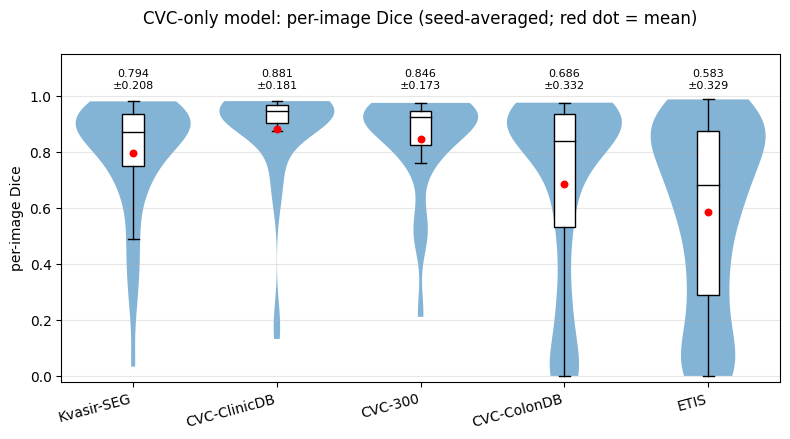

In [9]:
show_model_results("cvc_main", CVC_DIR, "CVC-only model")

## A3 — Polyp-size stratification + failure cases

,mean Dice,n images
Small,0.824,21.0
Medium,0.929,20.0
Large,0.938,21.0


size thresholds (pixels): (4525.59, 9050.120000000003)
tiny (<2.5% area): 14 images | mean Dice 0.784
per-image Dice mean/median/std: 0.897 0.945 0.125


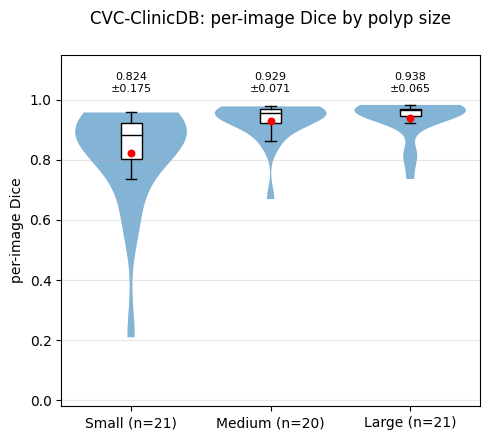

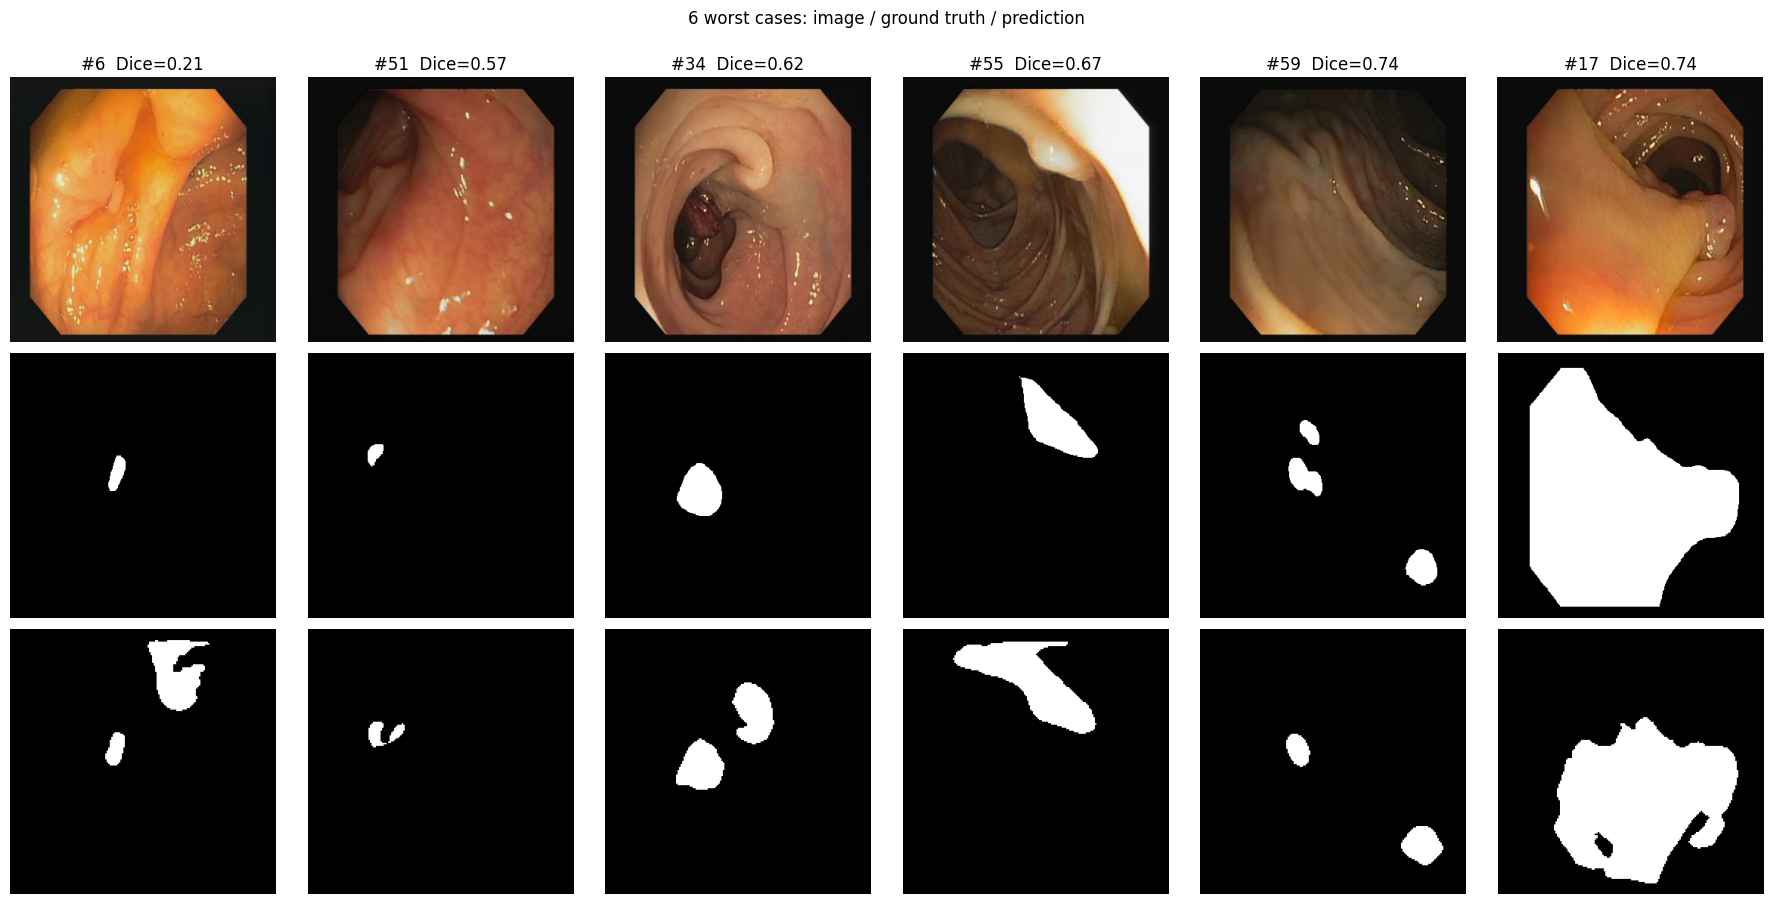

In [10]:
model = load_trained(build, f"{CVC_DIR}/cvc_main_seed{SEEDS[0]}.weights.h5")      # pehla seed
Xte, Yte = D["cvc"]["test"]
summ, per, probs = evaluate_arrays(model, Xte, Yte)
lab, frac, th = size_bins(Yte)
bins = dice_by_bin(per["dice"], lab)
display(pd.DataFrame({b: {"mean Dice": round(v[0], 3), "n images": v[1]} for b, v in bins.items()}).T)
print("size thresholds (pixels):", th)
tiny = frac < 0.025
print(f"tiny (<2.5% area): {int(tiny.sum())} images", f"| mean Dice {per['dice'][tiny].mean():.3f}" if tiny.any() else "")
print("per-image Dice mean/median/std:", round(per["dice"].mean(), 3), round(float(np.median(per["dice"])), 3), round(per["dice"].std(), 3))
violin_plot({f"{b} (n={v[1]})": per["dice"][lab == b] for b, v in bins.items()}, "CVC-ClinicDB: per-image Dice by polyp size")

worst = np.argsort(per["dice"])[:6]
fig, ax = plt.subplots(3, len(worst), figsize=(3 * len(worst), 9), squeeze=False)
for j, i in enumerate(worst):
    ax[0, j].imshow(Xte[i]); ax[0, j].set_title(f"#{i}  Dice={per['dice'][i]:.2f}")
    ax[1, j].imshow(Yte[i, ..., 0], cmap="gray"); ax[2, j].imshow(probs[i, ..., 0] > 0.5, cmap="gray")
    for r in range(3): ax[r, j].axis("off")
ax[0, 0].set_ylabel("image"); fig.suptitle("6 worst cases: image / ground truth / prediction", y=1.0)
plt.tight_layout(); plt.show()

## A4 — Robustness (poora test set, 5 corruptions × severity 0..5; 0 = clean)

,sev 0,sev 1,sev 2,sev 3,sev 4,sev 5
Gaussian Noise,0.897,0.861,0.841,0.727,0.559,0.351
Gaussian Blur,0.897,0.877,0.875,0.870,0.862,0.844
Brightness/Contrast,0.897,0.896,0.891,0.878,0.864,0.840
JPEG Compression,0.897,0.889,0.881,0.893,0.833,0.616
Motion Blur,0.897,0.866,0.837,0.789,0.721,0.661


,relative robustness (1.0 = no drop)
Gaussian Noise,0.745
Gaussian Blur,0.965
Brightness/Contrast,0.975
JPEG Compression,0.917
Motion Blur,0.864
overall,0.893


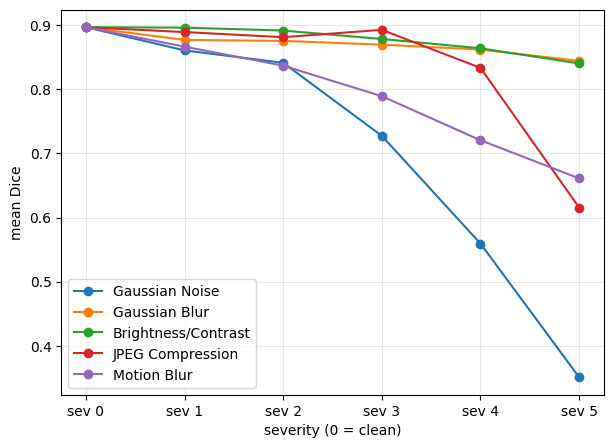

In [11]:
model = load_trained(build, f"{CVC_DIR}/cvc_main_seed{SEEDS[0]}.weights.h5")
Xte, Yte = D["cvc"]["test"]
rb = robustness_eval(model, Xte, Yte)
df = pd.DataFrame(rb, index=[0, 1, 2, 3, 4, 5]).T
df.columns = [f"sev {c}" for c in df.columns]
display(df.round(3))
display(pd.Series(relative_robustness(rb)).round(3).to_frame("relative robustness (1.0 = no drop)"))
df.T.plot(marker="o", figsize=(7, 5)); plt.xlabel("severity (0 = clean)"); plt.ylabel("mean Dice"); plt.grid(alpha=0.3); plt.show()

## A5 — Explainability: Grad-CAM++ (asli) + LIME + center/random baselines + deletion/insertion + model-randomisation check
Ek hi protocol (`xai_full_eval`): LIME 150 segments × 1000 samples, same layer, same n.

,method,metric,mean,ci95_low,ci95_high,n
0,gradcam++,pointing_game,0.9677,0.9194,1.0000,62
1,gradcam++,energy_pg,0.9316,0.8879,0.9641,62
2,gradcam++,iou_topg,0.8504,0.8081,0.8853,62
3,gradcam++,auroc,0.9905,0.9833,0.9957,62
4,gradcam++,auprc,0.9494,0.9145,0.9762,62
5,center_prior,pointing_game,0.2903,0.1774,0.4032,62
6,center_prior,energy_pg,0.1417,0.1104,0.1761,62
7,center_prior,iou_topg,0.1805,0.1278,0.2343,62
8,center_prior,auroc,0.8275,0.7927,0.8590,62
9,center_prior,auprc,0.3023,0.2343,0.3741,62


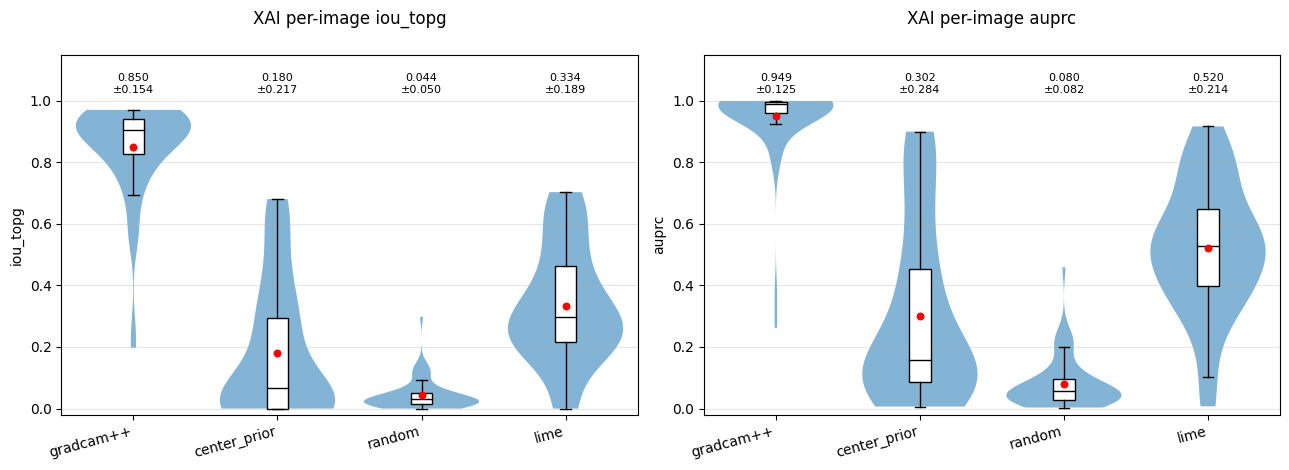

,mean over images
auprc_trained,0.932
spearman_random_all,0.048
auprc_random_all,0.106
spearman_random_decoder,0.199
auprc_random_decoder,0.117


In [8]:
model = load_trained(build, f"{CVC_DIR}/cvc_main_seed{SEEDS[0]}.weights.h5")
Xte, Yte = D["cvc"]["test"]
res_xai = xai_full_eval(model, Xte, Yte, n_gc=N_GC, n_lime=N_LIME, lime_segments=150, lime_samples=1000)
xai_tab = xai_report(res_xai)                       # mean + 95% bootstrap CI + n
display(xai_tab)

fig, axs = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, metric in zip(axs, ["iou_topg", "auprc"]):
    g = {m: pd.to_numeric(d[metric], errors="coerce").dropna().values for m, d in res_xai.items() if metric in d.columns}
    violin_plot(g, f"XAI per-image {metric}", ylabel=metric, ax=ax, rotate=15)
plt.tight_layout(); plt.show()

# Sanity check: trained Grad-CAM++ model-weights randomise karne par BADAL jana chahiye
rc = randomization_check(model, lambda: build_unet_resnet50(IMG_SIZE, weights=None), Xte, Yte, n=5 if QUICK_TEST else 20)
display(rc.mean().round(3).to_frame("mean over images"))

,method,metric,mean,ci95_low,ci95_high,n
0,gradcam++,pointing_game,0.9677,0.9194,1.0000,62
1,gradcam++,energy_pg,0.9316,0.8879,0.9641,62
2,gradcam++,iou_topg,0.8504,0.8081,0.8853,62
3,gradcam++,auroc,0.9905,0.9833,0.9957,62
4,gradcam++,auprc,0.9494,0.9145,0.9762,62
5,center_prior,pointing_game,0.2903,0.1774,0.4032,62
6,center_prior,energy_pg,0.1417,0.1104,0.1761,62
7,center_prior,iou_topg,0.1805,0.1278,0.2343,62
8,center_prior,auroc,0.8275,0.7927,0.8590,62
9,center_prior,auprc,0.3023,0.2343,0.3741,62


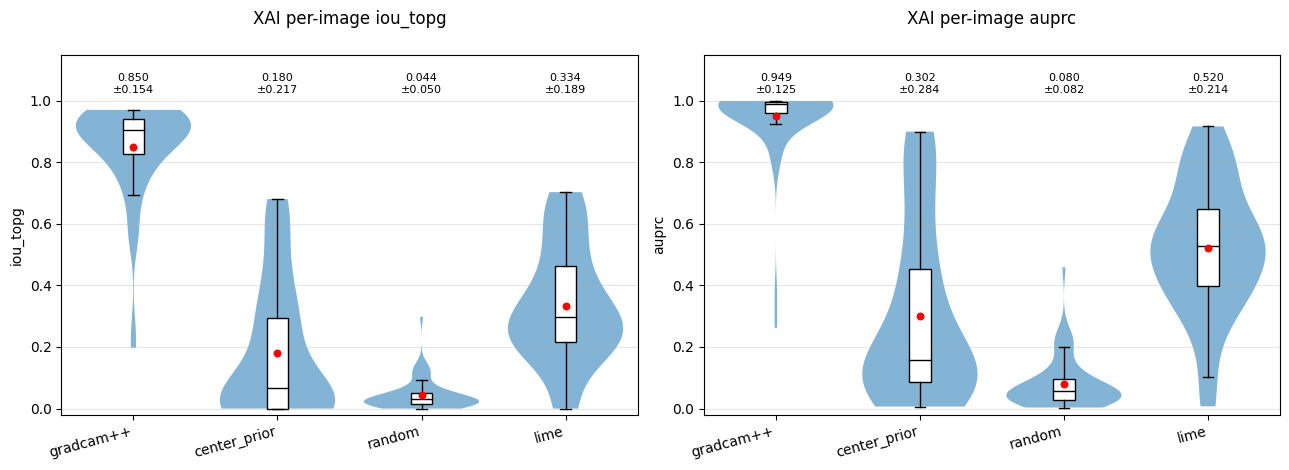

,mean over images
auprc_trained,0.932
spearman_random_all,0.048
auprc_random_all,0.106
spearman_random_decoder,0.199
auprc_random_decoder,0.117


In [9]:
display(xai_tab)
fig, axs = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, metric in zip(axs, ["iou_topg", "auprc"]):
    g = {m: pd.to_numeric(d[metric], errors="coerce").dropna().values for m, d in res_xai.items() if metric in d.columns}
    violin_plot(g, f"XAI per-image {metric}", ylabel=metric, ax=ax, rotate=15)
plt.tight_layout(); plt.show()
display(rc.mean().round(3).to_frame("mean over images"))

In [10]:
%matplotlib inline

In [11]:
import matplotlib
print(matplotlib.get_backend())

module://matplotlib_inline.backend_inline


### A5b — XAI figure (Image | GT | Prediction | Grad-CAM++ | LIME)  [best / median / worst case]

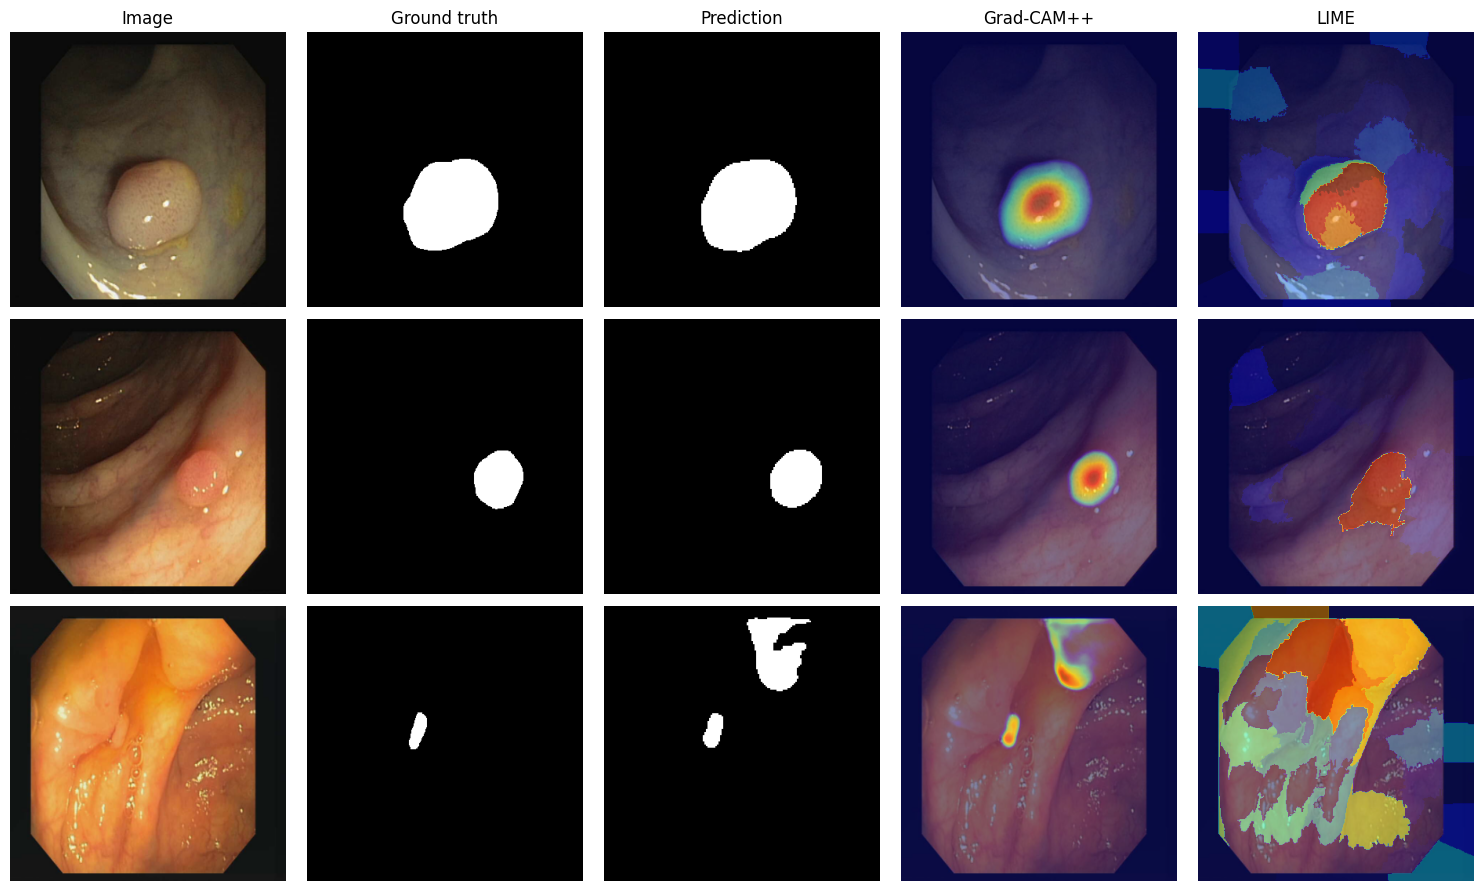

In [12]:
model = load_trained(build, f"{CVC_DIR}/cvc_main_seed{SEEDS[0]}.weights.h5")
Xte, Yte = D["cvc"]["test"]
_, per, _ = evaluate_arrays(model, Xte, Yte)
order = np.argsort(per["dice"]); idxs = [order[-1], order[len(order) // 2], order[0]]
xai_figure(model, Xte, Yte, idxs, lime_samples=300)

In [8]:
m = load_trained(build, f"{FED}/pooled_seed{SEEDS[0]}.weights.h5")
Xx = np.concatenate([TEST["kvasir"][0], TEST["cvc"][0]])
Yx = np.concatenate([TEST["kvasir"][1], TEST["cvc"][1]]); Xp = to_model_input(Xx)
rows = {l: [xai_metrics(gradcam_pp(m, Xp[j], layer_name=l), Yx[j]) for j in range(len(Xx))]
        for l in ("dec4_relu2", "conv5_block3_out")}
display(pd.DataFrame({l: pd.DataFrame(v).mean(numeric_only=True) for l, v in rows.items()}).round(3))

,dec4_relu2,conv5_block3_out
pointing_game,0.975,0.907
energy_pg,0.942,0.380
iou_topg,0.850,0.656
auroc,0.970,0.958
auprc,0.937,0.845


## A6 — Ablation: frozen encoder / no-ImageNet (paired Wilcoxon on seed-averaged per-image Dice + Holm + bootstrap CI)

Epoch 1/40
62/62 - 18s - loss: 0.4704 - dice_coef: 0.6317 - val_loss: 1.2900 - val_dice_coef: 0.2542 - lr: 1.0000e-04 - 18s/epoch - 298ms/step
Epoch 2/40
62/62 - 6s - loss: 0.3192 - dice_coef: 0.7674 - val_loss: 0.4211 - val_dice_coef: 0.7523 - lr: 1.0000e-04 - 6s/epoch - 104ms/step
Epoch 3/40
62/62 - 6s - loss: 0.2763 - dice_coef: 0.8096 - val_loss: 0.3530 - val_dice_coef: 0.7963 - lr: 1.0000e-04 - 6s/epoch - 102ms/step
Epoch 4/40
62/62 - 6s - loss: 0.2506 - dice_coef: 0.8327 - val_loss: 0.3166 - val_dice_coef: 0.7971 - lr: 1.0000e-04 - 6s/epoch - 103ms/step
Epoch 5/40
62/62 - 6s - loss: 0.2257 - dice_coef: 0.8509 - val_loss: 0.2855 - val_dice_coef: 0.8070 - lr: 1.0000e-04 - 6s/epoch - 104ms/step
Epoch 6/40
62/62 - 6s - loss: 0.2162 - dice_coef: 0.8518 - val_loss: 0.2266 - val_dice_coef: 0.8300 - lr: 1.0000e-04 - 6s/epoch - 103ms/step
Epoch 7/40
62/62 - 6s - loss: 0.1947 - dice_coef: 0.8718 - val_loss: 0.2142 - val_dice_coef: 0.8347 - lr: 1.0000e-04 - 6s/epoch - 103ms/step
Epoch 8/40


,config,mDice_mean,mDice_std_over_seeds,diff_vs_ref,diff_CI95,p_raw,p_holm
0,Proposed (fine-tuned),0.8805,0.0100,0.0000,"[0.000, 0.000]",NaN,NaN
1,Frozen encoder,0.8554,0.0091,-0.0252,"[-0.054, -0.002]",0.0678,0.0678
2,No ImageNet (scratch),0.7626,0.0126,-0.1180,"[-0.165, -0.077]",0.0000,0.0000


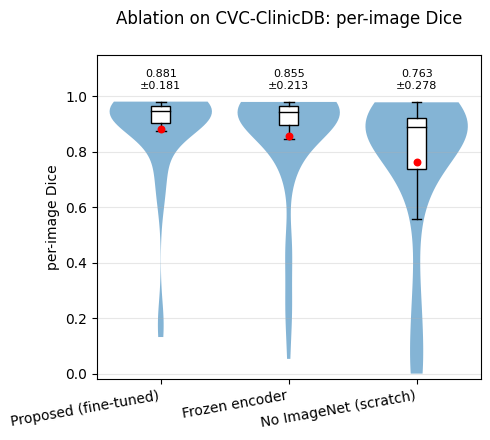

In [13]:
if RUN_ABLATION:
    free_gpu_memory()
    only = {"cvc": TEST["cvc"]}
    run_seeds("cvc_frozen",  SEEDS, lambda: build_unet_resnet50(IMG_SIZE, freeze_encoder=True), D["cvc"]["train"], D["cvc"]["val"], only, epochs=EP_CVC, batch=BATCH, out_dir=CVC_DIR)
    run_seeds("cvc_scratch", SEEDS, lambda: build_unet_resnet50(IMG_SIZE, weights=None),         D["cvc"]["train"], D["cvc"]["val"], only, epochs=EP_CVC, batch=BATCH, out_dir=CVC_DIR)
    per = {"Proposed (fine-tuned)": load_dice("cvc_main",    SEEDS, "cvc", CVC_DIR),
           "Frozen encoder":        load_dice("cvc_frozen",  SEEDS, "cvc", CVC_DIR),
           "No ImageNet (scratch)": load_dice("cvc_scratch", SEEDS, "cvc", CVC_DIR)}
    display(compare_table(per, "Proposed (fine-tuned)"))
    violin_plot({n: np.mean(np.stack(v), 0) for n, v in per.items()}, "Ablation on CVC-ClinicDB: per-image Dice", rotate=10)
else:
    print("RUN_ABLATION = False -> skip")

## A7 — Efficiency (params / FLOPs / latency) — 352 resolution par

In [14]:
model = load_trained(build, f"{CVC_DIR}/cvc_main_seed{SEEDS[0]}.weights.h5")
display(pd.DataFrame([efficiency_report(model, IMG_SIZE)]).round(3))   # FLOPs vs MACs ka unit published tables ke saath match karein

Instructions for updating:
This API was designed for TensorFlow v1. See https://www.tensorflow.org/guide/migrate for instructions on how to migrate your code to TensorFlow v2.


,params_M,gflops,latency_ms,fps
0,43.944,67.05,35.639,28.059


# PART B — Kvasir-SEG + 2-institution Federated Learning (isi notebook mein)

Reviewer ne **asli multi-institution** FL maanga tha. Yahan 2 "institutions" hain: client 0 = Kvasir-SEG (810 train images), client 1 = CVC-ClinicDB (495 train images).
Comparison: **Kvasir-only, CVC-only** (local), **Pooled** (dono data ek jagah = upper bound), **FedAvg, FedProx, FedBN**. Sab 5 test sets par (3 unseen).

**Total epochs sab rows mein barabar:** har config 40 epochs (Config: `EPOCHS`); FL mein 20 rounds × 2 local epochs = 40. Sab ImageNet weights se shuru, koi warm-start nahi, FedProx μ = 0.01.


In [3]:
import tensorflow as tf
gpus = tf.config.list_physical_devices("GPU")
print("GPUs:", gpus)
assert gpus, "GPU nazar nahi aa rahi, B4 mat chalao"
with tf.device("/GPU:0"):
    y = tf.keras.layers.Conv2D(8, 3)(tf.random.normal((2, 352, 352, 3)))
print("Device:", y.device)

GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Device: /job:localhost/replica:0/task:0/device:GPU:0


2026-10-06 10:52:56.641604: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1635] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 8114 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3080, pci bus id: 0000:23:00.0, compute capability: 8.6
2026-10-06 10:52:56.691412: I tensorflow/compiler/xla/stream_executor/cuda/cuda_dnn.cc:424] Loaded cuDNN version 8600


## B1 — Kvasir-only training

In [15]:
if RUN_KVASIR_AND_FED:
    free_gpu_memory()
    run_seeds("kvasir_main", SEEDS, build, D["kvasir"]["train"], D["kvasir"]["val"], TEST, epochs=EP_KV, batch=BATCH, out_dir=KV_DIR)
else:
    print("RUN_KVASIR_AND_FED = False -> skip")

Epoch 1/40
102/102 - 36s - loss: 0.3740 - dice_coef: 0.7243 - val_loss: 0.5526 - val_dice_coef: 0.7511 - lr: 1.0000e-04 - 36s/epoch - 355ms/step
Epoch 2/40
102/102 - 15s - loss: 0.2554 - dice_coef: 0.8224 - val_loss: 0.3106 - val_dice_coef: 0.8106 - lr: 1.0000e-04 - 15s/epoch - 148ms/step
Epoch 3/40
102/102 - 15s - loss: 0.2236 - dice_coef: 0.8443 - val_loss: 0.2331 - val_dice_coef: 0.8262 - lr: 1.0000e-04 - 15s/epoch - 148ms/step
Epoch 4/40
102/102 - 15s - loss: 0.2005 - dice_coef: 0.8584 - val_loss: 0.2014 - val_dice_coef: 0.8531 - lr: 1.0000e-04 - 15s/epoch - 144ms/step
Epoch 5/40
102/102 - 15s - loss: 0.1878 - dice_coef: 0.8658 - val_loss: 0.1884 - val_dice_coef: 0.8586 - lr: 1.0000e-04 - 15s/epoch - 148ms/step
Epoch 6/40
102/102 - 15s - loss: 0.1736 - dice_coef: 0.8701 - val_loss: 0.1689 - val_dice_coef: 0.8596 - lr: 1.0000e-04 - 15s/epoch - 149ms/step
Epoch 7/40
102/102 - 14s - loss: 0.1589 - dice_coef: 0.8811 - val_loss: 0.2062 - val_dice_coef: 0.8445 - lr: 1.0000e-04 - 14s/epoc

## B2 — Pooled (Kvasir + CVC ek saath, centralised)

In [16]:
if RUN_KVASIR_AND_FED:
    free_gpu_memory()
    POOL_TR = (np.concatenate([D["kvasir"]["train"][0], D["cvc"]["train"][0]]), np.concatenate([D["kvasir"]["train"][1], D["cvc"]["train"][1]]))
    POOL_VA = (np.concatenate([D["kvasir"]["val"][0],   D["cvc"]["val"][0]]),   np.concatenate([D["kvasir"]["val"][1],   D["cvc"]["val"][1]]))
    print("pooled train/val:", POOL_TR[0].shape[0], POOL_VA[0].shape[0])
    run_seeds("pooled", SEEDS, build, POOL_TR, POOL_VA, TEST, epochs=EP_POOL, batch=BATCH, out_dir=FED)

pooled train/val: 1305 145
Epoch 1/40
164/164 - 45s - loss: 0.3576 - dice_coef: 0.7312 - val_loss: 0.4417 - val_dice_coef: 0.7381 - lr: 1.0000e-04 - 45s/epoch - 274ms/step
Epoch 2/40
164/164 - 24s - loss: 0.2482 - dice_coef: 0.8216 - val_loss: 0.2357 - val_dice_coef: 0.8373 - lr: 1.0000e-04 - 24s/epoch - 144ms/step
Epoch 3/40
164/164 - 24s - loss: 0.2082 - dice_coef: 0.8438 - val_loss: 0.1899 - val_dice_coef: 0.8388 - lr: 1.0000e-04 - 24s/epoch - 146ms/step
Epoch 4/40
164/164 - 24s - loss: 0.1867 - dice_coef: 0.8560 - val_loss: 0.1738 - val_dice_coef: 0.8670 - lr: 1.0000e-04 - 24s/epoch - 145ms/step
Epoch 5/40
164/164 - 23s - loss: 0.1634 - dice_coef: 0.8727 - val_loss: 0.2085 - val_dice_coef: 0.8413 - lr: 1.0000e-04 - 23s/epoch - 138ms/step
Epoch 6/40
164/164 - 23s - loss: 0.1547 - dice_coef: 0.8733 - val_loss: 0.1873 - val_dice_coef: 0.8501 - lr: 1.0000e-04 - 23s/epoch - 139ms/step
Epoch 7/40
164/164 - 23s - loss: 0.1510 - dice_coef: 0.8724 - val_loss: 0.1670 - val_dice_coef: 0.8445 

## B3 — Kvasir-only aur Pooled: mean ± SD + violin plots

=== Kvasir-only model: mean ± SD over 5 seeds ===


,test_set,n_images,mDice (mean ± SD over seeds),mIoU (mean ± SD over seeds),per-image Dice SD,95% CI (bootstrap)
0,Kvasir-SEG,100,0.889 ± 0.008,0.834 ± 0.010,0.174,"[0.852, 0.921]"
1,CVC-ClinicDB,62,0.740 ± 0.035,0.672 ± 0.031,0.303,"[0.660, 0.811]"
2,CVC-300,60,0.842 ± 0.026,0.770 ± 0.027,0.188,"[0.793, 0.885]"
3,CVC-ColonDB,380,0.603 ± 0.035,0.538 ± 0.031,0.374,"[0.565, 0.640]"
4,ETIS,196,0.554 ± 0.034,0.501 ± 0.032,0.394,"[0.499, 0.609]"


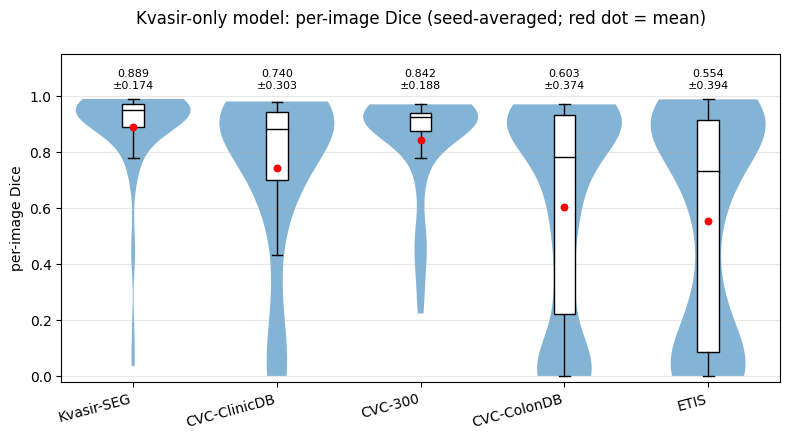

=== Pooled (Kvasir + CVC) model: mean ± SD over 5 seeds ===


,test_set,n_images,mDice (mean ± SD over seeds),mIoU (mean ± SD over seeds),per-image Dice SD,95% CI (bootstrap)
0,Kvasir-SEG,100,0.887 ± 0.011,0.830 ± 0.011,0.170,"[0.850, 0.917]"
1,CVC-ClinicDB,62,0.883 ± 0.012,0.832 ± 0.012,0.202,"[0.828, 0.928]"
2,CVC-300,60,0.880 ± 0.008,0.809 ± 0.011,0.132,"[0.845, 0.910]"
3,CVC-ColonDB,380,0.696 ± 0.010,0.630 ± 0.009,0.341,"[0.661, 0.729]"
4,ETIS,196,0.622 ± 0.034,0.564 ± 0.029,0.372,"[0.569, 0.674]"


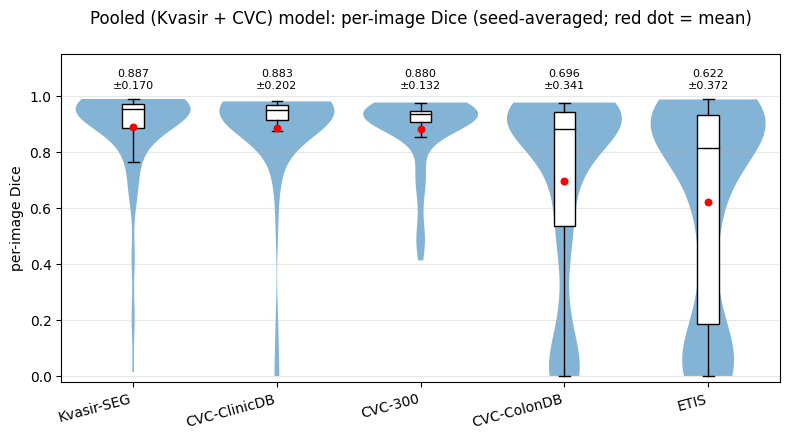

In [17]:
show_model_results("kvasir_main", KV_DIR, "Kvasir-only model")
show_model_results("pooled", FED, "Pooled (Kvasir + CVC) model")

In [3]:
# ===== PATCH v2 (B4 se PEHLE ek baar chalayein): OOM-safe run_federated (cuDNN "No algorithm worked" bhi pakadta hai) =====
import gc
from tf_utils import _make_prox_loss
for _n in ("model", "m", "worker"): globals().pop(_n, None)       # purane analysis cells ke GPU models (ye cells apna model khud dobara load karte hain)
free_gpu_memory(); gc.collect()

def run_federated(build_fn, client_ds, client_sizes, client_steps, val_sets, rounds, local_epochs,
                  lr=1e-4, mode="fedavg", seed=42, log=print, mu=0.01):
    """Same as before + OOM fallback: agar GPU memory kam pade (ResourceExhaustedError) to us client ka local batch aadha ho jata hai
    aur steps double (epoch mein wahi images). cuDNN "No algorithm worked" (memory) bhi isi tarah sambhalta hai. Kuch OOM na ho to bilkul purane jaisa (batch 8)."""
    set_seed(seed)
    worker = compile_model(build_fn(), lr)               # one reusable worker -> low memory
    bn_idx = bn_weight_indices(worker)
    bn_set = set(bn_idx)
    init = worker.get_weights()
    n = len(client_ds)
    frac = [s / float(sum(client_sizes)) for s in client_sizes]
    glob = [w.copy() for w in init]
    client_bn = [{i: init[i].copy() for i in bn_idx} for _ in range(n)]
    history = []
    div = [1] * n                                        # per-client batch divider (OOM fallback)
    loss_fn = lambda: _make_prox_loss(worker, glob, mu) if mode == "fedprox" else None
    for r in range(rounds):
        local = []
        for c in range(n):
            while True:
                worker.set_weights(client_weights(glob, client_bn, bn_idx, c, mode))
                compile_model(worker, lr, loss=loss_fn())   # fresh optimiser each round
                b0 = max(1, int(round(client_sizes[c] / float(client_steps[c]))))       # original batch size
                b, st = max(1, b0 // div[c]), client_steps[c] * div[c]
                ds_c = client_ds[c] if div[c] == 1 else client_ds[c].unbatch().batch(b).prefetch(tf.data.AUTOTUNE)
                try:
                    worker.fit(ds_c, epochs=local_epochs, steps_per_epoch=st, verbose=0)
                    break
                except (tf.errors.ResourceExhaustedError, tf.errors.NotFoundError, tf.errors.InternalError, tf.errors.UnknownError) as e:
                    msg = str(e)                      # cuDNN autotune ko workspace na mile to error NotFound/Unknown ban kar aata hai ("No algorithm worked")
                    if b <= 1 or not any(t in msg for t in ("RESOURCE_EXHAUSTED", "Out of memory", "OOM", "No algorithm worked", "failed to allocate", "scratch space")):
                        raise
                    import gc; gc.collect()
                    div[c] *= 2
                    log(f"[{mode}] GPU OOM (client {c}): local batch {b} -> {max(1, b0 // div[c])}, steps x2 (epoch mein wahi images)")
            local.append(worker.get_weights())
        new_glob = []
        for i in range(len(glob)):
            if mode == "fedbn" and i in bn_set:
                new_glob.append(glob[i])
            else:
                new_glob.append(sum(frac[c] * local[c][i] for c in range(n)))
        if mode == "fedbn":
            client_bn = [{i: local[c][i] for i in bn_idx} for c in range(n)]
        glob = new_glob
        dices = []
        for c in range(n):
            worker.set_weights(client_weights(glob, client_bn, bn_idx, c, mode))
            dices.append(float(worker.evaluate(val_sets[c], verbose=0, return_dict=True)["dice_coef"]))
        history.append({"round": r + 1, "val_dice_per_client": dices, "val_dice_mean": float(np.mean(dices))})
        log(f"[{mode}] round {r + 1}/{rounds}  val dice per client: {[round(d, 4) for d in dices]}")
        import gc; gc.collect()
    del worker
    free_gpu_memory()                                     # GPU memory wapas, taake eval_federated ko jagah mile
    return {"glob": glob, "client_bn": client_bn, "bn_idx": bn_idx, "history": history}

print("run_federated patched v2: GPU memory kam pade to local batch khud aadha ho jayega")

run_federated patched v2: GPU memory kam pade to local batch khud aadha ho jayega


In [20]:
# ===== GPU memory cleanup (kernel restart ke bagair) =====
import sys, gc
sys.last_type = sys.last_value = sys.last_traceback = None      # pichle error ka traceback purane 'worker' model ko GPU memory mein pakde rakhta hai
try:
    _ip = get_ipython()
    for _k in ("_", "__", "___"): _ip.user_ns[_k] = None
    _ip.user_ns["Out"].clear()                                   # cell outputs ka cache
except Exception as _e:
    print("ipython cache:", _e)
for _n in ("model", "m", "worker", "out", "res", "fed_model"): globals().pop(_n, None)
gc.collect(); free_gpu_memory(); gc.collect()
_live = [k for k, v in list(globals().items()) if isinstance(v, tf.keras.Model)]
print("Kernel mein abhi bhi Keras model wale variables:", _live)
_mi = tf.config.experimental.get_memory_info("GPU:0")
print(f"TF GPU memory ab: current {_mi['current'] / 2**20:.0f} MiB | peak {_mi['peak'] / 2**20:.0f} MiB")

Kernel mein abhi bhi Keras model wale variables: []
TF GPU memory ab: current 4441 MiB | peak 7954 MiB


## B4 — Federated training: 2 institutions, NO warm-start. FedAvg / FedProx / FedBN
Har (mode, seed) ke baad weights + results disk par save; dobara run karne par SKIP.

In [5]:
# ===== B4 REPLACEMENT (FIXED): paste this WHOLE file into the existing B4 cell =====
# Sirf B4 cell badalta hai. Upar ke cells, helper files, B5/B6/Part C/Part D: koi change nahi.
# Same BATCH(8), image size, seeds, rounds, local epochs, architecture, loss, FedProx mu=0.01.
# Same output files / .npz keys, isliye B5, B6, C, D bina change ke chalenge.
#
# GPU OOM ki asli wajah: purane run_federated ne HAR client, HAR round par naya compile
# (naya Adam optimizer + naya train graph) banaya -> GPU memory round dar round bharti gayi.
# Ab: ek hi worker, ek hi compile, ek hi Adam (har client se pehle uska state reset).
# Phir bhi GPU error aaye to: GPU par hi dobara (last COMPLETED round se, random weights se nahi);
# CPU sirf aakhri raasta (bohat slow).

import gc as _b4_gc
import json as _b4_json
import sys as _b4_sys
import os as _b4_os
import numpy as _b4_np
import tensorflow as _b4_tf
import tf_utils as _b4_u

_B4_MAX_GPU_STALLS = 2      # lagataar itni GPU koshishein bina naya round complete kiye -> tab CPU
_B4_BASE_WARN_MIB = 1500    # training se pehle GPU par itni memory pehle se bhari ho to warning


def _b4_clean():
    _b4_tf.keras.backend.clear_session()
    _b4_gc.collect()


def _b4_gpu_error(error):
    if isinstance(error, _b4_tf.errors.ResourceExhaustedError):
        return True
    message = str(error).lower()
    return any(text in message for text in (
        "out of memory", "oom when", "failed to allocate", "cuda_error",
        "cuda error", "cudnn", "cublas", "no algorithm worked",
        "dnn library", "streamexecutor", "failed call to cuinit",
    ))


def _b4_mem_mib():
    """TF ke andar GPU par abhi live memory (MiB); GPU na ho to None."""
    try:
        return _b4_tf.config.experimental.get_memory_info("GPU:0")["current"] / 2.0 ** 20
    except Exception:
        return None


def fl_done(mode, seed):
    prefix = _b4_os.path.join(FED, f"fl_{mode}_seed{seed}")
    weights = ([prefix + f"_client{c}.weights.h5" for c in range(2)]
               if mode == "fedbn" else [prefix + ".weights.h5"])
    return (_b4_os.path.isfile(prefix + ".npz")
            and all(_b4_os.path.isfile(path) for path in weights))


def _b4_train(mode, seed, device, state):
    """Ek compiled worker; har client se pehle sirf Adam state reset (recompile nahi)."""
    _b4_u.set_seed(seed)
    clients = ("kvasir", "cvc")
    sizes = [len(D[k]["train"][0]) for k in clients]
    steps = [max(1, n // BATCH) for n in sizes]  # original B4 epoch definition
    fractions = [n / float(sum(sizes)) for n in sizes]

    # Poora dataset aur input pipeline CPU par; GPU par sirf ek batch aata hai.
    with _b4_tf.device("/CPU:0"):
        train_sets = [
            _b4_u.make_tf_ds(*D[k]["train"], BATCH, training=True,
                            repeat=True, seed=seed)
            for k in clients
        ]
        val_sets = [_b4_u.make_tf_ds(*D[k]["val"], BATCH) for k in clients]

    with _b4_tf.device(device):
        worker = build()
        bn_idx = _b4_u.bn_weight_indices(worker)
        bn_set = set(bn_idx)

        if not state:
            initial = worker.get_weights()  # NumPy arrays: host RAM mein
            state.update(
                glob=initial,
                client_bn=[{i: initial[i].copy() for i in bn_idx}
                           for _ in clients],
                bn_idx=bn_idx,
                history=[],
            )
        if bn_idx != state["bn_idx"]:
            raise ValueError("B4: rebuilt model ka BatchNorm weight order badal gaya.")

        optimizer = _b4_tf.keras.optimizers.Adam(
            learning_rate=1e-4, jit_compile=False
        )
        optimizer.build(worker.trainable_variables)
        opt_vars = optimizer.variables
        opt_vars = list(opt_vars() if callable(opt_vars) else opt_vars)
        initial_opt = [v.numpy().copy() for v in opt_vars]

        # FedProx: global weights ke reference VARIABLES hain (har round assign),
        # naye constants / naya graph har client-round par nahi banta.
        refs, train_idx = [], []
        loss_fn = _b4_u.bce_dice_loss
        if mode == "fedprox":
            weight_idx = {id(v): i for i, v in enumerate(worker.weights)}
            train_idx = [weight_idx[id(v)] for v in worker.trainable_variables]
            refs = [
                _b4_tf.Variable(state["glob"][i], trainable=False, dtype=v.dtype)
                for v, i in zip(worker.trainable_variables, train_idx)
            ]
            train_vars = list(worker.trainable_variables)

            def loss_fn(y_true, y_pred):
                penalty = _b4_tf.add_n([
                    _b4_tf.reduce_sum(_b4_tf.square(v - ref))
                    for v, ref in zip(train_vars, refs)
                ])
                # original FedProx: (mu/2) * ||w - w_g||^2 with mu = 0.01
                return _b4_u.bce_dice_loss(y_true, y_pred) + 0.005 * penalty

        worker.compile(optimizer=optimizer, loss=loss_fn,
                       metrics=[_b4_u.dice_coef], jit_compile=False)

        for round_id in range(len(state["history"]), FL_ROUNDS):
            global_weights = state["glob"]
            local_weights = []

            for ref, index in zip(refs, train_idx):
                ref.assign(global_weights[index])

            for client in range(len(clients)):
                worker.set_weights(_b4_u.client_weights(
                    global_weights, state["client_bn"], bn_idx, client, mode
                ))
                # fresh Adam (har client/round), bina naya optimizer/graph banaye
                for variable, value in zip(opt_vars, initial_opt):
                    variable.assign(value)
                worker.reset_metrics()
                worker.fit(train_sets[client], epochs=FL_LOCAL_EP,
                           steps_per_epoch=steps[client], verbose=0)
                local_weights.append(worker.get_weights())

            merged = [
                global_weights[i] if mode == "fedbn" and i in bn_set
                else sum(fractions[c] * local_weights[c][i]
                         for c in range(len(clients)))
                for i in range(len(global_weights))
            ]
            client_bn = (
                [{i: local_weights[c][i].copy() for i in bn_idx}
                 for c in range(len(clients))]
                if mode == "fedbn" else state["client_bn"]
            )
            val_dice = []
            for client in range(len(clients)):
                worker.set_weights(_b4_u.client_weights(
                    merged, client_bn, bn_idx, client, mode
                ))
                metrics = worker.evaluate(val_sets[client], verbose=0,
                                          return_dict=True)
                val_dice.append(float(metrics["dice_coef"]))

            # SIRF poora hua round commit hota hai. Beech mein fail ho to
            # yehi host-RAM state se agla attempt wahin se resume karta hai.
            state["glob"] = merged
            state["client_bn"] = client_bn
            state["history"].append({
                "round": round_id + 1,
                "val_dice_per_client": val_dice,
                "val_dice_mean": float(_b4_np.mean(val_dice)),
            })
            mem = _b4_mem_mib() if device.startswith("/GPU") else None
            mem_txt = f" | GPU live {mem:.0f} MiB" if mem is not None else ""
            print(f"[{mode} seed {seed}] {device} | round "
                  f"{round_id + 1}/{FL_ROUNDS} | val Dice: "
                  f"{[round(x, 4) for x in val_dice]}{mem_txt}", flush=True)
            del local_weights
            _b4_gc.collect()


def _b4_finish(mode, seed, state, has_gpu):
    """Test-set evaluation (GPU pehle, GPU error par CPU), phir weights save, npz sab se AAKHIR mein."""
    plan = ([("/GPU:0", 4)] if has_gpu else []) + [("/CPU:0", 8)]
    result = None
    for device, bs in plan:
        _b4_clean()
        try:
            with _b4_tf.device(device):
                result = _b4_u.eval_federated(
                    build, state, mode, TEST,
                    client_for_set={"kvasir": 0, "cvc": 1}, bs=bs
                )
            break
        except _b4_tf.errors.OpError as error:
            if device == "/CPU:0" or not _b4_gpu_error(error):
                raise
            print(f"[{mode} seed {seed}] eval GPU par fail -> CPU par eval "
                  f"(slow, par training result safe hai).", flush=True)
    _b4_clean()
    with _b4_tf.device("/CPU:0"):   # sirf weights set + save; GPU ki zaroorat nahi
        _b4_u.save_fed_models(
            build, state, mode,
            _b4_os.path.join(FED, f"fl_{mode}_seed{seed}")
        )
    _b4_clean()
    # FL curves ke liye: har round ka val Dice. Alag file (.json): B5/B6/C/D ko ye nazar nahi aati.
    # npz (completion marker) se PEHLE likhi jati hai, to har "done" run ki history maujood hoti hai.
    with open(_b4_os.path.join(FED, f"fl_{mode}_seed{seed}_history.json"), "w") as fh:
        _b4_json.dump(state["history"], fh)
    # Same file names / keys jo B5, B6, C aur D padhte hain. Completion marker AAKHIR mein.
    _b4_u.save_fed_result(f"fl_{mode}", seed, result, FED)
    return result


def _b4_main():
    if not RUN_KVASIR_AND_FED:
        print("RUN_KVASIR_AND_FED = False -> skip")
        return

    # PICHLE fail hue cell ka exception purane GPU model ko memory mein pakde rakhta hai;
    # usay chhodte hain. Aapka data, models aur outputs delete NAHI hote.
    for name in ("last_type", "last_value", "last_traceback", "last_exc"):
        if hasattr(_b4_sys, name):
            setattr(_b4_sys, name, None)
    try:
        last = get_ipython().last_execution_result
        if last is not None:
            last.error_in_exec = None
            last.error_before_exec = None
    except (NameError, AttributeError):
        pass
    _b4_clean()

    has_gpu = bool(_b4_tf.config.list_physical_devices("GPU"))
    _b4_os.makedirs(FED, exist_ok=True)
    print(f"B4: batch={BATCH}, size={IMG_SIZE}, rounds={FL_ROUNDS}, "
          f"local epochs={FL_LOCAL_EP}. GPU first; GPU retry; CPU sirf aakhri raasta.")

    base = _b4_mem_mib() if has_gpu else None
    if base is not None:
        print(f"B4: training se pehle GPU par live memory = {base:.0f} MiB")
        if base > _B4_BASE_WARN_MIB:
            print("   WARNING: purane cells ke objects GPU memory pakde hue hain. "
                  "Agar neeche baar-baar OOM aaye: Kernel -> Restart, phir sirf env "
                  "(CUDA_VISIBLE_DEVICES wale chhote cells) + C0 + B4 chalayein. "
                  "Upar ke training cells dobara chalane ki zaroorat nahi "
                  "(results disk par hain, done runs SKIP hote hain).", flush=True)

    for seed in SEEDS:
        for mode in ("fedavg", "fedprox", "fedbn"):
            if fl_done(mode, seed):
                print(f"[fl_{mode} seed {seed}] pehle se trained -> SKIP")
                continue

            state = {}
            use_cpu = not has_gpu
            stalls = 0
            while True:
                device = "/CPU:0" if use_cpu else "/GPU:0"
                rounds_before = len(state.get("history", []))
                _b4_clean()
                try:
                    _b4_train(mode, seed, device, state)
                    break
                except _b4_tf.errors.OpError as error:
                    if use_cpu or not _b4_gpu_error(error):
                        raise  # data / code / CPU-memory errors kabhi nahi chhupate
                    reason = (str(error).strip().splitlines() or ["?"])[0][:140]
                # (except block khatam: purana exception aur uska GPU model ab free)
                done_rounds = len(state.get("history", []))
                stalls = 0 if done_rounds > rounds_before else stalls + 1
                if stalls >= _B4_MAX_GPU_STALLS:
                    use_cpu = True
                    print(f"[{mode} seed {seed}] GPU {stalls} baar lagataar bina naye round "
                          f"ke fail ({reason}). CPU par jaa raha hun round {done_rounds + 1} se. "
                          f"WARNING: CPU par ek round GHANTON le sakta hai. Behtar: Stop karke "
                          f"Kernel Restart + env cells + C0 + B4 (complete runs disk par safe).",
                          flush=True)
                else:
                    print(f"[{mode} seed {seed}] GPU memory/runtime error ({reason}). "
                          f"Cleanup ke baad GPU par hi round {done_rounds + 1} se retry "
                          f"(batch {BATCH} hi rahega).", flush=True)
            _b4_clean()

            result = _b4_finish(mode, seed, state, has_gpu)
            print(f"[fl_{mode} seed {seed}] DONE:",
                  {NAMES[k]: round(float(v[0].mean()), 4)
                   for k, v in result.items()}, flush=True)
            del state, result
            _b4_clean()


_b4_main()

B4: batch=8, size=352, rounds=20, local epochs=2. GPU first; GPU retry; CPU sirf aakhri raasta.
B4: training se pehle GPU par live memory = 0 MiB


2026-10-07 04:45:31.007555: I tensorflow/core/common_runtime/gpu/gpu_process_state.cc:226] Using CUDA malloc Async allocator for GPU: 0
2026-10-07 04:45:31.007625: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1635] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 8114 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3080, pci bus id: 0000:23:00.0, compute capability: 8.6
2026-10-07 04:45:42.644952: I tensorflow/compiler/xla/stream_executor/cuda/cuda_dnn.cc:424] Loaded cuDNN version 8600
2026-10-07 04:46:43.153548: I tensorflow/compiler/xla/stream_executor/cuda/cuda_blas.cc:637] TensorFloat-32 will be used for the matrix multiplication. This will only be logged once.


[fedavg seed 42] /GPU:0 | round 1/20 | val Dice: [0.8576, 0.8052] | GPU live 502 MiB
[fedavg seed 42] /GPU:0 | round 2/20 | val Dice: [0.8591, 0.8291] | GPU live 502 MiB
[fedavg seed 42] /GPU:0 | round 3/20 | val Dice: [0.8748, 0.847] | GPU live 502 MiB
[fedavg seed 42] /GPU:0 | round 4/20 | val Dice: [0.8737, 0.8522] | GPU live 502 MiB
[fedavg seed 42] /GPU:0 | round 5/20 | val Dice: [0.8954, 0.8456] | GPU live 502 MiB
[fedavg seed 42] /GPU:0 | round 6/20 | val Dice: [0.8841, 0.8666] | GPU live 502 MiB
[fedavg seed 42] /GPU:0 | round 7/20 | val Dice: [0.871, 0.8676] | GPU live 502 MiB
[fedavg seed 42] /GPU:0 | round 8/20 | val Dice: [0.913, 0.8656] | GPU live 502 MiB
[fedavg seed 42] /GPU:0 | round 9/20 | val Dice: [0.8962, 0.8646] | GPU live 502 MiB
[fedavg seed 42] /GPU:0 | round 10/20 | val Dice: [0.8844, 0.8628] | GPU live 502 MiB
[fedavg seed 42] /GPU:0 | round 11/20 | val Dice: [0.8954, 0.8761] | GPU live 502 MiB
[fedavg seed 42] /GPU:0 | round 12/20 | val Dice: [0.8877, 0.8642]

[fl_fedavg seed 42] DONE: {'Kvasir-SEG': 0.8821, 'CVC-ClinicDB': 0.8494, 'CVC-300': 0.8692, 'CVC-ColonDB': 0.6665, 'ETIS': 0.6434}


[fedprox seed 42] /GPU:0 | round 1/20 | val Dice: [0.8442, 0.7799] | GPU live 717 MiB
[fedprox seed 42] /GPU:0 | round 2/20 | val Dice: [0.8699, 0.8283] | GPU live 717 MiB
[fedprox seed 42] /GPU:0 | round 3/20 | val Dice: [0.8824, 0.8259] | GPU live 717 MiB
[fedprox seed 42] /GPU:0 | round 4/20 | val Dice: [0.8808, 0.8165] | GPU live 717 MiB
[fedprox seed 42] /GPU:0 | round 5/20 | val Dice: [0.8732, 0.8401] | GPU live 717 MiB
[fedprox seed 42] /GPU:0 | round 6/20 | val Dice: [0.8959, 0.8525] | GPU live 717 MiB
[fedprox seed 42] /GPU:0 | round 7/20 | val Dice: [0.8862, 0.8617] | GPU live 717 MiB
[fedprox seed 42] /GPU:0 | round 8/20 | val Dice: [0.8694, 0.8399] | GPU live 717 MiB
[fedprox seed 42] /GPU:0 | round 9/20 | val Dice: [0.879, 0.8483] | GPU live 717 MiB
[fedprox seed 42] /GPU:0 | round 10/20 | val Dice: [0.906, 0.8722] | GPU live 717 MiB
[fedprox seed 42] /GPU:0 | round 11/20 | val Dice: [0.9064, 0.8764] | GPU live 717 MiB
[fedprox seed 42] /GPU:0 | round 12/20 | val Dice: [0.

...

 Reported by CUDA: Free memory/Total memory: 185532416/10354753536

	 [[{{node gradient_tape/resnet50_unet/seg_out/Conv2D/Conv2DBackpropInput}}]]
Hint: If you want to see a list of allocated tensors when OOM happens, add report_tensor_allocations_upon_oom to RunOptions for current allocation info. This isn't available when running in Eager mode.



[fedprox seed 99] /GPU:0 | round 12/20 | val Dice: [0.884, 0.8646] | GPU live 717 MiB
[fedprox seed 99] /GPU:0 | round 13/20 | val Dice: [0.8774, 0.8556] | GPU live 717 MiB
[fedprox seed 99] /GPU:0 | round 14/20 | val Dice: [0.8924, 0.8571] | GPU live 717 MiB
[fedprox seed 99] /GPU:0 | round 15/20 | val Dice: [0.9027, 0.8626] | GPU live 717 MiB
[fedprox seed 99] /GPU:0 | round 16/20 | val Dice: [0.9083, 0.8896] | GPU live 717 MiB
[fedprox seed 99] /GPU:0 | round 17/20 | val Dice: [0.9025, 0.8628] | GPU live 717 MiB
[fedprox seed 99] /GPU:0 | round 18/20 | val Dice: [0.91, 0.8807] | GPU live 717 MiB
[fedprox seed 99] /GPU:0 | round 19/20 | val Dice: [0.9117, 0.8717] | GPU live 717 MiB
[fedprox seed 99] /GPU:0 | round 20/20 | val Dice: [0.9181, 0.8889] | GPU live 717 MiB


[fl_fedprox seed 99] DONE: {'Kvasir-SEG': 0.8829, 'CVC-ClinicDB': 0.8372, 'CVC-300': 0.8721, 'CVC-ColonDB': 0.6459, 'ETIS': 0.6244}


[fedbn seed 99] /GPU:0 | round 1/20 | val Dice: [0.846, 0.6153] | GPU live 502 MiB
[fedbn seed 99] /GPU:0 | round 2/20 | val Dice: [0.8809, 0.7548] | GPU live 502 MiB
[fedbn seed 99] /GPU:0 | round 3/20 | val Dice: [0.884, 0.8242] | GPU live 502 MiB
[fedbn seed 99] /GPU:0 | round 4/20 | val Dice: [0.8953, 0.8415] | GPU live 502 MiB
[fedbn seed 99] /GPU:0 | round 5/20 | val Dice: [0.897, 0.8712] | GPU live 502 MiB
[fedbn seed 99] /GPU:0 | round 6/20 | val Dice: [0.889, 0.8314] | GPU live 502 MiB
[fedbn seed 99] /GPU:0 | round 7/20 | val Dice: [0.9083, 0.8434] | GPU live 502 MiB
[fedbn seed 99] /GPU:0 | round 8/20 | val Dice: [0.8967, 0.8586] | GPU live 502 MiB
[fedbn seed 99] /GPU:0 | round 9/20 | val Dice: [0.9027, 0.8507] | GPU live 502 MiB
[fedbn seed 99] /GPU:0 | round 10/20 | val Dice: [0.8825, 0.8686] | GPU live 502 MiB
[fedbn seed 99] /GPU:0 | round 11/20 | val Dice: [0.905, 0.8875] | GPU live 502 MiB
[fedbn seed 99] /GPU:0 | round 12/20 | val Dice: [0.8962, 0.8586] | GPU live 50

[fl_fedbn seed 99] DONE: {'Kvasir-SEG': 0.8721, 'CVC-ClinicDB': 0.832, 'CVC-300': 0.8569, 'CVC-ColonDB': 0.6587, 'ETIS': 0.6238}


## B5 — FL vs Pooled vs local-only: har test set par (paired Wilcoxon + Holm + CI) + violin plots

Models: ['CVC-only', 'Kvasir-only', 'Pooled (central)', 'FedAvg', 'FedProx', 'FedBN'] | reference = Pooled (central)

--- Kvasir-SEG  (in-domain: ek client ka apna test set) ---


,config,mDice_mean,mDice_std_over_seeds,diff_vs_ref,diff_CI95,p_raw,p_holm
0,Pooled (central),0.8868,0.0106,0.0000,"[0.000, 0.000]",NaN,NaN
1,CVC-only,0.7941,0.0089,-0.0926,"[-0.122, -0.067]",0.0000,0.0000
2,Kvasir-only,0.8891,0.0082,0.0023,"[-0.006, 0.012]",0.2788,0.8363
3,FedAvg,0.8812,0.0171,-0.0056,"[-0.015, 0.003]",0.5247,0.8363
4,FedProx,0.8817,0.0033,-0.0051,"[-0.014, 0.004]",0.0004,0.0017
5,FedBN,0.8785,0.0101,-0.0082,"[-0.022, 0.003]",0.2803,0.8363



--- CVC-ClinicDB  (in-domain: ek client ka apna test set) ---


,config,mDice_mean,mDice_std_over_seeds,diff_vs_ref,diff_CI95,p_raw,p_holm
0,Pooled (central),0.8834,0.0123,0.0000,"[0.000, 0.000]",NaN,NaN
1,CVC-only,0.8805,0.0100,-0.0029,"[-0.017, 0.011]",0.7711,0.7711
2,Kvasir-only,0.7400,0.0354,-0.1434,"[-0.198, -0.096]",0.0000,0.0000
3,FedAvg,0.8322,0.0199,-0.0512,"[-0.087, -0.022]",0.0000,0.0000
4,FedProx,0.8332,0.0073,-0.0502,"[-0.085, -0.023]",0.0000,0.0000
5,FedBN,0.8532,0.0153,-0.0302,"[-0.053, -0.012]",0.0000,0.0000



--- CVC-300  (UNSEEN (zero-shot)) ---


,config,mDice_mean,mDice_std_over_seeds,diff_vs_ref,diff_CI95,p_raw,p_holm
0,Pooled (central),0.8799,0.0081,0.0000,"[0.000, 0.000]",NaN,NaN
1,CVC-only,0.8457,0.0345,-0.0342,"[-0.057, -0.014]",0.0257,0.0514
2,Kvasir-only,0.8418,0.0258,-0.0380,"[-0.064, -0.016]",0.0002,0.0012
3,FedAvg,0.8627,0.0185,-0.0172,"[-0.034, -0.003]",0.0065,0.0258
4,FedProx,0.8830,0.0142,0.0031,"[-0.006, 0.014]",0.5859,0.5859
5,FedBN,0.8675,0.0157,-0.0124,"[-0.024, -0.002]",0.0067,0.0258



--- CVC-ColonDB  (UNSEEN (zero-shot)) ---


,config,mDice_mean,mDice_std_over_seeds,diff_vs_ref,diff_CI95,p_raw,p_holm
0,Pooled (central),0.6961,0.0098,0.0000,"[0.000, 0.000]",NaN,NaN
1,CVC-only,0.6863,0.0180,-0.0099,"[-0.022, 0.002]",0.0013,0.0013
2,Kvasir-only,0.6030,0.0352,-0.0931,"[-0.112, -0.075]",0.0000,0.0000
3,FedAvg,0.6507,0.0365,-0.0454,"[-0.056, -0.035]",0.0000,0.0000
4,FedProx,0.6535,0.0108,-0.0426,"[-0.056, -0.030]",0.0000,0.0000
5,FedBN,0.6572,0.0189,-0.0389,"[-0.051, -0.028]",0.0000,0.0000



--- ETIS  (UNSEEN (zero-shot)) ---


,config,mDice_mean,mDice_std_over_seeds,diff_vs_ref,diff_CI95,p_raw,p_holm
0,Pooled (central),0.6218,0.0344,0.0000,"[0.000, 0.000]",NaN,NaN
1,CVC-only,0.5832,0.0285,-0.0386,"[-0.068, -0.009]",0.0001,0.0002
2,Kvasir-only,0.5540,0.0337,-0.0678,"[-0.089, -0.048]",0.0000,0.0000
3,FedAvg,0.6267,0.0431,0.0050,"[-0.013, 0.024]",0.3697,0.3895
4,FedProx,0.6632,0.0248,0.0414,"[0.022, 0.062]",0.0210,0.0630
5,FedBN,0.6141,0.0376,-0.0077,"[-0.027, 0.011]",0.1948,0.3895


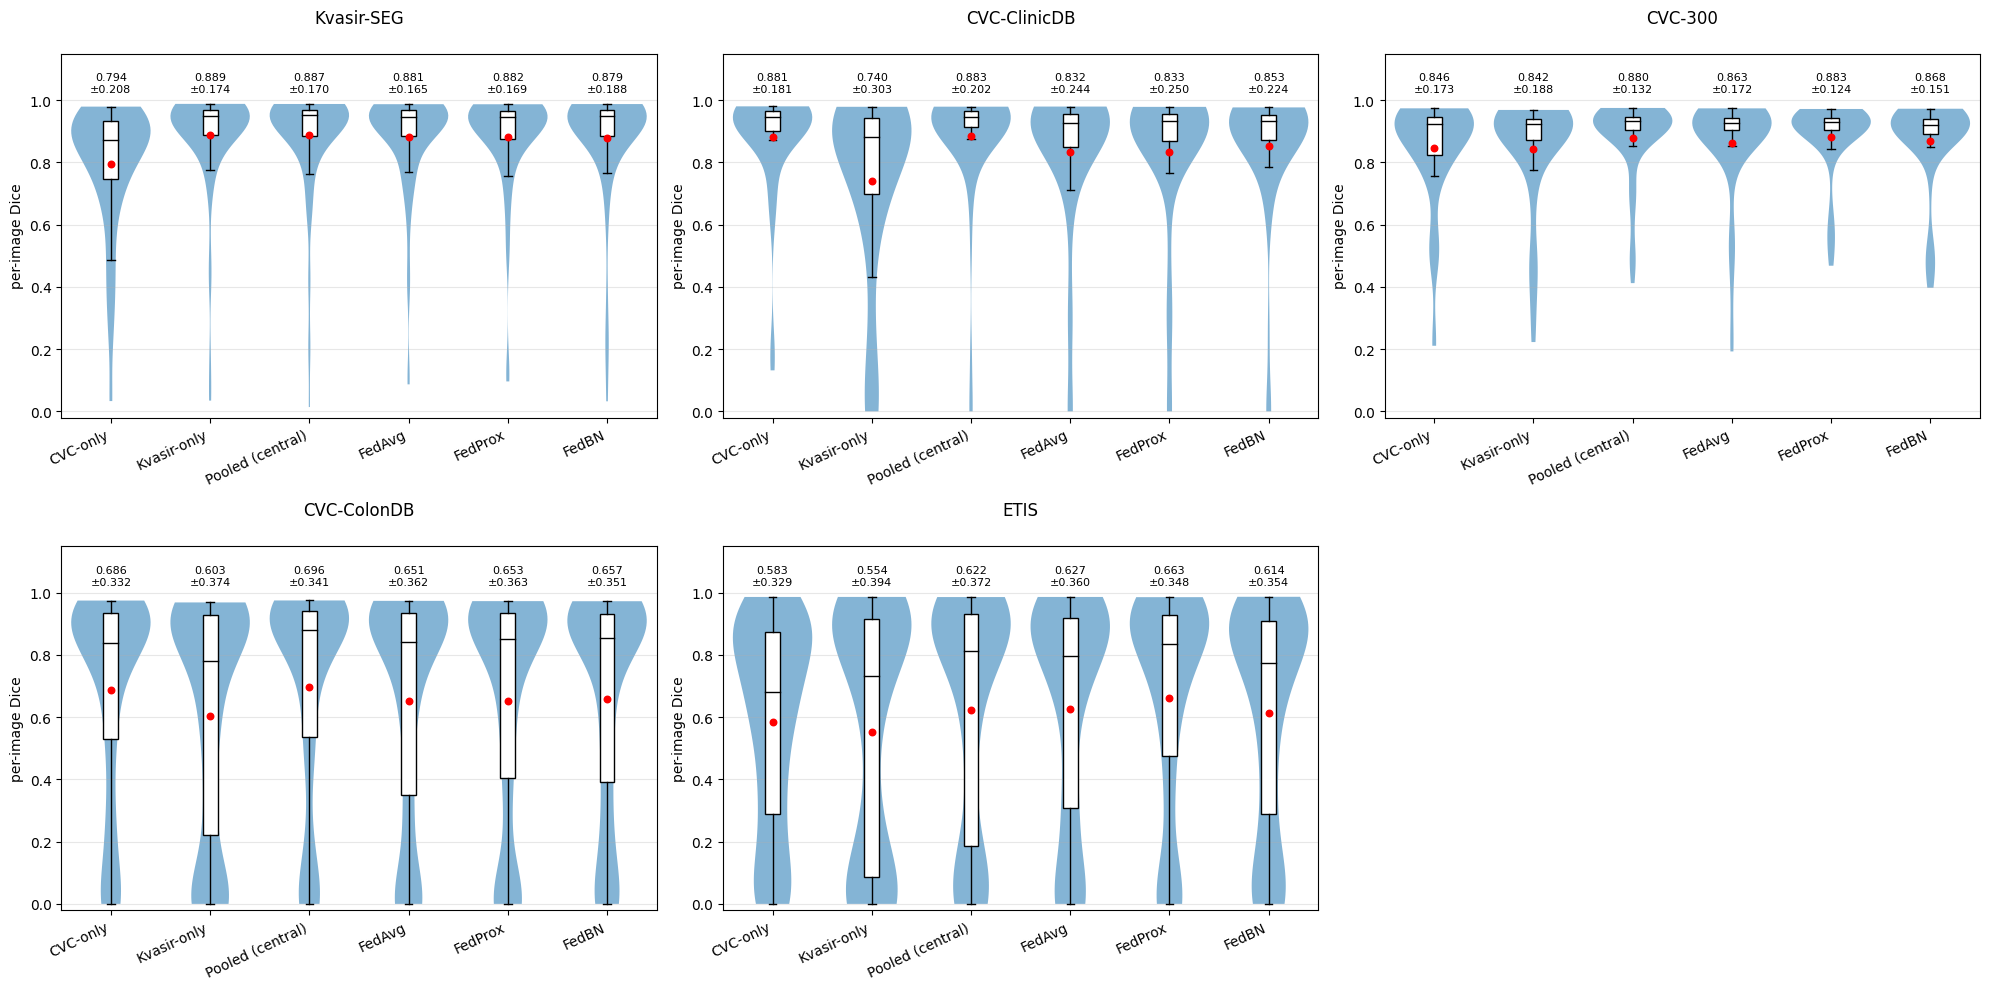

In [ ]:
avail = {n: v for n, v in CFG.items() if have(*v)}
if "Pooled (central)" not in avail:
    print("Pooled results nahi mile -> pehle B2 chalayein")
else:
    print("Models:", list(avail), "| reference = Pooled (central)")
    fig, axs = plt.subplots(2, 3, figsize=(20, 10)); axs = axs.ravel()
    for ax, k in zip(axs, TEST):
        per = {n: load_dice(t, SEEDS, k, d) for n, (t, d) in avail.items()}
        print(f"\n--- {NAMES[k]}  ({'in-domain: ek client ka apna test set' if k in ('kvasir', 'cvc') else 'UNSEEN (zero-shot)'}) ---")
        display(compare_table(per, "Pooled (central)"))
        violin_plot({n: np.mean(np.stack(v), 0) for n, v in per.items()}, NAMES[k], ax=ax, rotate=25)
    for ax in axs[len(TEST):]: ax.axis("off")
    plt.tight_layout(); plt.show()

In [7]:
print("ok")

ok


## B6 — XAI: CVC-only vs Pooled vs FedAvg (SAME protocol, SAME layer, SAME images, CVC-ClinicDB test)

In [8]:
Xte, Yte = D["cvc"]["test"]
tabs = []
if "xai_tab" in globals():                                   # A5 se (CVC-only)
    t = xai_tab.copy(); t.insert(0, "model", "CVC-only"); tabs.append(t)
for name, ck in (("Pooled (central)", f"{FED}/pooled_seed{SEEDS[0]}.weights.h5"), ("FedAvg", f"{FED}/fl_fedavg_seed{SEEDS[0]}.weights.h5")):
    if not os.path.exists(ck):
        print(f"[{name}] weights nahi mile ({ck}) -> skip"); continue
    m = load_trained(build, ck)
    r = xai_full_eval(m, Xte, Yte, n_gc=N_GC, n_lime=N_LIME, lime_segments=150, lime_samples=1000)
    t = xai_report(r); t.insert(0, "model", name); tabs.append(t)
    free_gpu_memory()
if tabs:
    allx = pd.concat(tabs, ignore_index=True)
    display(allx.pivot_table(index=["method", "metric"], columns="model", values="mean").round(3))
    print("(CI95 aur n: poori table neeche)"); display(allx)

KeyboardInterrupt: 

In [9]:
import gc, sys
import tensorflow as tf

for _n in ("m", "r"):                        # B6 ke temporary variables (m = GPU par laga hua model)
    globals().pop(_n, None)
for _n in ("last_type", "last_value", "last_traceback"):   # interrupt wale error ka bacha hua reference
    if hasattr(sys, _n):
        setattr(sys, _n, None)

tf.keras.backend.clear_session()
gc.collect()

try:
    print("GPU live memory (MiB):", round(tf.config.experimental.get_memory_info("GPU:0")["current"] / 2**20))
except Exception:
    pass
print("ok")

GPU live memory (MiB): 168
ok


# PART C — SOTA table + generalisation matrix (sirf disk se saved results padhte hain)

## C1 — SOTA comparison table (published numbers + hamare results, mean ± SD over seeds)

In [10]:
# ===== SOTA COMPARISON TABLE : STANDALONE =====
# Ye cell kisi purane cell / variable (config, TEST, SEEDS, PROTOCOL ...) par depend NAHI karta.
# Ye sirf DISK par saved results padhta hai (jo run_seeds / save_fed_result ne save kiye the):
#     results_fed/pooled_seed*.npz, fl_fedavg_seed*.npz, fl_fedbn_seed*.npz     <- Kvasir notebook K8
#     results_kvasir/kvasir_main_seed*.npz                                      <- Kvasir notebook K2
#     results_cvc/cvc_main_seed*.npz                                            <- CVC notebook C2
# Jo file maujood nahi hogi us model ki row khud skip ho jati hai. Seeds khud detect hote hain.
import os, glob
import numpy as np, pandas as pd

SUFFIX = globals().get("SUFFIX", "")      # Config cell ka SUFFIX (QUICK_TEST => _quicktest)
DIRS = {"cvc": "results_cvc" + SUFFIX, "kvasir": "results_kvasir" + SUFFIX, "fed": "results_fed" + SUFFIX}

cols  = ["kvasir", "cvc", "cvc300", "colondb", "etis"]
heads = {"kvasir": "Kvasir-SEG", "cvc": "CVC-ClinicDB", "cvc300": "CVC-300", "colondb": "CVC-ColonDB", "etis": "ETIS"}

# Published mDice, VERIFIED from the original papers. Protocol (confirmed in the HarDNet-MSEG and UACANet papers):
# train = 1450 images (900 Kvasir-SEG + 550 CVC-ClinicDB); test = Kvasir 100, ClinicDB 62, CVC-300 60, ColonDB 380, ETIS 196.
published = {   # method: ([mDice in `cols` order], source)
    "PraNet (MICCAI'20)":      ([0.898, 0.899, 0.871, 0.709, 0.628], "PraNet paper; same values in HarDNet-MSEG Tab.2-3 and UACANet Tab.3-4"),
    "HarDNet-MSEG (arXiv'21)": ([0.912, 0.932, 0.887, 0.731, 0.677], "arXiv:2101.07172 Tab.2-3 (their CVC-T = CVC-300)"),
    "UACANet-S (ACM MM'21)":   ([0.905, 0.916, 0.902, 0.783, 0.694], "arXiv:2107.02368 Tab.3-4"),
    "UACANet-L (ACM MM'21)":   ([0.912, 0.926, 0.910, 0.751, 0.766], "arXiv:2107.02368 Tab.3-4"),
    "Polyp-PVT (arXiv'21)":    ([0.917, 0.937, 0.900, 0.808, 0.787], "arXiv:2108.06932 Tab.IV-VI (their Endoscene = CVC-300)"),
}

# (folder, file-tag, row name, like-for-like with the published numbers?)
OURS = [("fed",    "pooled",      "Ours: pooled Kvasir+CVC (central)  [like-for-like]", True),
        ("fed",    "fl_fedavg",   "Ours: FedAvg, 2 institutions  [federated; NOT comparable to centralised rows]", False),
        ("fed",    "fl_fedprox",  "Ours: FedProx, 2 institutions  [federated; NOT comparable to centralised rows]", False),
        ("fed",    "fl_fedbn",    "Ours: FedBN, 2 institutions  [federated; NOT comparable to centralised rows]", False),
        ("kvasir", "kvasir_main", "Ours: Kvasir-only  [NOT like-for-like]",              False),
        ("cvc",    "cvc_main",    "Ours: CVC-only  [NOT like-for-like]",                 False)]

def ours_row(folder, tag, name):
    files = sorted(glob.glob(os.path.join(DIRS[folder], f"{tag}_seed*.npz")))
    if not files:
        return None
    data = [np.load(f) for f in files]
    r = {"method": name, "seeds": len(files)}
    for c in cols:
        if all(f"dice__{c}" in d.files for d in data):
            m = [d[f"dice__{c}"].mean() for d in data]            # mean of per-image Dice = mDice
            r[c] = f"{np.mean(m):.3f}" + (f"±{np.std(m, ddof=1):.3f}" if len(m) > 1 else "")
        else:
            r[c] = "-"
    return r

rows = [{"method": k, "seeds": "-", **{c: f"{x:.3f}" for c, x in zip(cols, v[0])}} for k, v in published.items()]
mine = []
for folder, tag, name, like in OURS:
    r = ours_row(folder, tag, name)
    if r is not None:
        rows.append(r); mine.append((r, like))

if not mine:
    print("Koi result file nahi mili. Folders check karo:", DIRS, "\n(QUICK_TEST wale run ke liye SUFFIX = '_quicktest' karo)")
else:
    table = pd.DataFrame(rows).fillna("-")
    display(table.rename(columns=heads))
    best = {c: max(v[0][i] for v in published.values()) for i, c in enumerate(cols)}
    print("\nBest published mDice per test set:", best)
    for r, like in mine:
        if not like: continue                      # sirf like-for-like (pooled) row published numbers se compare hoti hai
        diffs = {c: round(float(str(r[c]).split("±")[0]) - best[c], 3) for c in cols if r[c] != "-"}
        print(f"{r['method']}\n    difference to best published (negative = below): {diffs}")
    print("\nFL rows: published papers ne federated training report nahi ki (sab joint/centralised hain) -> FL rows ka muqabla pooled (central) row se karein (Part B), SOTA se nahi. "
          "PraNet / Polyp-PVT ko FL setup mein khud re-run nahi kiya gaya (limitation).")
    print("\nSources:"); [print(f"  {k}: {v[1]}") for k, v in published.items()]
    print("\nNOTE: Sirf '[like-for-like]' rows published numbers se seedha comparable hain (joint training, same 5 test sets). "
          "'Kvasir-only' / 'CVC-only' ek hi dataset par train hue, in rows ko SOTA claim ke liye use mat karo.")
    print("\nTABLE NOTE (paper mein): All methods are trained on 900 Kvasir-SEG + 550 CVC-ClinicDB images and tested on the five official test sets "
          "(Kvasir 100, CVC-ClinicDB 62, CVC-300 60, CVC-ColonDB 380, ETIS 196) following the PraNet protocol. Values of published methods are copied "
          "from the respective papers; ours are mean±std over seeds (mDice, per-image average). CAVEAT: published numbers are computed at the original "
          "image resolution; ours are computed at 352x352 (masks resized with nearest neighbour).")

,method,seeds,Kvasir-SEG,CVC-ClinicDB,CVC-300,CVC-ColonDB,ETIS
0,PraNet (MICCAI'20),-,0.898,0.899,0.871,0.709,0.628
1,HarDNet-MSEG (arXiv'21),-,0.912,0.932,0.887,0.731,0.677
2,UACANet-S (ACM MM'21),-,0.905,0.916,0.902,0.783,0.694
3,UACANet-L (ACM MM'21),-,0.912,0.926,0.910,0.751,0.766
4,Polyp-PVT (arXiv'21),-,0.917,0.937,0.900,0.808,0.787
5,Ours: pooled Kvasir+CVC (central) [like-for-like],5,0.887±0.011,0.883±0.012,0.880±0.008,0.696±0.010,0.622±0.034
6,"Ours: FedAvg, 2 institutions [federated; NOT comparable to centralised rows]",5,0.881±0.017,0.832±0.020,0.863±0.019,0.651±0.037,0.627±0.043
7,"Ours: FedProx, 2 institutions [federated; NOT comparable to centralised rows]",5,0.882±0.003,0.833±0.007,0.883±0.014,0.653±0.011,0.663±0.025
8,"Ours: FedBN, 2 institutions [federated; NOT comparable to centralised rows]",5,0.879±0.010,0.853±0.015,0.868±0.016,0.657±0.019,0.614±0.038
9,Ours: Kvasir-only [NOT like-for-like],5,0.889±0.008,0.740±0.035,0.842±0.026,0.603±0.035,0.554±0.034



Best published mDice per test set: {'kvasir': 0.917, 'cvc': 0.937, 'cvc300': 0.91, 'colondb': 0.808, 'etis': 0.787}
Ours: pooled Kvasir+CVC (central)  [like-for-like]
    difference to best published (negative = below): {'kvasir': -0.03, 'cvc': -0.054, 'cvc300': -0.03, 'colondb': -0.112, 'etis': -0.165}

FL rows: published papers ne federated training report nahi ki (sab joint/centralised hain) -> FL rows ka muqabla pooled (central) row se karein (Part B), SOTA se nahi. PraNet / Polyp-PVT ko FL setup mein khud re-run nahi kiya gaya (limitation).

Sources:
  PraNet (MICCAI'20): PraNet paper; same values in HarDNet-MSEG Tab.2-3 and UACANet Tab.3-4
  HarDNet-MSEG (arXiv'21): arXiv:2101.07172 Tab.2-3 (their CVC-T = CVC-300)
  UACANet-S (ACM MM'21): arXiv:2107.02368 Tab.3-4
  UACANet-L (ACM MM'21): arXiv:2107.02368 Tab.3-4
  Polyp-PVT (arXiv'21): arXiv:2108.06932 Tab.IV-VI (their Endoscene = CVC-300)

NOTE: Sirf '[like-for-like]' rows published numbers se seedha comparable hain (joint trai

## C2 — Cross-dataset generalisation matrix (mDice mean ± SD; rows = kis par train, columns = kis par test)
Training dobara nahi hoti — `run_seeds` ne sab 5 test sets par pehle hi evaluate karke save kiya tha.

,trained on \ tested on,seeds,Kvasir-SEG,CVC-ClinicDB,CVC-300,CVC-ColonDB,ETIS
0,CVC-only,5,0.794 ± 0.009,0.881 ± 0.010,0.846 ± 0.034,0.686 ± 0.018,0.583 ± 0.029
1,Kvasir-only,5,0.889 ± 0.008,0.740 ± 0.035,0.842 ± 0.026,0.603 ± 0.035,0.554 ± 0.034
2,Pooled (central),5,0.887 ± 0.011,0.883 ± 0.012,0.880 ± 0.008,0.696 ± 0.010,0.622 ± 0.034
3,FedAvg,5,0.881 ± 0.017,0.832 ± 0.020,0.863 ± 0.019,0.651 ± 0.037,0.627 ± 0.043
4,FedProx,5,0.882 ± 0.003,0.833 ± 0.007,0.883 ± 0.014,0.653 ± 0.011,0.663 ± 0.025
5,FedBN,5,0.879 ± 0.010,0.853 ± 0.015,0.868 ± 0.016,0.657 ± 0.019,0.614 ± 0.038


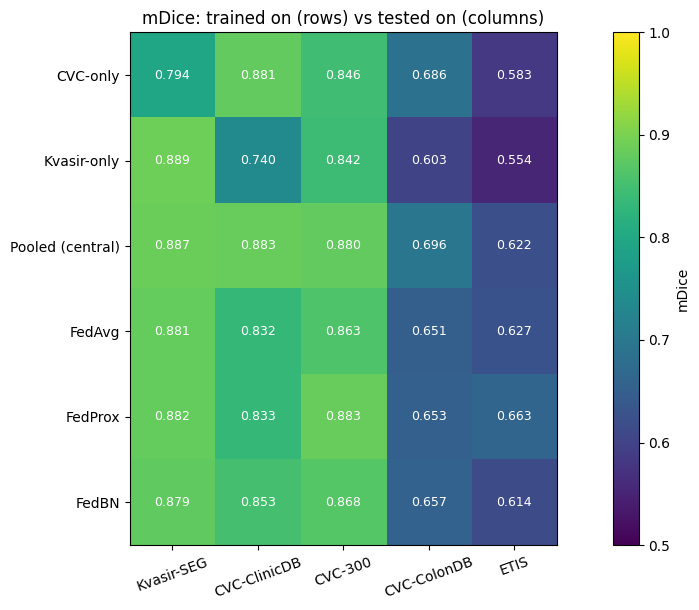

CVC-only: in-domain mDice = 0.881 | drop on unseen sets: {'Kvasir-SEG': 0.086, 'CVC-300': 0.035, 'CVC-ColonDB': 0.194, 'ETIS': 0.297}


In [11]:
rows, means = [], {}
for name, (tag, folder) in CFG.items():
    files = sorted(glob.glob(f"{folder}/{tag}_seed*.npz"))
    if not files:
        continue
    data = [np.load(f) for f in files]
    r = {"trained on \\ tested on": name, "seeds": len(files)}
    means[name] = []
    for k in TEST:
        if all(f"dice__{k}" in d.files for d in data):
            m = [d[f"dice__{k}"].mean() for d in data]; r[NAMES[k]] = pm(m); means[name].append(float(np.mean(m)))
        else:
            r[NAMES[k]] = "-"; means[name].append(np.nan)
    rows.append(r)
if not rows:
    print("Koi saved result nahi mila.")
else:
    display(pd.DataFrame(rows))
    M = np.array(list(means.values()), float)
    fig, ax = plt.subplots(figsize=(1.9 * len(TEST) + 2, 0.7 * len(means) + 2))
    im = ax.imshow(M, vmin=0.5, vmax=1.0, cmap="viridis")
    ax.set_xticks(range(len(TEST))); ax.set_xticklabels([NAMES[k] for k in TEST], rotation=20)
    ax.set_yticks(range(len(means))); ax.set_yticklabels(list(means))
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, "-" if np.isnan(M[i, j]) else f"{M[i, j]:.3f}", ha="center", va="center", color="w", fontsize=9)
    plt.colorbar(im, label="mDice"); ax.set_title("mDice: trained on (rows) vs tested on (columns)"); plt.tight_layout(); plt.show()
    if "CVC-only" in means:
        base = means["CVC-only"][list(TEST).index("cvc")]
        print("CVC-only: in-domain mDice =", round(base, 3), "| drop on unseen sets:",
              {NAMES[k]: round(base - means["CVC-only"][j], 3) for j, k in enumerate(TEST) if k != "cvc"})

In [ ]:
#####D PART

In [12]:
# ===== D0: add-on helpers (D1-D4 se pehle EK baar chalayein) =====
ADDON_MODELS = ["CVC-only", "Kvasir-only", "Pooled (central)", "FedAvg", "FedProx"]   # FedBN mein har client ka apna BN hota hai -> ek global model nahi, isliye yahan nahi

def ckpt_path(model_name, seed):
    tag, folder = CFG[model_name]
    return f"{folder}/{tag}_seed{seed}.weights.h5"

def models_available(seed):
    """{model name: weights path} sirf unka jinke weights disk par maujood hain"""
    return {n: ckpt_path(n, seed) for n in ADDON_MODELS if os.path.exists(ckpt_path(n, seed))}

print("Weights mile:", list(models_available(SEEDS[0])))

Weights mile: ['CVC-only', 'Kvasir-only', 'Pooled (central)', 'FedAvg', 'FedProx']


In [13]:
# ===== D1: XAI with n >= 100 (Kvasir 100 + CVC 62 = 162 test images; SAME images har model par) =====
XAI_SET    = "both"                               # "both" (162 images) | "kvasir" (100) | "cvc" (62, n<100)
if XAI_SET == "both":
    Xx = np.concatenate([TEST["kvasir"][0], TEST["cvc"][0]]); Yx = np.concatenate([TEST["kvasir"][1], TEST["cvc"][1]])
else:
    Xx, Yx = TEST[XAI_SET]
N_GC_BIG   = 5 if QUICK_TEST else len(Xx)         # Grad-CAM++: sab images
N_LIME_BIG = 3 if QUICK_TEST else 50              # LIME: 50 images (150 segments x 1000 samples)
print(f"XAI set = {XAI_SET}: {len(Xx)} images | Grad-CAM++ n = {min(N_GC_BIG, len(Xx))} | LIME n = {N_LIME_BIG}")

mods, res_by_model, tabs = models_available(SEEDS[0]), {}, []
for name, ck in mods.items():
    m = load_trained(build, ck)
    r = xai_full_eval(m, Xx, Yx, n_gc=N_GC_BIG, n_lime=N_LIME_BIG, lime_segments=150, lime_samples=1000)
    res_by_model[name] = r
    t = xai_report(r); t.insert(0, "model", name); tabs.append(t)
    free_gpu_memory()

allx = pd.concat(tabs, ignore_index=True)
display(allx.pivot_table(index=["method", "metric"], columns="model", values="mean").reindex(columns=list(mods)).round(3))
print("Poori table (mean, 95% bootstrap CI, n):"); display(allx)

fig, axs = plt.subplots(1, 2, figsize=(14, 4.8))                     # Grad-CAM++ per-image distribution, model vs model
for ax, metric in zip(axs, ["iou_topg", "auprc"]):
    violin_plot({n: pd.to_numeric(r["gradcam++"][metric], errors="coerce").dropna().values for n, r in res_by_model.items()},
                f"Grad-CAM++ {metric} (n = {min(N_GC_BIG, len(Xx))})", ylabel=metric, ax=ax, rotate=15)
plt.tight_layout(); plt.show()

XAI set = both: 162 images | Grad-CAM++ n = 162 | LIME n = 50


KeyboardInterrupt: 

In [14]:
import gc, sys
import tensorflow as tf

for _n in ("m", "r"):                        # B6 ke temporary variables (m = GPU par laga hua model)
    globals().pop(_n, None)
for _n in ("last_type", "last_value", "last_traceback"):   # interrupt wale error ka bacha hua reference
    if hasattr(sys, _n):
        setattr(sys, _n, None)

tf.keras.backend.clear_session()
gc.collect()

try:
    print("GPU live memory (MiB):", round(tf.config.experimental.get_memory_info("GPU:0")["current"] / 2**20))
except Exception:
    pass
print("ok")

GPU live memory (MiB): 168
ok


Relative robustness = mean(corrupted Dice, sev 1-5) / clean Dice   (1.0 = koi girawat nahi)


,model,test set,clean mDice,Gaussian Noise,Gaussian Blur,Brightness/Contrast,JPEG Compression,Motion Blur,overall
0,CVC-only,Kvasir-SEG,0.780,0.980,0.985,0.995,0.948,0.935,0.969
1,CVC-only,CVC-ClinicDB,0.897,0.745,0.965,0.975,0.917,0.864,0.893
2,Kvasir-only,Kvasir-SEG,0.902,0.831,0.958,0.990,0.945,0.867,0.918
3,Kvasir-only,CVC-ClinicDB,0.766,0.478,0.928,0.927,0.811,0.737,0.776
4,Pooled (central),Kvasir-SEG,0.882,0.903,0.967,0.994,0.959,0.903,0.945
5,Pooled (central),CVC-ClinicDB,0.888,0.640,0.975,0.971,0.881,0.888,0.871
6,FedAvg,Kvasir-SEG,0.882,0.856,0.973,0.993,0.928,0.914,0.933
7,FedAvg,CVC-ClinicDB,0.849,0.537,0.943,0.946,0.849,0.818,0.819
8,FedProx,Kvasir-SEG,0.879,0.834,0.962,0.993,0.960,0.893,0.928
9,FedProx,CVC-ClinicDB,0.837,0.608,0.945,0.956,0.871,0.820,0.840


test set,CVC-ClinicDB,Kvasir-SEG
model,,
CVC-only,0.893,0.969
Kvasir-only,0.776,0.918
Pooled (central),0.871,0.945
FedAvg,0.819,0.933
FedProx,0.840,0.928


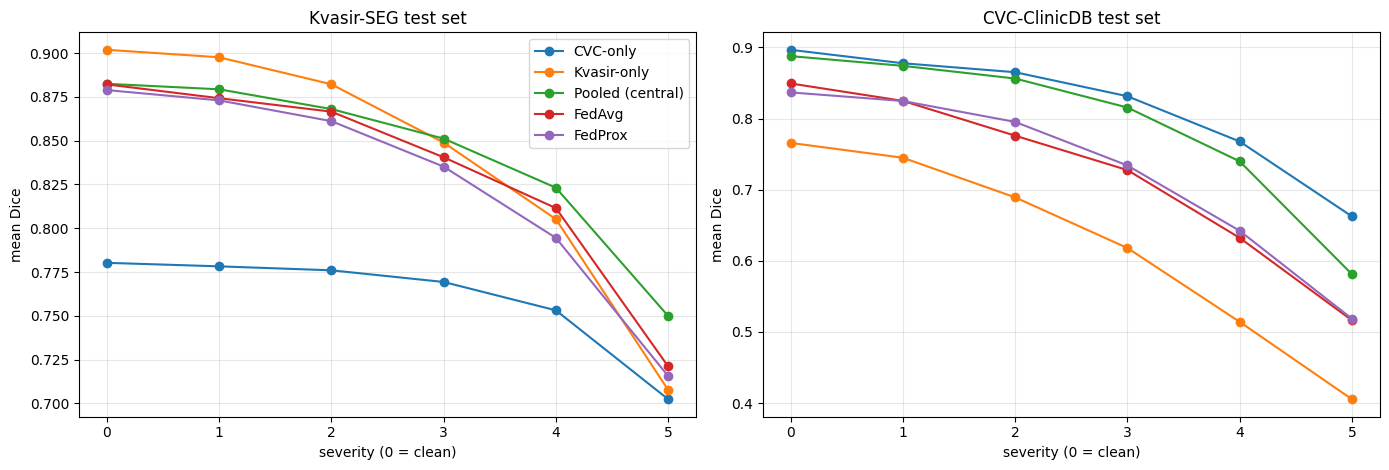

In [15]:
# ===== D2: Robustness SIDE-BY-SIDE (baseline vs pooled vs FL), poora test set, severity 0..5 =====
mods, rows, rb_all = models_available(SEEDS[0]), [], {}
for name, ck in mods.items():
    m = load_trained(build, ck)
    for ds in ("kvasir", "cvc"):
        Xr, Yr = TEST[ds]                                             # POORA test set (subset nahi)
        rb = robustness_eval(m, Xr, Yr)                               # {corruption: [Dice sev0(clean), sev1..sev5]}
        rb_all[(name, ds)] = rb
        rows.append({"model": name, "test set": NAMES[ds], "clean mDice": round(float(next(iter(rb.values()))[0]), 3),
                     **{k: round(v, 3) for k, v in relative_robustness(rb).items()}})
    free_gpu_memory()
tab = pd.DataFrame(rows)
print("Relative robustness = mean(corrupted Dice, sev 1-5) / clean Dice   (1.0 = koi girawat nahi)")
display(tab)
display(tab.pivot(index="model", columns="test set", values="overall").reindex(list(mods)).round(3))

fig, axs = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, ds in zip(axs, ("kvasir", "cvc")):
    for name in mods:
        ax.plot(range(6), np.mean([v for v in rb_all[(name, ds)].values()], axis=0), marker="o", label=name)   # corruptions par average
    ax.set_title(f"{NAMES[ds]} test set"); ax.set_xlabel("severity (0 = clean)"); ax.set_ylabel("mean Dice"); ax.grid(alpha=0.3)
axs[0].legend(); plt.tight_layout(); plt.show()

In [16]:
# ===== D3: HD95 + S-measure (S_alpha), mean ± SD over seeds, har model x har test set =====
def s_measure(pred, gt, eps=1e-8):
    """Structure-measure S_alpha (Fan et al., ICCV 2017; alpha = 0.5). pred: probability map [0,1] (H,W); gt: binary mask (H,W)."""
    pred = np.asarray(pred, np.float64); gt = (np.asarray(gt) > 0.5).astype(np.float64)
    y = gt.mean()
    if y == 0: return float(1.0 - pred.mean())
    if y == 1: return float(pred.mean())
    def s_obj(p, g):
        x = p[g == 1].mean(); sd = p[g == 1].std(ddof=1) if (g == 1).sum() > 1 else 0.0
        return 2 * x / (x ** 2 + 1 + sd + eps)
    s_object = y * s_obj(pred * gt, gt) + (1 - y) * s_obj((1 - pred) * (1 - gt), 1 - gt)
    h, w = gt.shape
    rows, cols = np.arange(1, h + 1), np.arange(1, w + 1)
    cx = int(np.clip(round((gt.sum(0) * cols).sum() / gt.sum()), 1, w - 1)); cy = int(np.clip(round((gt.sum(1) * rows).sum() / gt.sum()), 1, h - 1))
    def ssim(p, g):
        if p.size == 0: return 0.0
        n = p.size; mp, mg = p.mean(), g.mean()
        vp, vg, cpg = ((p - mp) ** 2).sum() / (n - 1 + eps), ((g - mg) ** 2).sum() / (n - 1 + eps), ((p - mp) * (g - mg)).sum() / (n - 1 + eps)
        a, b = 4 * mp * mg * cpg, (mp ** 2 + mg ** 2) * (vp + vg)
        return a / (b + eps) if a != 0 else (1.0 if b == 0 else 0.0)
    area = h * w
    parts = [(slice(0, cy), slice(0, cx), cx * cy / area), (slice(0, cy), slice(cx, w), (w - cx) * cy / area),
             (slice(cy, h), slice(0, cx), cx * (h - cy) / area), (slice(cy, h), slice(cx, w), (w - cx) * (h - cy) / area)]
    s_region = sum(wt * ssim(pred[r, c], gt[r, c]) for r, c, wt in parts)
    return float(max(0.0, 0.5 * s_object + 0.5 * s_region))

HD_SEEDS = SEEDS                       # time kam karna ho to: SEEDS[:3]
store = {}                             # (model, test set) -> [(HD95 mean, S mean, n_empty), ...] har seed ke liye
for name in ADDON_MODELS:
    for s in HD_SEEDS:
        ck = ckpt_path(name, s)
        if not os.path.exists(ck): continue
        m = load_trained(build, ck)
        for k, (X, Y) in TEST.items():
            _, _, probs = evaluate_arrays(m, X, Y)
            hd, n_empty = hd95_batch(Y, probs)                         # pixels; khali prediction par penalty = image diagonal
            sm = np.array([s_measure(probs[i, ..., 0], Y[i, ..., 0]) for i in range(len(X))])
            store.setdefault((name, k), []).append((hd.mean(), sm.mean(), n_empty))
        free_gpu_memory()

def _tab(col, nd, empty=False):
    out = {}
    for (name, k), v in store.items():
        out.setdefault(name, {})[NAMES[k]] = (pm([x[col] for x in v], nd) if not empty else f"{np.mean([x[col] for x in v]):.1f}")
    return pd.DataFrame(out).T.reindex([n for n in ADDON_MODELS if n in out])[[NAMES[k] for k in TEST]]
print("HD95 (pixels, KAM behtar) — mean ± SD over seeds:");              display(_tab(0, 1))
print("S-measure S_alpha (ZYADA behtar) — mean ± SD over seeds:");       display(_tab(1, 3))
print("Khali prediction wali images (seed-average) — inpar HD95 = diagonal penalty:"); display(_tab(2, 1, empty=True))

HD95 (pixels, KAM behtar) — mean ± SD over seeds:


,Kvasir-SEG,CVC-ClinicDB,CVC-300,CVC-ColonDB,ETIS
CVC-only,71.5 ± 10.3,33.1 ± 6.1,47.0 ± 19.2,103.2 ± 11.6,132.8 ± 14.3
Kvasir-only,35.8 ± 2.4,86.3 ± 16.0,27.3 ± 9.6,150.8 ± 16.6,176.2 ± 20.6
Pooled (central),35.2 ± 2.8,31.5 ± 4.8,26.1 ± 8.5,103.8 ± 7.1,144.4 ± 27.9
FedAvg,40.0 ± 4.5,48.8 ± 9.2,24.9 ± 7.4,131.4 ± 18.1,143.4 ± 22.2
FedProx,37.8 ± 1.0,47.9 ± 4.7,20.4 ± 3.4,127.9 ± 10.3,122.2 ± 14.0


S-measure S_alpha (ZYADA behtar) — mean ± SD over seeds:


,Kvasir-SEG,CVC-ClinicDB,CVC-300,CVC-ColonDB,ETIS
CVC-only,0.830 ± 0.010,0.914 ± 0.001,0.902 ± 0.022,0.802 ± 0.007,0.744 ± 0.022
Kvasir-only,0.907 ± 0.005,0.835 ± 0.015,0.905 ± 0.014,0.764 ± 0.016,0.755 ± 0.018
Pooled (central),0.905 ± 0.005,0.918 ± 0.006,0.926 ± 0.006,0.814 ± 0.004,0.787 ± 0.014
FedAvg,0.901 ± 0.010,0.887 ± 0.013,0.917 ± 0.011,0.791 ± 0.018,0.790 ± 0.023
FedProx,0.902 ± 0.003,0.888 ± 0.004,0.929 ± 0.006,0.794 ± 0.006,0.808 ± 0.010


Khali prediction wali images (seed-average) — inpar HD95 = diagonal penalty:


,Kvasir-SEG,CVC-ClinicDB,CVC-300,CVC-ColonDB,ETIS
CVC-only,0.6,1.6,1.0,48.0,24.0
Kvasir-only,0.8,6.6,1.8,96.2,60.2
Pooled (central),0.4,2.2,0.6,57.0,45.0
FedAvg,0.6,3.4,1.2,82.0,45.8
FedProx,0.4,3.2,0.4,80.2,36.6


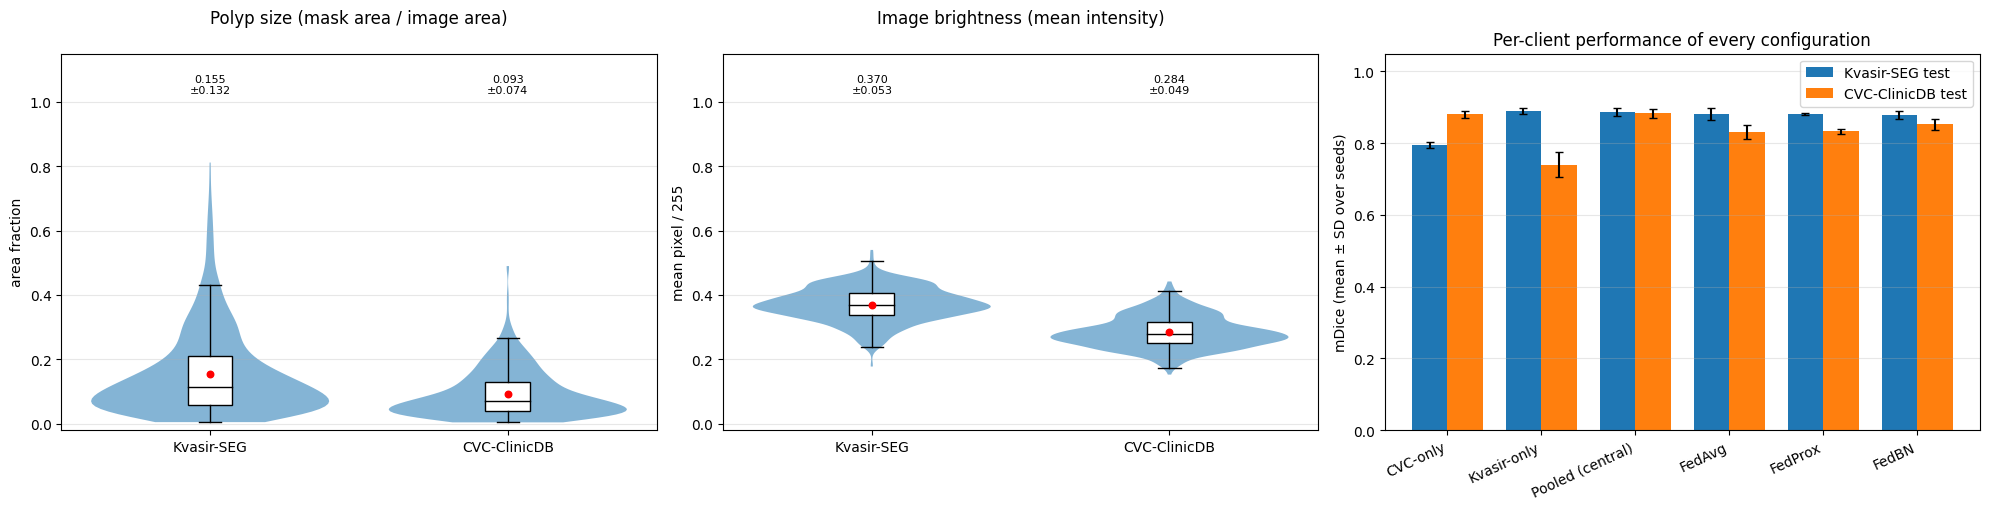

,model,Kvasir mDice,CVC mDice,|gap| between clients
0,CVC-only,0.794,0.881,0.086
1,Kvasir-only,0.889,0.740,0.149
2,Pooled (central),0.887,0.883,0.003
3,FedAvg,0.881,0.832,0.049
4,FedProx,0.882,0.833,0.048
5,FedBN,0.879,0.853,0.025


In [17]:
# ===== D4: Client-heterogeneity figure (Kvasir vs CVC): polyp size, brightness, aur har model ka per-client mDice =====
fig, axs = plt.subplots(1, 3, figsize=(20, 5.2))
cl = {"Kvasir-SEG": D["kvasir"]["train"], "CVC-ClinicDB": D["cvc"]["train"]}                # (X, Y) har client ka train data
violin_plot({n: (Y > 0.5).reshape(len(Y), -1).mean(1) for n, (X, Y) in cl.items()},
            "Polyp size (mask area / image area)", ylabel="area fraction", ax=axs[0])
violin_plot({n: X.reshape(len(X), -1).mean(1) / 255.0 for n, (X, Y) in cl.items()},
            "Image brightness (mean intensity)", ylabel="mean pixel / 255", ax=axs[1])

names, kv, cv = [], [], []
for name, (tag, folder) in CFG.items():
    if have(tag, folder):
        names.append(name)
        kv.append([d.mean() for d in load_dice(tag, SEEDS, "kvasir", folder)]); cv.append([d.mean() for d in load_dice(tag, SEEDS, "cvc", folder)])
xs = np.arange(len(names)); wd = 0.38
axs[2].bar(xs - wd / 2, [np.mean(v) for v in kv], wd, yerr=[np.std(v, ddof=1) if len(v) > 1 else 0 for v in kv], capsize=3, label="Kvasir-SEG test")
axs[2].bar(xs + wd / 2, [np.mean(v) for v in cv], wd, yerr=[np.std(v, ddof=1) if len(v) > 1 else 0 for v in cv], capsize=3, label="CVC-ClinicDB test")
axs[2].set_xticks(xs); axs[2].set_xticklabels(names, rotation=25, ha="right"); axs[2].set_ylabel("mDice (mean ± SD over seeds)")
axs[2].set_ylim(0, 1.05); axs[2].set_title("Per-client performance of every configuration"); axs[2].legend(); axs[2].grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()
display(pd.DataFrame({"model": names, "Kvasir mDice": np.round([np.mean(v) for v in kv], 3), "CVC mDice": np.round([np.mean(v) for v in cv], 3),
                      "|gap| between clients": np.round(np.abs(np.array([np.mean(v) for v in kv]) - np.array([np.mean(v) for v in cv])), 3)}))

In [18]:
# ===== D5: Split ke image-ID lists (reviewer: lists repository mein commit karein) =====
SAVE_SPLIT_CSV = True          # False karein to koi file nahi banegi, sirf yahan cell mein dikhega
rows = []
for k in ("kvasir", "cvc"):
    for sp in ("train", "val"):
        rows += [{"dataset": NAMES[k], "split": sp, "image_id": os.path.basename(p)} for p in D[k][f"paths_{sp}"]]
for k in TEST:
    rows += [{"dataset": NAMES[k], "split": "test", "image_id": os.path.basename(p)} for p in D[k]["paths_test"]]
split_df = pd.DataFrame(rows)
display(split_df.groupby(["dataset", "split"]).size().unstack(fill_value=0))
print("Rule: train/test = PraNet official TrainDataset / TestDataset; val = random 10% of each training dataset (seed 42). "
      "Official test images kabhi train/val mein nahi aate.")
display(split_df.head(10))
if SAVE_SPLIT_CSV:
    split_df.to_csv("split_image_ids.csv", index=False)
    print(f"Saved: split_image_ids.csv ({len(split_df)} rows) -> isi file ko repository mein commit karein")

split,test,train,val
dataset,,,
CVC-300,60,0,0
CVC-ClinicDB,62,495,55
CVC-ColonDB,380,0,0
ETIS,196,0,0
Kvasir-SEG,100,810,90


Rule: train/test = PraNet official TrainDataset / TestDataset; val = random 10% of each training dataset (seed 42). Official test images kabhi train/val mein nahi aate.


,dataset,split,image_id
0,Kvasir-SEG,train,cju0qkwl35piu0993l0dewei2.png
1,Kvasir-SEG,train,cju0qoxqj9q6s0835b43399p4.png
2,Kvasir-SEG,train,cju0qx73cjw570799j4n5cjze.png
3,Kvasir-SEG,train,cju0roawvklrq0799vmjorwfv.png
4,Kvasir-SEG,train,cju0rx1idathl0835detmsp84.png
5,Kvasir-SEG,train,cju0s2a9ekvms080138tjjpxr.png
6,Kvasir-SEG,train,cju0s690hkp960855tjuaqvv0.png
7,Kvasir-SEG,train,cju0sr5ghl0nd08789uzf1raf.png
8,Kvasir-SEG,train,cju0sxqiclckk08551ycbwhno.png
9,Kvasir-SEG,train,cju0t4oil7vzk099370nun5h9.png


Saved: split_image_ids.csv (2248 rows) -> isi file ko repository mein commit karein


In [19]:
# ===== D6: Near-duplicate sensitivity: poora test set vs pHash near-duplicates HATA kar =====
PH_DIST   = 8
train_all = D["kvasir"]["paths_train"] + D["kvasir"]["paths_val"] + D["cvc"]["paths_train"] + D["cvc"]["paths_val"]
flag = {}
for k in TEST:
    nd = near_duplicates(train_all, D[k]["paths_test"], max_dist=PH_DIST)
    flag[k] = nd["nearest_dist"] <= PH_DIST                    # True = kisi train image se bohat milti-julti test image
print(f"Near-duplicate test images (pHash <= {PH_DIST}):", {NAMES[k]: f"{int(v.sum())}/{len(v)}" for k, v in flag.items()})

rows = []
if not any(v.any() for v in flag.values()):
    print("Koi near-duplicate nahi mila -> count = 0, neeche table ki zaroorat nahi.")
else:
    for name, (tag, folder) in CFG.items():
        if not have(tag, folder): continue
        for k in TEST:
            if not flag[k].any(): continue                     # jahan koi near-duplicate nahi, wahan koi farq nahi
            arrs = load_dice(tag, SEEDS, k, folder)            # har seed ka per-image Dice (TEST[k] ke order mein)
            assert len(arrs[0]) == len(flag[k]), "image order/count match nahi"
            keep = ~flag[k]
            if keep.sum() < 5:
                rows.append({"model": name, "test set": NAMES[k], "n (full)": len(keep), "n near-dup": int(flag[k].sum()), "note": "clean subset <5 images"}); continue
            full, clean = [a.mean() for a in arrs], [a[keep].mean() for a in arrs]
            rows.append({"model": name, "test set": NAMES[k], "n (full)": len(keep), "n near-dup": int(flag[k].sum()),
                         "mDice full": pm(full), "mDice without near-dup": pm(clean), "difference": round(float(np.mean(clean) - np.mean(full)), 4)})
    display(pd.DataFrame(rows))
    print("difference = (near-duplicates ke baghair) - (poora set). Chhota farq => natija near-duplicates ki wajah se nahi.")

Near-duplicate test images (pHash <= 8): {'Kvasir-SEG': '16/100', 'CVC-ClinicDB': '45/62', 'CVC-300': '1/60', 'CVC-ColonDB': '56/380', 'ETIS': '3/196'}


,model,test set,n (full),n near-dup,mDice full,mDice without near-dup,difference
0,CVC-only,Kvasir-SEG,100,16,0.794 ± 0.009,0.792 ± 0.012,-0.0023
1,CVC-only,CVC-ClinicDB,62,45,0.881 ± 0.010,0.798 ± 0.025,-0.0830
2,CVC-only,CVC-300,60,1,0.846 ± 0.034,0.844 ± 0.035,-0.0018
3,CVC-only,CVC-ColonDB,380,56,0.686 ± 0.018,0.695 ± 0.015,0.0091
4,CVC-only,ETIS,196,3,0.583 ± 0.029,0.585 ± 0.028,0.0017
5,Kvasir-only,Kvasir-SEG,100,16,0.889 ± 0.008,0.899 ± 0.008,0.0095
6,Kvasir-only,CVC-ClinicDB,62,45,0.740 ± 0.035,0.576 ± 0.048,-0.1639
7,Kvasir-only,CVC-300,60,1,0.842 ± 0.026,0.840 ± 0.026,-0.0018
8,Kvasir-only,CVC-ColonDB,380,56,0.603 ± 0.035,0.618 ± 0.036,0.0148
9,Kvasir-only,ETIS,196,3,0.554 ± 0.034,0.556 ± 0.032,0.0018


difference = (near-duplicates ke baghair) - (poora set). Chhota farq => natija near-duplicates ki wajah se nahi.


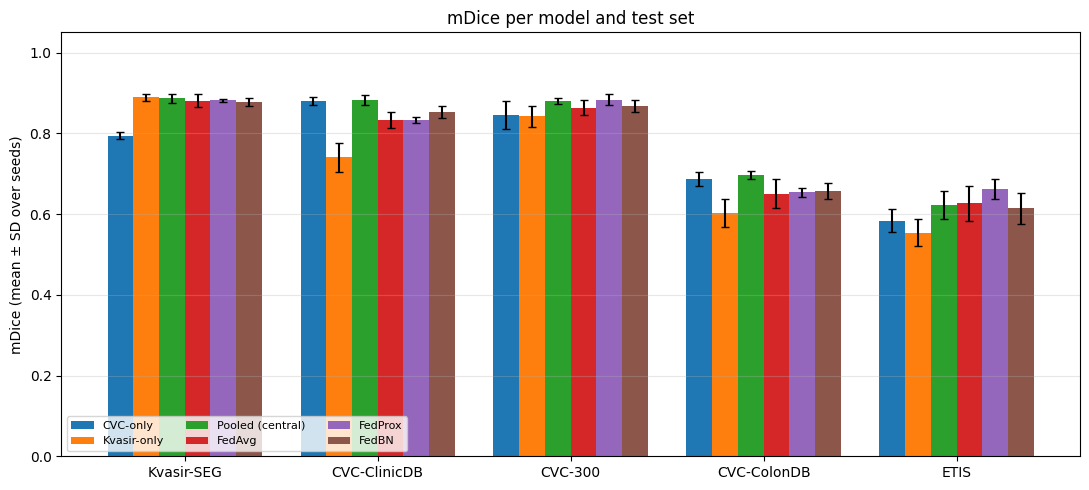

,Kvasir-SEG,CVC-ClinicDB,CVC-300,CVC-ColonDB,ETIS
CVC-only,0.794 ± 0.009,0.881 ± 0.010,0.846 ± 0.034,0.686 ± 0.018,0.583 ± 0.029
Kvasir-only,0.889 ± 0.008,0.740 ± 0.035,0.842 ± 0.026,0.603 ± 0.035,0.554 ± 0.034
Pooled (central),0.887 ± 0.011,0.883 ± 0.012,0.880 ± 0.008,0.696 ± 0.010,0.622 ± 0.034
FedAvg,0.881 ± 0.017,0.832 ± 0.020,0.863 ± 0.019,0.651 ± 0.037,0.627 ± 0.043
FedProx,0.882 ± 0.003,0.833 ± 0.007,0.883 ± 0.014,0.653 ± 0.011,0.663 ± 0.025
FedBN,0.879 ± 0.010,0.853 ± 0.015,0.868 ± 0.016,0.657 ± 0.019,0.614 ± 0.038


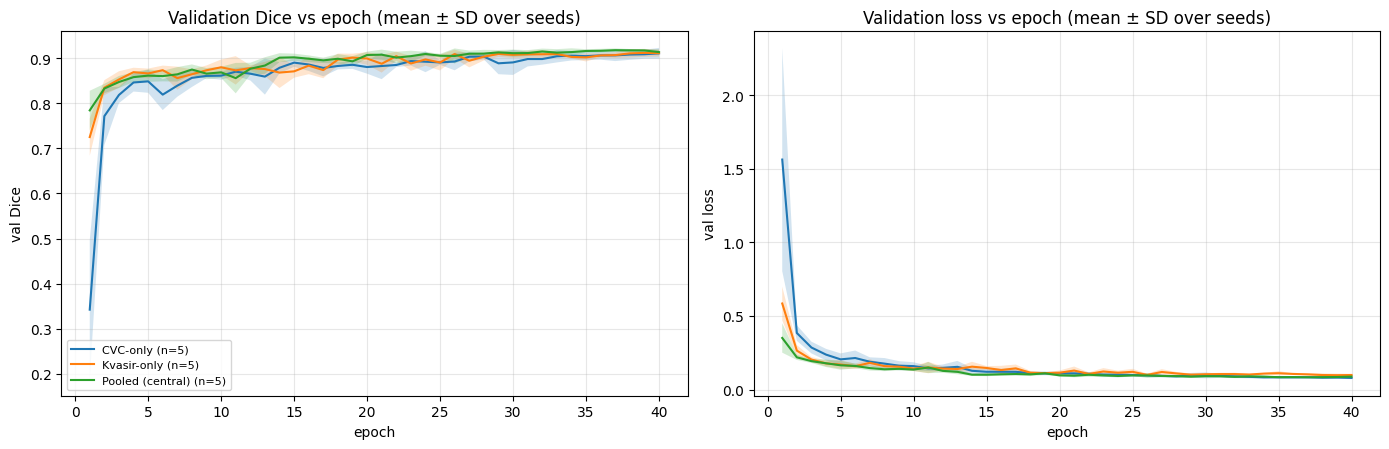

In [20]:
# ===== E1: Bar chart (mDice, mean ± SD over seeds) + Training curves (val Dice vs epoch) =====
# Sirf DISK se results padhta hai (training nahi). Kisi purane cell ko change nahi karta.
# Kahan chalana: sab training + B4 complete hone ke BAAD, notebook ke bilkul aakhir mein (D6 ke baad) ek NAYA cell bana kar.
# Zaroori variables (C0 se): CFG, TEST, NAMES, SEEDS, have, load_dice, plt, np, json, os
%matplotlib inline
import json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

def _plot_bar_and_curves():

    # ---------- 1) BAR CHART: har model, har test set par mDice (mean ± SD over seeds) ----------
    _g_models = [(n, t, f) for n, (t, f) in CFG.items() if have(t, f)]
    _g_sets = list(TEST)
    if not _g_models:
        print("Koi model results nahi mile -> pehle training cells chalayein")
    else:
        _g_rows = {}
        _g_w = 0.8 / len(_g_models)
        _g_x = np.arange(len(_g_sets))
        fig, ax = plt.subplots(figsize=(max(10, 2.2 * len(_g_sets)), 5))
        for j, (n, t, f) in enumerate(_g_models):
            per_seed = {k: [d.mean() for d in load_dice(t, SEEDS, k, f)] for k in _g_sets}   # har seed ka mDice
            mu = [np.mean(per_seed[k]) for k in _g_sets]
            sd = [np.std(per_seed[k], ddof=1) if len(per_seed[k]) > 1 else 0 for k in _g_sets]
            _g_rows[n] = {NAMES[k]: f"{mu[i]:.3f} ± {sd[i]:.3f}" for i, k in enumerate(_g_sets)}
            ax.bar(_g_x + (j - (len(_g_models) - 1) / 2) * _g_w, mu, _g_w, yerr=sd, capsize=3, label=n)
        ax.set_xticks(_g_x); ax.set_xticklabels([NAMES[k] for k in _g_sets])
        ax.set_ylabel("mDice (mean ± SD over seeds)"); ax.set_ylim(0, 1.05)
        ax.set_title("mDice per model and test set"); ax.grid(axis="y", alpha=0.3)
        ax.legend(ncol=3, fontsize=8, loc="lower left")
        plt.tight_layout(); plt.show()
        display(pd.DataFrame(_g_rows).T)      # graph ke neeche wahi numbers table mein

    # ---------- 2) TRAINING CURVES: val Dice aur val loss vs epoch (centralised models; json run_seeds ne save kiya tha) ----------
    _g_curves = {"CVC-only": ("cvc_main", CVC_DIR), "Kvasir-only": ("kvasir_main", KV_DIR), "Pooled (central)": ("pooled", FED)}
    fig, axs = plt.subplots(1, 2, figsize=(14, 4.6))
    _g_any = False
    for name, (tag, folder) in _g_curves.items():
        runs = []
        for s in SEEDS:
            p = f"{folder}/{tag}_seed{s}.json"
            if os.path.exists(p):
                runs.append(json.load(open(p)))
        if not runs:
            continue
        _g_any = True
        for ax, key, lab in ((axs[0], "val_dice_coef", "val Dice"), (axs[1], "val_loss", "val loss")):
            arr = np.array([r[key] for r in runs if key in r], float)       # (seeds, epochs)
            if arr.size == 0:
                continue
            ep = np.arange(1, arr.shape[1] + 1)
            m, s_ = arr.mean(0), (arr.std(0, ddof=1) if len(arr) > 1 else np.zeros(arr.shape[1]))
            ax.plot(ep, m, label=f"{name} (n={len(arr)})")
            ax.fill_between(ep, m - s_, m + s_, alpha=0.2)
            ax.set_xlabel("epoch"); ax.set_ylabel(lab); ax.grid(alpha=0.3)
    axs[0].set_title("Validation Dice vs epoch (mean ± SD over seeds)")
    axs[1].set_title("Validation loss vs epoch (mean ± SD over seeds)")
    if _g_any:
        axs[0].legend(fontsize=8); plt.tight_layout(); plt.show()
    else:
        plt.close(fig); print("Training-history json nahi mile (run_seeds ke saath save hote hain)")


_plot_bar_and_curves()

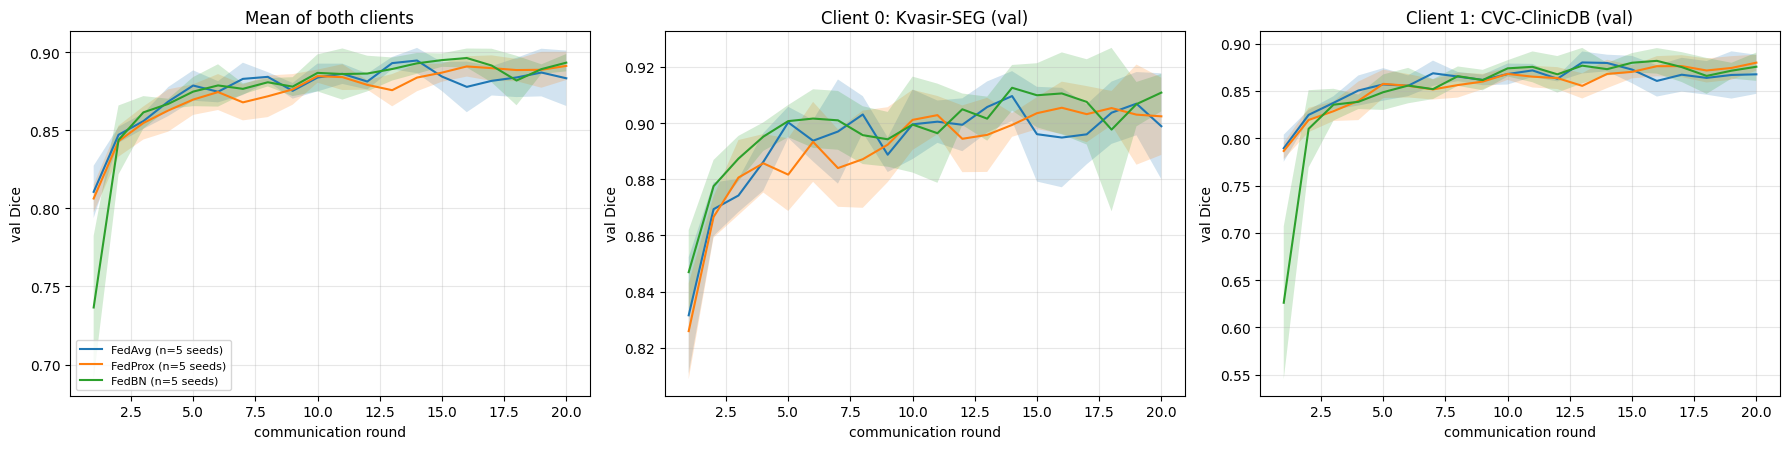

,final val Dice Kvasir,final val Dice CVC,final val Dice mean
FedAvg,0.899 ± 0.019,0.868 ± 0.021,0.883 ± 0.018
FedProx,0.902 ± 0.014,0.880 ± 0.008,0.891 ± 0.009
FedBN,0.911 ± 0.007,0.876 ± 0.015,0.893 ± 0.006


In [21]:
# ===== F1: FL curves — val Dice vs round (FedAvg / FedProx / FedBN), mean ± SD over seeds =====
# Sirf DISK se results_fed/fl_<mode>_seed<seed>_history.json padhta hai (training nahi).
# Kahan chalana: B4 poora hone ke baad, notebook ke aakhir mein ek NAYA cell. Variables (C0 se): FED, SEEDS, np, plt
%matplotlib inline
import json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

def _plot_fl_curves():

    _f_modes = {"FedAvg": "fedavg", "FedProx": "fedprox", "FedBN": "fedbn"}
    _f_panels = [("Mean of both clients", lambda h: h["val_dice_mean"]),
                 ("Client 0: Kvasir-SEG (val)", lambda h: h["val_dice_per_client"][0]),
                 ("Client 1: CVC-ClinicDB (val)", lambda h: h["val_dice_per_client"][1])]
    fig, axs = plt.subplots(1, 3, figsize=(18, 4.6))
    _f_any = False
    _f_rows = {}
    for name, mode in _f_modes.items():
        runs = []
        for s in SEEDS:
            p = f"{FED}/fl_{mode}_seed{s}_history.json"
            if os.path.exists(p):
                runs.append(json.load(open(p)))
        if not runs:
            print(f"[{name}] history nahi mili (is B4 version se pehle ke runs ki nahi bani)"); continue
        _f_any = True
        last = np.array([[r[-1]["val_dice_per_client"][0], r[-1]["val_dice_per_client"][1], r[-1]["val_dice_mean"]] for r in runs], float)
        _f_rows[name] = {c: f"{last[:, i].mean():.3f} ± {(last[:, i].std(ddof=1) if len(last) > 1 else 0):.3f}"
                         for i, c in enumerate(["final val Dice Kvasir", "final val Dice CVC", "final val Dice mean"])}
        for ax, (title, get) in zip(axs, _f_panels):
            arr = np.array([[get(h) for h in r] for r in runs], float)      # (seeds, rounds)
            x = np.arange(1, arr.shape[1] + 1)
            m = arr.mean(0); sd = arr.std(0, ddof=1) if len(arr) > 1 else np.zeros(arr.shape[1])
            ax.plot(x, m, label=f"{name} (n={len(arr)} seeds)")
            ax.fill_between(x, m - sd, m + sd, alpha=0.2)
            ax.set_title(title); ax.set_xlabel("communication round"); ax.set_ylabel("val Dice"); ax.grid(alpha=0.3)
    if _f_any:
        axs[0].legend(fontsize=8); plt.tight_layout(); plt.show()
        display(pd.DataFrame(_f_rows).T)
    else:
        plt.close(fig)


_plot_fl_curves()

In [22]:
# ===== G1: Efficiency table (params / GMac / GFLOPs / latency) — ours vs published SOTA, 352x352 =====
# Training nahi hoti. Sirf ek model build karke measure karta hai (weights se numbers nahi badalte).
# Kahan chalana: B4 ke baad, notebook ke aakhir mein (E aur F cells ke baad) ek NAYA cell.
# Variables (C0 se): build, IMG_SIZE, efficiency_report, free_gpu_memory
import pandas as pd
from IPython.display import display

# Published numbers: PARAMS (M) aur GMac @352x352.
# VERIFY STATUS (original papers khud parhe): Polyp-PVT (arXiv 2108.06932), UACANet (arXiv 2107.02368) aur
# HarDNet-MSEG (arXiv 2101.07172) ke ORIGINAL papers mein params/FLOPs report hi NAHI hote (sirf accuracy/FPS).
# Isliye neeche ke numbers un baad ke papers se hain jinhone official code par khud measure kiya; har number
# kam az kam 2-3 alag papers mein match karta hai, aur GMac @256 -> @352 scaling (x1.89) se cross-check hua:
#   PraNet       32.55M | 6.93 GMac@256 x1.89 = 13.10  vs 13.11@352 (LAPFormer)
#   HarDNet-MSEG 33.34M | 6.02 GMac@256 x1.89 = 11.38  vs 11.38@352 (MMCC-Net)
#   Polyp-PVT    25.1M  | 5.30 GMac@256 x1.89 = 10.02  vs 10.0@352 (MMCC-Net, Polyp-Mamba)
# PraNet ke params kuch papers mein 30.4-30.5M milte hain (unused backbone layers count hon ya na hon); 32.55M zyada papers mein hai.
# UACANet-S / -L: third-party papers sirf "UACANet" ke liye 69.16M aur 31.5 GMac@256 dete hain (S ya L batate nahi) -> use NAHI kiya.
PUBLISHED = {   # method: (params_M, GMac@352 or None, source/note)
    "PraNet (MICCAI'20)":      (32.55, 13.11, "3rd-party measured; params in 5 papers, GMac cross-checked (256->352)"),
    "HarDNet-MSEG (arXiv'21)": (33.34, 11.38, "3rd-party measured; params in 3 papers, GMac cross-checked (256->352)"),
    "UACANet-S (ACM MM'21)":   (None, None,  "no verified S/L-specific number; measure with official code (see notes)"),
    "UACANet-L (ACM MM'21)":   (None, None,  "no verified S/L-specific number; measure with official code (see notes)"),
    "Polyp-PVT (arXiv'21)":    (25.1,  10.0,  "3rd-party measured; params in 4 papers, GMac cross-checked (256->352)"),
}

def _g_efficiency():
    model = build()
    try:
        rep = efficiency_report(model, IMG_SIZE)
    finally:
        del model
        free_gpu_memory()
    gfl = rep.get("gflops")
    rows = []
    for name, (p, g, src) in PUBLISHED.items():
        rows.append({"method": name, "params (M)": p if p is not None else "-",
                     "GMac @352": g if g is not None else "-",
                     "GFLOPs (=2xGMac)": round(2 * g, 1) if g is not None else "-",
                     "latency (ms)": "-", "note": src})
    rows.append({"method": "Ours: ResNet50 U-Net (all 6 variants: CVC-only, Kvasir-only, pooled, FedAvg/FedProx/FedBN)",
                 "params (M)": round(rep["params_M"], 2),
                 "GMac @352": round(gfl / 2, 1) if gfl is not None else "-",
                 "GFLOPs (=2xGMac)": round(gfl, 1) if gfl is not None else "-",
                 "latency (ms)": round(rep["latency_ms"], 1),
                 "note": f"measured here at {IMG_SIZE}x{IMG_SIZE}, batch 1, {rep['fps']:.1f} FPS (own GPU)"})
    display(pd.DataFrame(rows))
    print("NOTES:\n"
          " - Hamare saare 6 models ek hi architecture hain -> params/FLOPs sab ke barabar (FL ya centralised se farq nahi padta).\n"
          " - Published columns GMac (multiply-adds) hain; hamara TF profiler FLOPs deta hai (=2 x GMac), isliye GMac = GFLOPs/2 se compare karein.\n"
          " - Original papers (Polyp-PVT, UACANet, HarDNet-MSEG) params/FLOPs report nahi karte; numbers baad ke papers ke measured hain (cell ke upar comments dekhein). Table note mein likhein: 'efficiency numbers of published methods are taken from [refs] / measured with official code at 352x352'.\n"
          " - UACANet-S/L ke liye apna measurement chahiye: official repo clone karke thop/ptflops se 352x352 par params + MACs nikalein.\n"
          " - Latency/FPS sirf hamari GPU ka hai; published latency ko apne se compare na karein (alag hardware).")

_g_efficiency()

2026-10-07 12:24:17.790769: I tensorflow/core/grappler/devices.cc:66] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 1
2026-10-07 12:24:17.790845: I tensorflow/core/grappler/clusters/single_machine.cc:358] Starting new session
2026-10-07 12:24:17.796371: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1635] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 8114 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3080, pci bus id: 0000:23:00.0, compute capability: 8.6


Instructions for updating:
This API was designed for TensorFlow v1. See https://www.tensorflow.org/guide/migrate for instructions on how to migrate your code to TensorFlow v2.


,method,params (M),GMac @352,GFLOPs (=2xGMac),latency (ms),note
0,PraNet (MICCAI'20),32.55,13.11,26.2,-,"3rd-party measured; params in 5 papers, GMac cross-checked (256->352)"
1,HarDNet-MSEG (arXiv'21),33.34,11.38,22.8,-,"3rd-party measured; params in 3 papers, GMac cross-checked (256->352)"
2,UACANet-S (ACM MM'21),-,-,-,-,no verified S/L-specific number; measure with official code (see notes)
3,UACANet-L (ACM MM'21),-,-,-,-,no verified S/L-specific number; measure with official code (see notes)
4,Polyp-PVT (arXiv'21),25.1,10.0,20.0,-,"3rd-party measured; params in 4 papers, GMac cross-checked (256->352)"
5,"Ours: ResNet50 U-Net (all 6 variants: CVC-only, Kvasir-only, pooled, FedAvg/...",43.94,33.5,67.0,35.1,"measured here at 352x352, batch 1, 28.5 FPS (own GPU)"


NOTES:
 - Hamare saare 6 models ek hi architecture hain -> params/FLOPs sab ke barabar (FL ya centralised se farq nahi padta).
 - Published columns GMac (multiply-adds) hain; hamara TF profiler FLOPs deta hai (=2 x GMac), isliye GMac = GFLOPs/2 se compare karein.
 - Original papers (Polyp-PVT, UACANet, HarDNet-MSEG) params/FLOPs report nahi karte; numbers baad ke papers ke measured hain (cell ke upar comments dekhein). Table note mein likhein: 'efficiency numbers of published methods are taken from [refs] / measured with official code at 352x352'.
 - UACANet-S/L ke liye apna measurement chahiye: official repo clone karke thop/ptflops se 352x352 par params + MACs nikalein.
 - Latency/FPS sirf hamari GPU ka hai; published latency ko apne se compare na karein (alag hardware).


XAI multi-seed: 162 images (Kvasir 100 + CVC 62) | Grad-CAM++ n=162 | LIME n=50 | seeds=[42, 123, 2024]
[CVC-only seed 42] D1 se reuse
[CVC-only seed 42] disk se load
[Kvasir-only seed 42] XAI chal raha hai ...


[Pooled (central) seed 42] XAI chal raha hai ...


[FedAvg seed 42] XAI chal raha hai ...


[FedProx seed 42] XAI chal raha hai ...


[FedBN seed 42] XAI chal raha hai ...


...

[FedBN seed 2024] XAI chal raha hai ...



=== XAI: mean ± SD over seeds (har seed ka value = us seed ke images ka mean) ===


model                                            CVC-only    Kvasir-only Pooled (central)         FedAvg        FedProx          FedBN
method                       metric                                                                                                   
center_prior                 auprc          0.374 ± 0.000  0.374 ± 0.000    0.374 ± 0.000  0.374 ± 0.000  0.374 ± 0.000  0.374 ± 0.000
                             auroc          0.832 ± 0.000  0.832 ± 0.000    0.832 ± 0.000  0.832 ± 0.000  0.832 ± 0.000  0.832 ± 0.000
                             energy_pg      0.208 ± 0.000  0.208 ± 0.000    0.208 ± 0.000  0.208 ± 0.000  0.208 ± 0.000  0.208 ± 0.000
                             iou_topg       0.232 ± 0.000  0.232 ± 0.000    0.232 ± 0.000  0.232 ± 0.000  0.232 ± 0.000  0.232 ± 0.000
                             pointing_game  0.383 ± 0.000  0.383 ± 0.000    0.383 ± 0.000  0.383 ± 0.000  0.383 ± 0.000  0.383 ± 0.000
gradcam++                    auprc          0.902 ± 0.010  0.885 ± 0.021    0.939 ± 0.010  0.919 ± 0.001  0.914 ± 0.007  0.906 ± 0.022
                             auroc          0.958 ± 0.011  0.945 ± 0.017    0.972 ± 0.005  0.961 ± 0.004  0.955 ± 0.007  0.944 ± 0.021
                             energy_pg      0.891 ± 0.011  0.881 ± 0.048    0.936 ± 0.010  0.898 ± 0.030  0.902 ± 0.041  0.881 ± 0.055
                             iou_topg       0.785 ± 0.006  0.796 ± 0.016    0.854 ± 0.008  0.831 ± 0.004  0.823 ± 0.008  0.813 ± 0.035
                             pointing_game  0.961 ± 0.004  0.942 ± 0.020    0.975 ± 0.012  0.971 ± 0.004  0.965 ± 0.004  0.963 ± 0.006
gradcam++ deletion/insertion deletion_auc   0.310 ± 0.066  0.223 ± 0.038    0.464 ± 0.057  0.392 ± 0.076  0.384 ± 0.108  0.478 ± 0.025
                             insertion_auc  0.852 ± 0.008  0.867 ± 0.013    0.880 ± 0.002  0.877 ± 0.007  0.876 ± 0.006  0.876 ± 0.005
lime                         auprc          0.602 ± 0.060  0.580 ± 0.085    0.605 ± 0.029  0.553 ± 0.061  0.605 ± 0.065  0.621 ± 0.031
                             auroc          0.840 ± 0.036  0.832 ± 0.057    0.839 ± 0.026  0.793 ± 0.030  0.830 ± 0.044  0.847 ± 0.012
                             energy_pg      0.352 ± 0.043  0.335 ± 0.054    0.363 ± 0.013  0.343 ± 0.054  0.377 ± 0.036  0.370 ± 0.020
                             iou_topg       0.438 ± 0.055  0.432 ± 0.071    0.438 ± 0.027  0.396 ± 0.057  0.452 ± 0.062  0.455 ± 0.028
                             pointing_game  0.827 ± 0.064  0.773 ± 0.103    0.860 ± 0.000  0.793 ± 0.061  0.787 ± 0.042  0.867 ± 0.042
random                       auprc          0.123 ± 0.000  0.123 ± 0.000    0.123 ± 0.000  0.123 ± 0.000  0.123 ± 0.000  0.123 ± 0.000
                             auroc          0.500 ± 0.000  0.500 ± 0.000    0.500 ± 0.000  0.500 ± 0.000  0.500 ± 0.000  0.500 ± 0.000
                             energy_pg      0.123 ± 0.000  0.123 ± 0.000    0.123 ± 0.000  0.123 ± 0.000  0.123 ± 0.000  0.123 ± 0.000
                             iou_topg       0.070 ± 0.000  0.070 ± 0.000    0.070 ± 0.000  0.070 ± 0.000  0.070 ± 0.000  0.070 ± 0.000
                             pointing_game  0.105 ± 0.000  0.105 ± 0.000    0.105 ± 0.000  0.105 ± 0.000  0.105 ± 0.000  0.105 ± 0.000

Seeds per model: {'CVC-only': 3, 'Kvasir-only': 3, 'Pooled (central)': 3, 'FedAvg': 3, 'FedProx': 3, 'FedBN': 3}

=== Farq vs Pooled (central), seed-wise paired: mean ± SD ===


model                                             CVC-only          FedAvg           FedBN         FedProx     Kvasir-only
method                       metric                                                                                       
center_prior                 auprc          +0.000 ± 0.000  +0.000 ± 0.000  +0.000 ± 0.000  +0.000 ± 0.000  +0.000 ± 0.000
                             auroc          +0.000 ± 0.000  +0.000 ± 0.000  +0.000 ± 0.000  +0.000 ± 0.000  +0.000 ± 0.000
                             energy_pg      +0.000 ± 0.000  +0.000 ± 0.000  +0.000 ± 0.000  +0.000 ± 0.000  +0.000 ± 0.000
                             iou_topg       +0.000 ± 0.000  +0.000 ± 0.000  +0.000 ± 0.000  +0.000 ± 0.000  +0.000 ± 0.000
                             pointing_game  +0.000 ± 0.000  +0.000 ± 0.000  +0.000 ± 0.000  +0.000 ± 0.000  +0.000 ± 0.000
gradcam++                    auprc          -0.037 ± 0.012  -0.020 ± 0.011  -0.033 ± 0.013  -0.025 ± 0.011  -0.054 ± 0.015
                             auroc          -0.014 ± 0.012  -0.011 ± 0.002  -0.028 ± 0.016  -0.017 ± 0.008  -0.027 ± 0.012
                             energy_pg      -0.045 ± 0.019  -0.038 ± 0.040  -0.054 ± 0.045  -0.033 ± 0.047  -0.055 ± 0.051
                             iou_topg       -0.068 ± 0.006  -0.023 ± 0.011  -0.041 ± 0.029  -0.031 ± 0.010  -0.058 ± 0.016
                             pointing_game  -0.014 ± 0.016  -0.004 ± 0.013  -0.012 ± 0.011  -0.010 ± 0.009  -0.033 ± 0.013
gradcam++ deletion/insertion deletion_auc   -0.154 ± 0.101  -0.072 ± 0.124  +0.014 ± 0.066  -0.081 ± 0.144  -0.241 ± 0.043
                             insertion_auc  -0.028 ± 0.008  -0.003 ± 0.008  -0.004 ± 0.006  -0.004 ± 0.006  -0.013 ± 0.012
lime                         auprc          -0.003 ± 0.086  -0.052 ± 0.047  +0.016 ± 0.032  +0.000 ± 0.038  -0.025 ± 0.078
                             auroc          +0.001 ± 0.062  -0.047 ± 0.037  +0.008 ± 0.026  -0.009 ± 0.019  -0.007 ± 0.059
                             energy_pg      -0.011 ± 0.054  -0.020 ± 0.043  +0.007 ± 0.007  +0.014 ± 0.023  -0.028 ± 0.043
                             iou_topg       +0.000 ± 0.082  -0.042 ± 0.052  +0.017 ± 0.026  +0.015 ± 0.045  -0.005 ± 0.078
                             pointing_game  -0.033 ± 0.064  -0.067 ± 0.061  +0.007 ± 0.042  -0.073 ± 0.042  -0.087 ± 0.103
random                       auprc          +0.000 ± 0.000  +0.000 ± 0.000  +0.000 ± 0.000  +0.000 ± 0.000  +0.000 ± 0.000
                             auroc          +0.000 ± 0.000  +0.000 ± 0.000  +0.000 ± 0.000  +0.000 ± 0.000  +0.000 ± 0.000
                             energy_pg      +0.000 ± 0.000  +0.000 ± 0.000  +0.000 ± 0.000  +0.000 ± 0.000  +0.000 ± 0.000
                             iou_topg       +0.000 ± 0.000  +0.000 ± 0.000  +0.000 ± 0.000  +0.000 ± 0.000  +0.000 ± 0.000
                             pointing_game  +0.000 ± 0.000  +0.000 ± 0.000  +0.000 ± 0.000  +0.000 ± 0.000  +0.000 ± 0.000

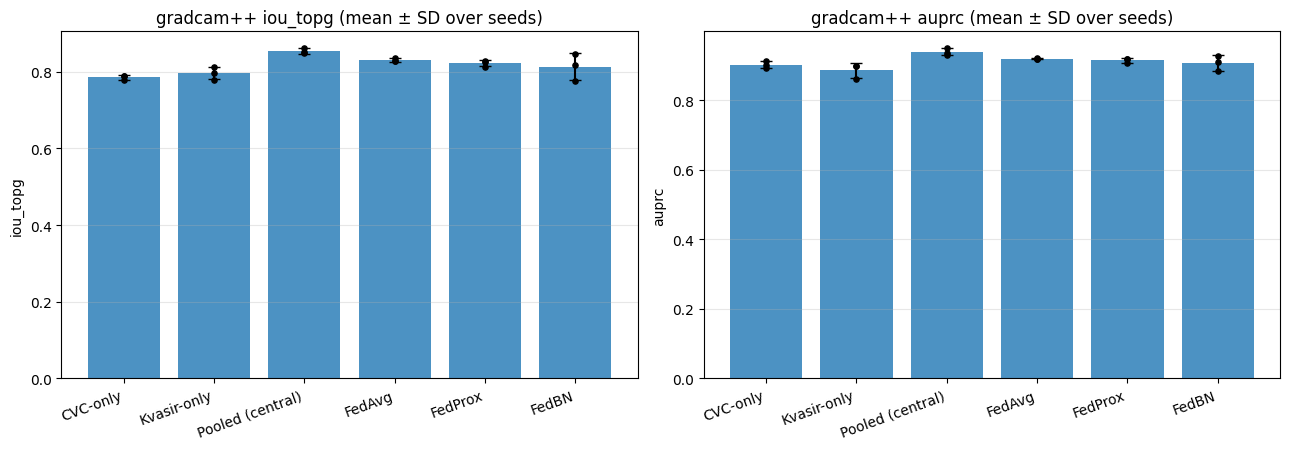


=== Poori table: mean + 95% bootstrap CI over IMAGES (har image ka value = seeds ka mean), D1 jaisi ===


,model,method,metric,mean,ci95_low,ci95_high,n_images,n_seeds
0,CVC-only,center_prior,auprc,0.3743,0.3316,0.4220,162,3
1,Kvasir-only,center_prior,auprc,0.3743,0.3316,0.4220,162,3
2,Pooled (central),center_prior,auprc,0.3743,0.3316,0.4220,162,3
3,FedAvg,center_prior,auprc,0.3743,0.3316,0.4220,162,3
4,FedProx,center_prior,auprc,0.3743,0.3316,0.4220,162,3
...,...,...,...,...,...,...,...,...
127,Kvasir-only,random,pointing_game,0.1049,0.0617,0.1543,162,3
128,Pooled (central),random,pointing_game,0.1049,0.0617,0.1543,162,3
129,FedAvg,random,pointing_game,0.1049,0.0617,0.1543,162,3
130,FedProx,random,pointing_game,0.1049,0.0617,0.1543,162,3


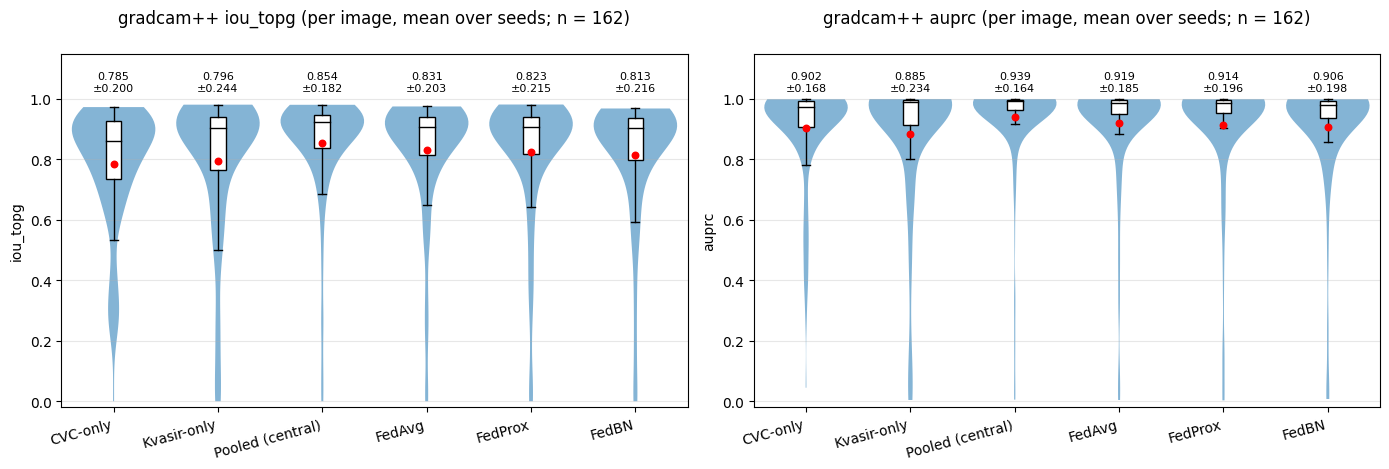

In [23]:
# ===== H1: XAI MULTI-SEED (Grad-CAM++ / LIME) — 6 models x XAI_SEEDS, SAME 162 images, mean ± SD over seeds =====
# Naya cell: B6 / D0 / D1 ko change nahi karta. Resumable: har (model, seed) disk par save hota hai.
# D1 + B6 ka kaam ISI mein hai (6 models, 3 seeds) + D1 wale violin plots aur CI95 wali poori table (seed-averaged per-image).
# Isliye D1/B6 interrupt/skip ho sakte hain (D1 chal chuka ho to H uska seed-42 reuse karta hai, warna khud compute karta hai).
# Extra helpers (C0 se): bootstrap_ci, violin_plot
# KAB CHALANA: B4 POORA hone ke BAAD (GPU chahiye). B4 chal raha ho to isay mat chalayein.
# KAHAN: notebook ke aakhir mein naya cell. Variables (C0 se): CFG, TEST, SEEDS, FED, QUICK_TEST, build, load_trained,
#        xai_full_eval, free_gpu_memory.  D1 pehle chala ho to uska seed-42 result dobara compute nahi hota.
import os, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

XAI_SEEDS = SEEDS[:3]                         # [42, 123, 2024]. Pehle SEEDS[1:2] se time napein, phir barhayein
N_LIME_MS = 3 if QUICK_TEST else 50           # LIME images (D1 wala N_LIME_BIG = 50). Slow ho to 20-30 karein
REUSE_D1  = True                              # D1 ka seed-42 result reuse (sirf tab jab N_LIME_MS == D1 ka N_LIME_BIG)
XAI_MODELS = ["CVC-only", "Kvasir-only", "Pooled (central)", "FedAvg", "FedProx", "FedBN"]
XAI_DIR   = os.path.join(FED, "xai_multiseed")


def _xai_multiseed():
    os.makedirs(XAI_DIR, exist_ok=True)
    xx = np.concatenate([TEST["kvasir"][0], TEST["cvc"][0]])         # D1 wala "both" set: pehle Kvasir, phir CVC
    yx = np.concatenate([TEST["kvasir"][1], TEST["cvc"][1]])
    n_kv = len(TEST["kvasir"][0])
    n_gc = 5 if QUICK_TEST else len(xx)
    kw = dict(n_gc=n_gc, n_lime=N_LIME_MS, lime_segments=150, lime_samples=1000)
    print(f"XAI multi-seed: {len(xx)} images (Kvasir {n_kv} + CVC {len(xx) - n_kv}) | Grad-CAM++ n={min(n_gc, len(xx))} | "
          f"LIME n={N_LIME_MS} | seeds={XAI_SEEDS}")

    def path(name, seed):
        slug = name.replace(" ", "_").replace("(", "").replace(")", "")
        return os.path.join(XAI_DIR, f"{slug}_seed{seed}.pkl")

    def run_one(name, seed):
        if name != "FedBN":                                           # ek global model
            tag, folder = CFG[name]
            ck = f"{folder}/{tag}_seed{seed}.weights.h5"
            if not os.path.exists(ck):
                return None
            m = load_trained(build, ck)
            r = xai_full_eval(m, xx, yx, **kw)
            del m; free_gpu_memory()
            return r
        # FedBN: har client ka apna BN -> Kvasir images client-0 model se, CVC images client-1 model se
        # (eval_federated wala hi mapping). Dono models poore set par chalte hain, phir har image ki row
        # uske institution ke model se li jati hai -> baaki models jaisi hi SAME images.
        tag, folder = CFG["FedBN"]
        cks = [f"{folder}/{tag}_seed{seed}_client{c}.weights.h5" for c in (0, 1)]
        if not all(os.path.exists(c) for c in cks):
            return None
        rs = []
        for ck in cks:
            m = load_trained(build, ck)
            rs.append(xai_full_eval(m, xx, yx, **kw))
            del m; free_gpu_memory()
        order = np.random.default_rng(0).permutation(len(xx))        # xai_full_eval ka apna image order (seed=0)
        out = {}
        for method, df0 in rs[0].items():
            df1 = rs[1][method]
            from_kvasir = order[:len(df0)] < n_kv
            out[method] = pd.DataFrame(np.where(from_kvasir[:, None], df0.values, df1.values), columns=df0.columns)
        return out

    # D1 ke seed-42 results reuse (compute bachta hai)
    if (REUSE_D1 and globals().get("XAI_SET") == "both" and "res_by_model" in globals()
            and globals().get("N_LIME_BIG") == N_LIME_MS and len(globals().get("Xx", [])) == len(xx)):
        for name, r in globals()["res_by_model"].items():
            if name in XAI_MODELS and SEEDS[0] in XAI_SEEDS and not os.path.exists(path(name, SEEDS[0])):
                pickle.dump(r, open(path(name, SEEDS[0]), "wb"))
                print(f"[{name} seed {SEEDS[0]}] D1 se reuse")

    per_seed = {}
    for seed in XAI_SEEDS:
        for name in XAI_MODELS:
            p = path(name, seed)
            if os.path.exists(p):
                r = pickle.load(open(p, "rb"))
                print(f"[{name} seed {seed}] disk se load", flush=True)
            else:
                print(f"[{name} seed {seed}] XAI chal raha hai ...", flush=True)
                r = run_one(name, seed)
                if r is None:
                    print(f"   weights nahi mile -> skip", flush=True)
                    continue
                pickle.dump(r, open(p, "wb"))
            per_seed[(name, seed)] = r
    if not per_seed:
        print("Koi XAI result nahi bana. Weights check karein.")
        return

    rows = []                                                         # seed-level value = us seed ka image-mean
    for (name, seed), r in per_seed.items():
        for method, df in r.items():
            for col in df.columns:
                v = pd.to_numeric(df[col], errors="coerce").dropna()
                if len(v):
                    rows.append({"model": name, "seed": seed, "method": method, "metric": col, "value": float(v.mean())})
    agg = pd.DataFrame(rows)
    order_models = [m for m in XAI_MODELS if m in agg["model"].unique()]

    g = agg.groupby(["method", "metric", "model"])["value"]
    summ = pd.DataFrame({"mean": g.mean(), "sd": g.std(ddof=1), "n_seeds": g.count()}).reset_index()
    summ["txt"] = [f"{m:.3f} ± {0 if pd.isna(s) else s:.3f}" for m, s in zip(summ["mean"], summ["sd"])]
    print("\n=== XAI: mean ± SD over seeds (har seed ka value = us seed ke images ka mean) ===")
    display(summ.pivot_table(index=["method", "metric"], columns="model", values="txt", aggfunc="first")
            .reindex(columns=order_models))
    print("Seeds per model:", summ.groupby("model")["n_seeds"].max().reindex(order_models).to_dict())

    if "Pooled (central)" in order_models:                            # paired by seed: model - pooled
        piv = agg.pivot_table(index=["method", "metric", "seed"], columns="model", values="value")
        drows = []
        for name in order_models:
            if name == "Pooled (central)":
                continue
            d = (piv[name] - piv["Pooled (central)"]).dropna()
            for (method, metric), s in d.groupby(level=[0, 1]):
                drows.append({"method": method, "metric": metric, "model": name, "n_seeds": len(s),
                              "diff vs Pooled": f"{s.mean():+.3f} ± {0 if len(s) < 2 else s.std(ddof=1):.3f}"})
        if drows:
            print("\n=== Farq vs Pooled (central), seed-wise paired: mean ± SD ===")
            display(pd.DataFrame(drows).pivot_table(index=["method", "metric"], columns="model",
                                                    values="diff vs Pooled", aggfunc="first"))

    keys = [(m, k) for m, k in (("gradcam++", "iou_topg"), ("gradcam++", "auprc")) if ((agg["method"] == m) & (agg["metric"] == k)).any()]
    if keys:
        fig, axs = plt.subplots(1, len(keys), figsize=(6.5 * len(keys), 4.6), squeeze=False)
        for ax, (m, k) in zip(axs[0], keys):
            sub = agg[(agg["method"] == m) & (agg["metric"] == k)]
            mu = [sub[sub["model"] == n]["value"].mean() for n in order_models]
            sd = [sub[sub["model"] == n]["value"].std(ddof=1) if (sub["model"] == n).sum() > 1 else 0 for n in order_models]
            ax.bar(range(len(order_models)), mu, yerr=sd, capsize=4, alpha=0.8)
            for i, n in enumerate(order_models):                      # har seed ka point
                ys = sub[sub["model"] == n]["value"].values
                ax.scatter([i] * len(ys), ys, color="k", s=14, zorder=3)
            ax.set_xticks(range(len(order_models))); ax.set_xticklabels(order_models, rotation=20, ha="right")
            ax.set_title(f"{m} {k} (mean ± SD over seeds)"); ax.set_ylabel(k); ax.grid(axis="y", alpha=0.3)
        plt.tight_layout(); plt.show()

    # ---- D1 jaisa: per-image values (har image ka mean OVER SEEDS) -> bootstrap CI95 over images + violin plots ----
    def per_image(name, method, col):
        arrs = [np.asarray(pd.to_numeric(per_seed[(name, sd)][method][col], errors="coerce"), float)
                for sd in XAI_SEEDS if (name, sd) in per_seed and method in per_seed[(name, sd)]
                and col in per_seed[(name, sd)][method].columns]
        if not arrs:
            return None, 0
        L = min(len(a) for a in arrs)                                  # same images/order har seed par
        with np.errstate(all="ignore"):
            return np.nanmean(np.vstack([a[:L] for a in arrs]), axis=0), len(arrs)

    ci_rows = []
    for method in sorted(agg["method"].unique()):
        for col in sorted(agg[agg["method"] == method]["metric"].unique()):
            for name in order_models:
                v, ns = per_image(name, method, col)
                if v is None:
                    continue
                v = v[~np.isnan(v)]
                if len(v) == 0:
                    continue
                lo, hi = bootstrap_ci(v, n_boot=2000)
                ci_rows.append({"model": name, "method": method, "metric": col, "mean": round(float(v.mean()), 4),
                                "ci95_low": round(lo, 4), "ci95_high": round(hi, 4), "n_images": len(v), "n_seeds": ns})
    print("\n=== Poori table: mean + 95% bootstrap CI over IMAGES (har image ka value = seeds ka mean), D1 jaisi ===")
    display(pd.DataFrame(ci_rows))

    vk = [(m, k) for m, k in (("gradcam++", "iou_topg"), ("gradcam++", "auprc")) if ((agg["method"] == m) & (agg["metric"] == k)).any()]
    if vk:
        fig, axs = plt.subplots(1, len(vk), figsize=(7 * len(vk), 4.8), squeeze=False)
        for ax, (m, k) in zip(axs[0], vk):
            groups = {}
            for name in order_models:
                v, _ = per_image(name, m, k)
                if v is not None:
                    groups[name] = v
            violin_plot(groups, f"{m} {k} (per image, mean over seeds; n = {len(next(iter(groups.values())))})",
                        ylabel=k, ax=ax, rotate=15)
        plt.tight_layout(); plt.show()
    return agg


_xai_ms = _xai_multiseed()

In [24]:
# ===== I1: XAI dataset-wise table (Kvasir-SEG alag | CVC-ClinicDB alag) — H ke SAVED results se, H dobara nahi chalana =====
# Sirf disk se results_fed/xai_multiseed/*.pkl padhta hai (GPU / training / LIME nahi). Kuch seconds mein khatam.
# Kahan chalana: H ke baad (ya kabhi bhi, jab H ke .pkl files ban chuki hon), notebook ke aakhir mein naya cell.
# Variables (C0 se): TEST, SEEDS, FED   (kernel restart ke baad bhi chalta hai, bas pehle C0 chalayein)
import os, pickle
import numpy as np
import pandas as pd
from IPython.display import display

def _xai_dataset_split():
    seeds  = SEEDS[:3]                                   # H ne jo seeds chalaye (XAI_SEEDS = SEEDS[:3])
    models = ["CVC-only", "Kvasir-only", "Pooled (central)", "FedAvg", "FedProx", "FedBN"]
    xdir   = os.path.join(FED, "xai_multiseed")
    n_kv   = len(TEST["kvasir"][0])
    n_all  = n_kv + len(TEST["cvc"][0])
    order  = np.random.default_rng(0).permutation(n_all)  # xai_full_eval ka image order (H wala hi)

    def path(name, seed):
        return os.path.join(xdir, name.replace(" ", "_").replace("(", "").replace(")", "") + f"_seed{seed}.pkl")

    per_seed = {}
    for name in models:
        for sd in seeds:
            if os.path.exists(path(name, sd)):
                per_seed[(name, sd)] = pickle.load(open(path(name, sd), "rb"))
    if not per_seed:
        print(f"Koi .pkl nahi mili: {xdir}  -> pehle H chalana hoga"); return
    present = [m for m in models if any((m, sd) in per_seed for sd in seeds)]
    print("Seeds per model:", {m: sum((m, sd) in per_seed for sd in seeds) for m in present})

    def per_image(name, method, col):                    # har image ka mean OVER SEEDS
        arrs = [np.asarray(pd.to_numeric(per_seed[(name, sd)][method][col], errors="coerce"), float)
                for sd in seeds if (name, sd) in per_seed and method in per_seed[(name, sd)]
                and col in per_seed[(name, sd)][method].columns]
        if not arrs:
            return None
        L = min(len(a) for a in arrs)
        with np.errstate(all="ignore"):
            return np.nanmean(np.vstack([a[:L] for a in arrs]), axis=0)

    methods = sorted({m for r in per_seed.values() for m in r})
    rows = []
    for method in methods:
        cols = sorted({c for r in per_seed.values() if method in r for c in r[method].columns})
        for col in cols:
            for name in present:
                v = per_image(name, method, col)
                if v is None:
                    continue
                is_kv = order[:len(v)] < n_kv
                for dsname, mask in (("Kvasir-SEG", is_kv), ("CVC-ClinicDB", ~is_kv)):
                    x = v[mask]; x = x[~np.isnan(x)]
                    if len(x):
                        rows.append({"dataset": dsname, "model": name, "method": method, "metric": col,
                                     "mean": float(x.mean()), "n": len(x)})
    ds = pd.DataFrame(rows)
    print("\n=== XAI dataset-wise: Kvasir-SEG alag, CVC-ClinicDB alag (har image ka mean over seeds) ===")
    display(ds.pivot_table(index=["method", "metric"], columns=["dataset", "model"], values="mean")
              .reindex(columns=present, level=1).round(3))
    print("Images per dataset (n):", ds.groupby(["method", "dataset"])["n"].max().to_dict())
    print("NOTE: LIME 162 mein se chune hue 50 images par chalta hai, isliye har dataset ke LIME ka n chhota hai (upar n dekhein).")
    return ds

_xai_ds = _xai_dataset_split()

Seeds per model: {'CVC-only': 3, 'Kvasir-only': 3, 'Pooled (central)': 3, 'FedAvg': 3, 'FedProx': 3, 'FedBN': 3}

=== XAI dataset-wise: Kvasir-SEG alag, CVC-ClinicDB alag (har image ka mean over seeds) ===


dataset                                    CVC-ClinicDB                                                    Kvasir-SEG                                                   
model                                          CVC-only Kvasir-only Pooled (central) FedAvg FedProx  FedBN   CVC-only Kvasir-only Pooled (central) FedAvg FedProx  FedBN
method                       metric                                                                                                                                     
center_prior                 auprc                0.302       0.302            0.302  0.302   0.302  0.302      0.419       0.419            0.419  0.419   0.419  0.419
                             auroc                0.828       0.828            0.828  0.828   0.828  0.828      0.835       0.835            0.835  0.835   0.835  0.835
                             energy_pg            0.142       0.142            0.142  0.142   0.142  0.142      0.249       0.249            0.249  0.249   0.249  0.249
                             iou_topg             0.180       0.180            0.180  0.180   0.180  0.180      0.265       0.265            0.265  0.265   0.265  0.265
                             pointing_game        0.290       0.290            0.290  0.290   0.290  0.290      0.440       0.440            0.440  0.440   0.440  0.440
gradcam++                    auprc                0.935       0.802            0.938  0.893   0.891  0.902      0.882       0.937            0.939  0.936   0.929  0.909
                             auroc                0.976       0.905            0.976  0.950   0.940  0.949      0.946       0.969            0.970  0.967   0.965  0.942
                             energy_pg            0.914       0.810            0.925  0.859   0.862  0.879      0.877       0.924            0.942  0.922   0.927  0.883
                             iou_topg             0.842       0.707            0.857  0.806   0.803  0.819      0.750       0.850            0.851  0.846   0.835  0.809
                             pointing_game        0.962       0.887            0.962  0.952   0.935  0.952      0.960       0.977            0.983  0.983   0.983  0.970
gradcam++ deletion/insertion deletion_auc         0.306       0.178            0.442  0.361   0.364  0.424      0.311       0.245            0.469  0.407   0.391  0.501
                             insertion_auc        0.854       0.814            0.853  0.863   0.857  0.840      0.847       0.885            0.884  0.881   0.883  0.884
lime                         auprc                0.556       0.400            0.504  0.453   0.517  0.508      0.641       0.734            0.691  0.639   0.680  0.717
                             auroc                0.816       0.760            0.811  0.751   0.795  0.810      0.861       0.894            0.864  0.828   0.861  0.878
                             energy_pg            0.290       0.203            0.275  0.251   0.293  0.271      0.405       0.448            0.437  0.420   0.448  0.455
                             iou_topg             0.394       0.270            0.339  0.312   0.377  0.349      0.476       0.571            0.522  0.467   0.516  0.545
                             pointing_game        0.855       0.594            0.797  0.696   0.710  0.768      0.802       0.926            0.914  0.877   0.852  0.951
random                       auprc                0.080       0.080            0.080  0.080   0.080  0.080      0.150       0.150            0.150  0.150   0.150  0.150
                             auroc                0.500       0.500            0.500  0.500   0.500  0.500      0.500       0.500            0.500  0.500   0.500  0.500
                             energy_pg            0.080       0.080            0.080  0.080   0.080  0.080      0.150       0.150            0.150  0.150   0.150  0.150
                             iou_topg             0.044       0.044            0.044  0.044   0.044  0.044      0

Images per dataset (n): {('center_prior', 'CVC-ClinicDB'): 62, ('center_prior', 'Kvasir-SEG'): 100, ('gradcam++', 'CVC-ClinicDB'): 62, ('gradcam++', 'Kvasir-SEG'): 100, ('gradcam++ deletion/insertion', 'CVC-ClinicDB'): 62, ('gradcam++ deletion/insertion', 'Kvasir-SEG'): 100, ('lime', 'CVC-ClinicDB'): 23, ('lime', 'Kvasir-SEG'): 27, ('random', 'CVC-ClinicDB'): 62, ('random', 'Kvasir-SEG'): 100}
NOTE: LIME 162 mein se chune hue 50 images par chalta hai, isliye har dataset ke LIME ka n chhota hai (upar n dekhein).


In [25]:
# ===== J1: XAI statistics — paired Wilcoxon + Holm + bootstrap CI95 (B5 jaisa), reference = Pooled (central) =====
# Grad-CAM++ per-image top-g IoU aur AUPRC par. H ke SAVED results (.pkl) se; GPU / training / LIME nahi. Kuch seconds.
# Kahan chalana: H ke baad (ya jab bhi results_fed/xai_multiseed/*.pkl bani hon), notebook ke aakhir mein naya cell.
# Variables / functions (C0 se): TEST, SEEDS, FED, compare_configs (B5 wala hi: Wilcoxon + Holm + bootstrap CI)
# Statistical unit = IMAGE: har image ki value pehle seeds par average, phir ek paired Wilcoxon per comparison.
import os, pickle
import numpy as np
import pandas as pd
from IPython.display import display

def _xai_stats():
    seeds  = SEEDS[:3]                                   # H ke XAI_SEEDS
    models = ["CVC-only", "Kvasir-only", "Pooled (central)", "FedAvg", "FedProx", "FedBN"]
    ref    = "Pooled (central)"
    xdir   = os.path.join(FED, "xai_multiseed")
    n_kv   = len(TEST["kvasir"][0]); n_all = n_kv + len(TEST["cvc"][0])
    order  = np.random.default_rng(0).permutation(n_all)  # xai_full_eval ka image order (H wala hi)

    def path(name, sd):
        return os.path.join(xdir, name.replace(" ", "_").replace("(", "").replace(")", "") + f"_seed{sd}.pkl")

    per = {m: {} for m in models}                         # model -> seed -> {method: DataFrame}
    for m in models:
        for sd in seeds:
            if os.path.exists(path(m, sd)):
                per[m][sd] = pickle.load(open(path(m, sd), "rb"))
    present = [m for m in models if per[m]]
    if ref not in present:
        print("Pooled (central) ki .pkl nahi mili -> pehle H chalana hoga"); return
    print("Seeds per model:", {m: len(per[m]) for m in present}, "| reference =", ref)

    def arrays(m, metric):                                # [array per seed], row-aligned (same images/order)
        out = [np.asarray(pd.to_numeric(per[m][sd]["gradcam++"][metric], errors="coerce"), float) for sd in sorted(per[m])]
        return out

    subsets = (("ALL 162 images (Kvasir + CVC)", lambda is_kv: np.ones_like(is_kv, bool)),
               ("Kvasir-SEG (100 images)",       lambda is_kv: is_kv),
               ("CVC-ClinicDB (62 images)",      lambda is_kv: ~is_kv))
    summary = []
    for metric in ("iou_topg", "auprc"):
        full = {m: arrays(m, metric) for m in present}
        L = min(len(a) for arrs in full.values() for a in arrs)
        is_kv = order[:L] < n_kv
        for sname, sel in subsets:
            mask = sel(is_kv)
            # sirf wo images jin ki value har model/seed mein valid hai
            valid = mask.copy()
            for arrs in full.values():
                for a in arrs:
                    valid &= np.isfinite(a[:L])
            per_image = {m: [a[:L][valid] for a in arrs] for m, arrs in full.items()}
            rows = compare_configs(per_image, ref)
            df = pd.DataFrame(rows).rename(columns={"mDice_mean": "mean", "mDice_std_over_seeds": "std_over_seeds"})
            df["diff_CI95"] = [f"[{lo:+.3f}, {hi:+.3f}]" for lo, hi in df["diff_CI95"]]
            df = df[["config", "mean", "std_over_seeds", "diff_vs_ref", "diff_CI95", "p_raw", "p_holm"]]
            print(f"\n--- Grad-CAM++ {metric} | {sname} | n = {int(valid.sum())} images ---")
            display(df.round(4))
            for _, r in df.iterrows():
                if r["config"] != ref and pd.notna(r["p_holm"]) and r["p_holm"] < 0.05:
                    summary.append({"metric": metric, "subset": sname, "model": r["config"],
                                    "diff vs Pooled": round(float(r["diff_vs_ref"]), 3), "p_holm": round(float(r["p_holm"]), 4)})
    print("\n=== Khulasa: Pooled se SIGNIFICANTLY alag (p_holm < 0.05) ===")
    if summary:
        display(pd.DataFrame(summary))
    else:
        print("Koi comparison significant nahi.")
    print("NOTE: p-values images par hain (test set ke baare mein); seeds ki tabdeeli ke liye mean ± SD (H) dekhein. "
          "LIME ka n (50) chhota hai, isliye us par test nahi kiya.")

_xai_stats()

Seeds per model: {'CVC-only': 3, 'Kvasir-only': 3, 'Pooled (central)': 3, 'FedAvg': 3, 'FedProx': 3, 'FedBN': 3} | reference = Pooled (central)

--- Grad-CAM++ iou_topg | ALL 162 images (Kvasir + CVC) | n = 162 images ---


,config,mean,std_over_seeds,diff_vs_ref,diff_CI95,p_raw,p_holm
0,Pooled (central),0.8536,0.0075,0.0000,"[+0.000, +0.000]",NaN,NaN
1,CVC-only,0.7852,0.0061,-0.0684,"[-0.089, -0.049]",0.0000,0.0000
2,Kvasir-only,0.7956,0.0159,-0.0579,"[-0.083, -0.035]",0.0000,0.0000
3,FedAvg,0.8306,0.0041,-0.0230,"[-0.037, -0.010]",0.0033,0.0033
4,FedProx,0.8228,0.0082,-0.0308,"[-0.046, -0.018]",0.0000,0.0000
5,FedBN,0.8130,0.0355,-0.0406,"[-0.056, -0.027]",0.0000,0.0000



--- Grad-CAM++ iou_topg | Kvasir-SEG (100 images) | n = 100 images ---


,config,mean,std_over_seeds,diff_vs_ref,diff_CI95,p_raw,p_holm
0,Pooled (central),0.8513,0.0062,0.0000,"[+0.000, +0.000]",NaN,NaN
1,CVC-only,0.7497,0.0110,-0.1016,"[-0.131, -0.075]",0.0000,0.0000
2,Kvasir-only,0.8504,0.0094,-0.0009,"[-0.012, +0.010]",0.0422,0.0844
3,FedAvg,0.8456,0.0059,-0.0057,"[-0.017, +0.005]",0.5136,0.5136
4,FedProx,0.8350,0.0101,-0.0163,"[-0.031, -0.004]",0.0023,0.0069
5,FedBN,0.8092,0.0471,-0.0421,"[-0.058, -0.027]",0.0000,0.0000



--- Grad-CAM++ iou_topg | CVC-ClinicDB (62 images) | n = 62 images ---


...


--- Grad-CAM++ auprc | CVC-ClinicDB (62 images) | n = 62 images ---


,config,mean,std_over_seeds,diff_vs_ref,diff_CI95,p_raw,p_holm
0,Pooled (central),0.9379,0.0144,0.0000,"[+0.000, +0.000]",NaN,NaN
1,CVC-only,0.9350,0.0136,-0.0029,"[-0.022, +0.017]",0.0827,0.0827
2,Kvasir-only,0.8023,0.0492,-0.1356,"[-0.192, -0.086]",0.0000,0.0000
3,FedAvg,0.8926,0.0093,-0.0453,"[-0.074, -0.021]",0.0000,0.0000
4,FedProx,0.8908,0.0081,-0.0471,"[-0.078, -0.022]",0.0000,0.0000
5,FedBN,0.9019,0.0148,-0.0360,"[-0.066, -0.013]",0.0000,0.0001



=== Khulasa: Pooled se SIGNIFICANTLY alag (p_holm < 0.05) ===


,metric,subset,model,diff vs Pooled,p_holm
0,iou_topg,ALL 162 images (Kvasir + CVC),CVC-only,-0.068,0.0000
1,iou_topg,ALL 162 images (Kvasir + CVC),Kvasir-only,-0.058,0.0000
2,iou_topg,ALL 162 images (Kvasir + CVC),FedAvg,-0.023,0.0033
3,iou_topg,ALL 162 images (Kvasir + CVC),FedProx,-0.031,0.0000
4,iou_topg,ALL 162 images (Kvasir + CVC),FedBN,-0.041,0.0000
5,iou_topg,Kvasir-SEG (100 images),CVC-only,-0.102,0.0000
6,iou_topg,Kvasir-SEG (100 images),FedProx,-0.016,0.0069
7,iou_topg,Kvasir-SEG (100 images),FedBN,-0.042,0.0000
8,iou_topg,CVC-ClinicDB (62 images),Kvasir-only,-0.150,0.0000
9,iou_topg,CVC-ClinicDB (62 images),FedAvg,-0.051,0.0005


NOTE: p-values images par hain (test set ke baare mein); seeds ki tabdeeli ke liye mean ± SD (H) dekhein. LIME ka n (50) chhota hai, isliye us par test nahi kiya.


Models: ['CVC-only', 'Kvasir-only', 'Pooled (central)', 'FedAvg', 'FedProx', 'FedBN'] | sets: ['kvasir', 'cvc', 'cvc300', 'colondb', 'etis'] | seeds: [42, 123, 2024, 7, 99]
[CVC-only seed 42] inference ...


[CVC-only seed 123] inference ...


[CVC-only seed 2024] inference ...


[CVC-only seed 7] inference ...


[CVC-only seed 99] inference ...


...

,model,seeds,precision,recall,Dice (check),empty pred (%)
0,CVC-only,5,0.835 ± 0.061,0.919 ± 0.015,0.846 ± 0.034,1.7
1,Kvasir-only,5,0.859 ± 0.012,0.897 ± 0.033,0.842 ± 0.026,3.0
2,Pooled (central),5,0.862 ± 0.013,0.934 ± 0.010,0.880 ± 0.008,1.0
3,FedAvg,5,0.864 ± 0.038,0.914 ± 0.038,0.863 ± 0.019,2.0
4,FedProx,5,0.866 ± 0.032,0.936 ± 0.024,0.883 ± 0.014,0.7
5,FedBN,5,0.836 ± 0.025,0.947 ± 0.015,0.868 ± 0.016,0.0



--- CVC-ColonDB | per-image mean ± SD over seeds ---


,model,seeds,precision,recall,Dice (check),empty pred (%)
0,CVC-only,5,0.840 ± 0.041,0.696 ± 0.042,0.686 ± 0.018,12.6
1,Kvasir-only,5,0.876 ± 0.032,0.614 ± 0.047,0.603 ± 0.035,25.3
2,Pooled (central),5,0.863 ± 0.010,0.711 ± 0.005,0.696 ± 0.010,15.0
3,FedAvg,5,0.879 ± 0.028,0.661 ± 0.052,0.651 ± 0.037,21.6
4,FedProx,5,0.892 ± 0.021,0.656 ± 0.018,0.653 ± 0.011,21.1
5,FedBN,5,0.866 ± 0.023,0.675 ± 0.027,0.657 ± 0.019,16.2



--- ETIS | per-image mean ± SD over seeds ---


,model,seeds,precision,recall,Dice (check),empty pred (%)
0,CVC-only,5,0.685 ± 0.072,0.656 ± 0.094,0.583 ± 0.029,12.2
1,Kvasir-only,5,0.827 ± 0.057,0.586 ± 0.035,0.554 ± 0.034,30.7
2,Pooled (central),5,0.805 ± 0.028,0.671 ± 0.039,0.622 ± 0.034,23.0
3,FedAvg,5,0.828 ± 0.025,0.667 ± 0.066,0.627 ± 0.043,23.4
4,FedProx,5,0.827 ± 0.033,0.698 ± 0.037,0.663 ± 0.025,18.7
5,FedBN,5,0.791 ± 0.036,0.661 ± 0.057,0.614 ± 0.038,18.1


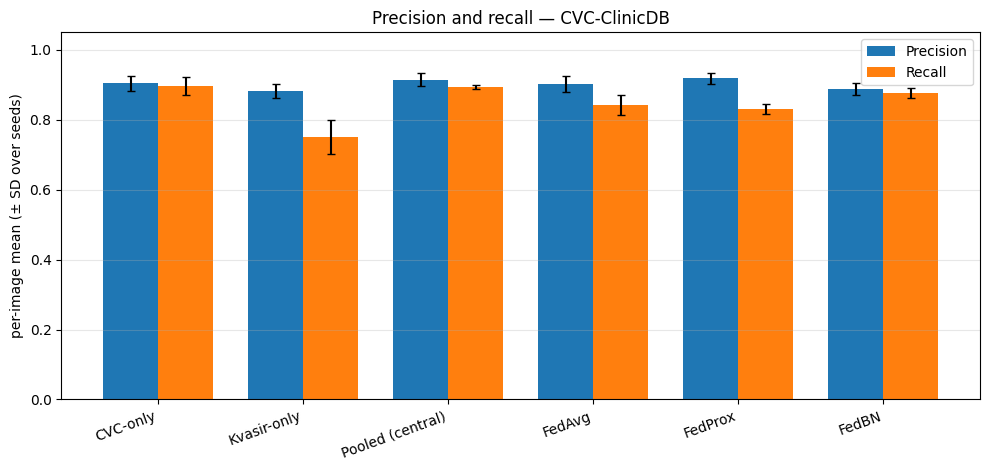

NOTE: precision/recall per image ka mean hain (Dice/IoU jaisa protocol), pixel-pooled nahi. 'empty pred' = wo images jin par model ne koi pixel predict nahi kiya (precision un par undefined, mean se bahar).


In [26]:
# ===== K1: Precision / Recall (per image, mean ± SD over seeds) — saare models, saare test sets (CVC-ClinicDB khaas) =====
# Saved weights se inference dobara chalata hai (GPU, lagbhag 10-15 min). Har (model, seed) disk par save hota hai -> resumable.
# Kahan chalana: B4 + C0 ke baad, kisi bhi waqt (kisi purane cell par depend nahi). Notebook ke aakhir mein naya cell.
# Variables (C0 se): CFG, TEST, NAMES, SEEDS, FED, build, evaluate_arrays, have
# Protocol: Dice/IoU jaisa — per-image, threshold 0.5, 352x352, SAME test images; FedBN: in-domain set apne client ke BN se,
#           baaki sets par dono client models ka average (eval_federated jaisa).
# Precision: jin images par model ne KUCH predict hi nahi kiya (tp+fp = 0), precision undefined hai -> unhein precision ke mean se
#           bahar rakha gaya aur alag column "empty pred (%)" mein dikhaya (warna eps ki wajah se precision = 1 ban jata).
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PR_SETS = list(TEST)          # sab 5 sets. Sirf CVC-ClinicDB chahiye to: PR_SETS = ["cvc"]
PR_DIR  = os.path.join(FED, "pr_metrics")


def _pr_run():
    os.makedirs(PR_DIR, exist_ok=True)
    fl_modes = {"FedAvg": "fedavg", "FedProx": "fedprox", "FedBN": "fedbn"}
    avail = {n: v for n, v in CFG.items() if have(*v)}
    print("Models:", list(avail), "| sets:", PR_SETS, "| seeds:", SEEDS)

    def per_image(m, Xt, Yt):
        _, per, _ = evaluate_arrays(m, Xt, Yt, bs=4)
        tp, fp, fn = per["tp"], per["fp"], per["fn"]
        prec = np.where(tp + fp > 0, tp / np.maximum(tp + fp, 1), np.nan)
        rec = np.where(tp + fn > 0, tp / np.maximum(tp + fn, 1), np.nan)
        return prec, rec, per["dice"], (tp + fp == 0).astype(float)

    def seed_result(name, tag, folder, seed, m):
        res = {}
        if name == "FedBN":
            ckpts = {c: f"{folder}/{tag}_seed{seed}_client{c}.weights.h5" for c in (0, 1)}
            if not all(os.path.exists(p) for p in ckpts.values()):
                return None
            use = {k: ([{"kvasir": 0, "cvc": 1}[k]] if k in ("kvasir", "cvc") else [0, 1]) for k in PR_SETS}
            tmp = {k: [] for k in PR_SETS}
            for c in (0, 1):                                    # har client ka weights ek hi baar load
                need = [k for k in PR_SETS if c in use[k]]
                if not need:
                    continue
                m.load_weights(ckpts[c])
                for k in need:
                    tmp[k].append(per_image(m, *TEST[k]))
            out = {}
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                for k in PR_SETS:
                    arr = tmp[k]
                    out[k] = tuple(arr[0][i] if len(arr) == 1 else np.nanmean(np.stack([a[i] for a in arr]), 0) for i in range(4))
            return out
        ck = f"{folder}/{tag}_seed{seed}.weights.h5"
        if not os.path.exists(ck):
            return None
        m.load_weights(ck)
        return {k: per_image(m, *TEST[k]) for k in PR_SETS}

    m = build()
    rows = []                                                   # seed-level means
    for name, (tag, folder) in avail.items():
        for seed in SEEDS:
            cp = os.path.join(PR_DIR, f"{name.replace(' ', '_').replace('(', '').replace(')', '')}_seed{seed}.npz")
            if os.path.exists(cp) and all(f"prec__{k}" in np.load(cp) for k in PR_SETS):
                z = np.load(cp)
                got = {k: (z[f"prec__{k}"], z[f"rec__{k}"], z[f"dice__{k}"], z[f"empty__{k}"]) for k in PR_SETS}
                print(f"[{name} seed {seed}] disk se load", flush=True)
            else:
                print(f"[{name} seed {seed}] inference ...", flush=True)
                got = seed_result(name, tag, folder, seed, m)
                if got is None:
                    print("   weights nahi mile -> skip"); continue
                np.savez(cp, **{f"{a}__{k}": got[k][i] for k in PR_SETS for i, a in enumerate(("prec", "rec", "dice", "empty"))})
            for k in PR_SETS:
                p, r, d, e = got[k]
                rows.append({"model": name, "seed": seed, "set": k, "precision": np.nanmean(p) if np.isfinite(p).any() else np.nan,
                             "recall": np.nanmean(r), "dice": float(np.mean(d)), "empty_pct": 100 * float(np.mean(e > 0.5))})
    import tensorflow as tf
    tf.keras.backend.clear_session()
    df = pd.DataFrame(rows)
    if df.empty:
        print("Koi result nahi bana."); return
    order = [n for n in avail if n in df["model"].unique()]

    def ms(x):
        x = np.asarray(x, float); x = x[np.isfinite(x)]
        return f"{x.mean():.3f} ± {x.std(ddof=1) if len(x) > 1 else 0:.3f}" if len(x) else "-"
    for k in PR_SETS:
        sub = df[df["set"] == k]
        tab = pd.DataFrame([{"model": n, "seeds": int((sub["model"] == n).sum()),
                             "precision": ms(sub[sub["model"] == n]["precision"]), "recall": ms(sub[sub["model"] == n]["recall"]),
                             "Dice (check)": ms(sub[sub["model"] == n]["dice"]),
                             "empty pred (%)": f"{sub[sub['model'] == n]['empty_pct'].mean():.1f}"} for n in order])
        print(f"\n--- {NAMES[k]} | per-image mean ± SD over seeds ---")
        display(tab)

    show = "cvc" if "cvc" in PR_SETS else PR_SETS[0]
    sub = df[df["set"] == show]
    fig, ax = plt.subplots(figsize=(10, 4.8)); w = 0.38; xs = np.arange(len(order))
    for j, (col, lab) in enumerate((("precision", "Precision"), ("recall", "Recall"))):
        mu = [sub[sub["model"] == n][col].mean() for n in order]
        sd = [sub[sub["model"] == n][col].std(ddof=1) if (sub["model"] == n).sum() > 1 else 0 for n in order]
        ax.bar(xs + (j - 0.5) * w, mu, w, yerr=sd, capsize=3, label=lab)
    ax.set_xticks(xs); ax.set_xticklabels(order, rotation=20, ha="right"); ax.set_ylim(0, 1.05)
    ax.set_ylabel("per-image mean (± SD over seeds)"); ax.set_title(f"Precision and recall — {NAMES[show]}")
    ax.legend(); ax.grid(axis="y", alpha=0.3); plt.tight_layout(); plt.show()
    print("NOTE: precision/recall per image ka mean hain (Dice/IoU jaisa protocol), pixel-pooled nahi. "
          "'empty pred' = wo images jin par model ne koi pixel predict nahi kiya (precision un par undefined, mean se bahar).")
    return df


_pr_df = _pr_run()

In [27]:
# ===== L1: Inference time — mean ± SD, median, p95 (ms), FPS; GPU batch 1 / batch 8 / end-to-end, aur optional CPU =====
# Training nahi hoti. Hamare saare 6 variants (CVC-only, Kvasir-only, Pooled, FedAvg, FedProx, FedBN) ek hi architecture hain,
# isliye ek model naapna kaafi hai (weights se speed nahi badalti).
# Kahan chalana: notebook ke aakhir mein naya cell, jab GPU par koi aur cell na chal raha ho (warna timing kharab hogi).
# Variables / functions (C0 se): build, TEST, SEEDS, FED, IMG_SIZE, to_model_input, binarize
import os, time
import numpy as np
import pandas as pd
import tensorflow as tf
from IPython.display import display

INFER_CPU = True     # CPU par bhi naapein (alag, kam runs). Nahi chahiye to False
N_WARM, N_RUN, N_RUN_CPU = 20, 200, 15


def _infer_time():
    def stats(t):
        t = np.asarray(t, float)
        return {"mean ± SD (ms)": f"{t.mean():.1f} ± {t.std(ddof=1):.1f}", "median (ms)": round(float(np.median(t)), 1),
                "p95 (ms)": round(float(np.percentile(t, 95)), 1)}

    def bench(fn, n_warm, n_run):
        for _ in range(n_warm):
            fn()
        t = []
        for _ in range(n_run):
            t0 = time.perf_counter(); fn(); t.append((time.perf_counter() - t0) * 1000.0)
        return np.array(t)

    def run_device(device, n_run):
        rows = []
        with tf.device(device):
            m = build()
            ck = f"{FED}/pooled_seed{SEEDS[0]}.weights.h5"
            if os.path.exists(ck):
                m.load_weights(ck)
            x8 = TEST["cvc"][0][:8]                                           # asli test images
            x1 = x8[:1]
            xp1, xp8 = to_model_input(x1), to_model_input(x8)

            t = bench(lambda: m.predict_on_batch(xp1), N_WARM, n_run)          # predict_on_batch numpy deta hai -> GPU sync
            rows.append({"setting": "model only, batch 1", **stats(t), "FPS": round(1000.0 / t.mean(), 1)})
            t = bench(lambda: m.predict_on_batch(xp8), max(3, N_WARM // 4), max(10, n_run // 4))
            rows.append({"setting": "model only, batch 8 (per image)", **stats(t / 8.0), "FPS": round(8000.0 / t.mean(), 1)})
            t = bench(lambda: binarize(m.predict_on_batch(to_model_input(x1)), 0.5, False), N_WARM, n_run)
            rows.append({"setting": "end-to-end, batch 1 (preprocess + model + threshold)", **stats(t), "FPS": round(1000.0 / t.mean(), 1)})
            tf.keras.backend.clear_session()
        return rows

    gpus = tf.config.list_physical_devices("GPU")
    info = []
    if gpus:
        try:
            info.append("GPU: " + tf.config.experimental.get_device_details(gpus[0]).get("device_name", "unknown"))
        except Exception:
            info.append("GPU: (naam nahi mila)")
    info += [f"CPU cores: {os.cpu_count()}", f"TensorFlow {tf.__version__}", f"input {IMG_SIZE}x{IMG_SIZE}, float32"]
    print(" | ".join(info))
    out = []
    if gpus:
        for r in run_device("/GPU:0", N_RUN):
            out.append({"device": "GPU", **r})
    if INFER_CPU or not gpus:
        for r in run_device("/CPU:0", N_RUN_CPU):
            out.append({"device": "CPU", **r})
    df = pd.DataFrame(out)
    display(df)
    print("NOTE: ye hamari hardware par ki timing hai; published methods ki latency/FPS (alag GPU, alag setup) se seedha compare na karein. "
          "Paper mein GPU model ka naam, batch size aur resolution zaroor likhein.")
    return df


_infer_df = _infer_time()

GPU: NVIDIA GeForce RTX 3080 | CPU cores: 16 | TensorFlow 2.12.0 | input 352x352, float32


,device,setting,mean ± SD (ms),median (ms),p95 (ms),FPS
0,GPU,"model only, batch 1",17.6 ± 4.1,15.5,26.2,56.7
1,GPU,"model only, batch 8 (per image)",9.4 ± 0.2,9.4,9.7,106.2
2,GPU,"end-to-end, batch 1 (preprocess + model + threshold)",17.2 ± 4.2,15.4,26.7,58.1
3,CPU,"model only, batch 1",148.7 ± 3.9,148.8,153.7,6.7
4,CPU,"model only, batch 8 (per image)",163.7 ± 4.3,164.0,169.7,6.1
5,CPU,"end-to-end, batch 1 (preprocess + model + threshold)",140.6 ± 4.7,140.5,147.9,7.1


NOTE: ye hamari hardware par ki timing hai; published methods ki latency/FPS (alag GPU, alag setup) se seedha compare na karein. Paper mein GPU model ka naam, batch size aur resolution zaroor likhein.


In [28]:
# ===== V1: Val Dice vs Test Dice (reviewer row 11: "Val Dice = Test Dice suspicion") — CVC-only model, har seed =====
Xv, Yv = D["cvc"]["val"]
Xt, Yt = D["cvc"]["test"]
rows = []
for s in SEEDS:
    ck = f"{CVC_DIR}/cvc_main_seed{s}.weights.h5"
    if not os.path.exists(ck):
        continue
    m = load_trained(build, ck)
    _, pv, _ = evaluate_arrays(m, Xv, Yv)
    _, pt, _ = evaluate_arrays(m, Xt, Yt)
    rows.append({"seed": s, f"val mDice (n={len(Xv)}, checkpoint isi par chuna)": round(float(pv["dice"].mean()), 4),
                 f"test mDice (n={len(Xt)})": round(float(pt["dice"].mean()), 4)})
    del m
    free_gpu_memory()
tab = pd.DataFrame(rows)
tab["val - test"] = (tab.iloc[:, 1] - tab.iloc[:, 2]).round(4)
display(tab)
print(f"mean ± SD over seeds -> val: {pm(tab.iloc[:, 1])} | test: {pm(tab.iloc[:, 2])} | val - test: {tab['val - test'].mean():+.4f}")
print("Padhne ka tareeqa: val par checkpoint chuna gaya hai, isliye val thoda zyada aana normal hai. Shak tab hota jab val aur test "
      "lagbhag HAR seed mein barabar hon (3 decimals tak), ya test val se bahut zyada ho.")

,seed,"val mDice (n=55, checkpoint isi par chuna)",test mDice (n=62),val - test
0,42,0.8993,0.8967,0.0026
1,123,0.9158,0.8735,0.0423
2,2024,0.9091,0.8837,0.0254
3,7,0.9211,0.8735,0.0476
4,99,0.9274,0.8752,0.0522


mean ± SD over seeds -> val: 0.915 ± 0.011 | test: 0.881 ± 0.010 | val - test: +0.0340
Padhne ka tareeqa: val par checkpoint chuna gaya hai, isliye val thoda zyada aana normal hai. Shak tab hota jab val aur test lagbhag HAR seed mein barabar hon (3 decimals tak), ya test val se bahut zyada ho.


In [29]:
# ===== V2: Frozen / scratch "collapse" check (reviewer 2.7): precision, recall, predicted polyp area vs asli (GT) area — CVC test =====
variants = {"Proposed (fine-tuned)": ("cvc_main",    build),
            "Frozen encoder":        ("cvc_frozen",  lambda: build_unet_resnet50(IMG_SIZE, freeze_encoder=True)),
            "No ImageNet (scratch)": ("cvc_scratch", lambda: build_unet_resnet50(IMG_SIZE, weights=None))}
Xt, Yt = D["cvc"]["test"]
gt = Yt[..., 0] > 0.5
rows = []
for name, (tag, bf) in variants.items():
    st = []
    for s in SEEDS:
        ck = f"{CVC_DIR}/{tag}_seed{s}.weights.h5"
        if not os.path.exists(ck):
            continue
        m = load_trained(bf, ck)
        _, per, probs = evaluate_arrays(m, Xt, Yt)
        pr = probs[..., 0] > 0.5
        tp, fp, fn = int((pr & gt).sum()), int((pr & ~gt).sum()), int((~pr & gt).sum())
        st.append((per["dice"].mean(), tp / max(tp + fp, 1), tp / max(tp + fn, 1), 100 * pr.mean(), 100 * gt.mean()))
        del m
        free_gpu_memory()
    if st:
        a = np.array(st)
        rows.append({"model": name, "seeds": len(st), "mDice": pm(a[:, 0]), "precision (pixel-pooled)": pm(a[:, 1]), "recall (pixel-pooled)": pm(a[:, 2]),
                     "predicted polyp area (% of image)": pm(a[:, 3], 1), "ground-truth polyp area (% of image)": f"{a[0, 4]:.1f}"})
display(pd.DataFrame(rows))
print("Degenerate (collapsed) model: precision bohat kam + recall ~1 + predicted area GT area se kai guna zyada (reviewer ke purane model mein ~77% image). "
      "Agar predicted area GT ke qareeb hai to frozen encoder 'collapse' nahi hua.")

,model,seeds,mDice,precision (pixel-pooled),recall (pixel-pooled),predicted polyp area (% of image),ground-truth polyp area (% of image)
0,Proposed (fine-tuned),5,0.881 ± 0.010,0.933 ± 0.010,0.920 ± 0.015,7.9 ± 0.2,8.0
1,Frozen encoder,5,0.855 ± 0.009,0.931 ± 0.013,0.854 ± 0.015,7.3 ± 0.2,8.0
2,No ImageNet (scratch),5,0.763 ± 0.013,0.872 ± 0.043,0.725 ± 0.014,6.7 ± 0.4,8.0


Degenerate (collapsed) model: precision bohat kam + recall ~1 + predicted area GT area se kai guna zyada (reviewer ke purane model mein ~77% image). Agar predicted area GT ke qareeb hai to frozen encoder 'collapse' nahi hua.


Instructions for updating:
This API was designed for TensorFlow v1. See https://www.tensorflow.org/guide/migrate for instructions on how to migrate your code to TensorFlow v2.


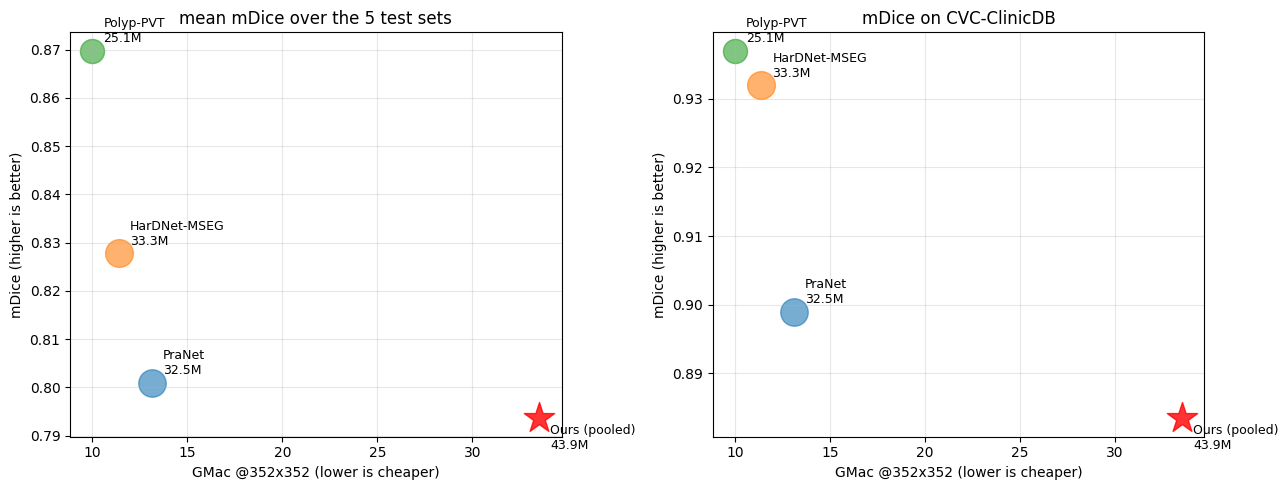

UACANet plot mein nahi: uska verified params/GMac nahi mila (G1 note dekhein). Published GMac/params teesre papers ke measured numbers hain.


In [6]:
# ===== V3: Accuracy-vs-efficiency plot (reviewer row 12, purana Fig. 35 jaisa): mDice vs GMac @352 (circle size = params) =====
PUB = {   # (params M, GMac@352, mDice [Kvasir, CVC-ClinicDB, CVC-300, ColonDB, ETIS]) — G1 aur C1 (SOTA) cells ke numbers
    "PraNet":       (32.55, 13.11, [0.898, 0.899, 0.871, 0.709, 0.628]),
    "HarDNet-MSEG": (33.34, 11.38, [0.912, 0.932, 0.887, 0.731, 0.677]),
    "Polyp-PVT":    (25.1,  10.0,  [0.917, 0.937, 0.900, 0.808, 0.787]),
}
m = build()
rep = efficiency_report(m, IMG_SIZE)
del m
free_gpu_memory()
ours_gmac, ours_params = rep["gflops"] / 2, rep["params_M"]
ours = [float(np.mean([a.mean() for a in load_dice("pooled", SEEDS, k, FED)])) for k in TEST]    # Pooled (central) = like-for-like row; TEST order = Kvasir, CVC, CVC-300, ColonDB, ETIS

fig, axs = plt.subplots(1, 2, figsize=(13, 5))
for ax, idx, title in ((axs[0], None, "mean mDice over the 5 test sets"), (axs[1], 1, "mDice on CVC-ClinicDB")):
    for name, (p, g, d) in PUB.items():
        y = float(np.mean(d)) if idx is None else d[idx]
        ax.scatter(g, y, s=p * 12, alpha=0.6); ax.annotate(f"{name}\n{p:.1f}M", (g, y), textcoords="offset points", xytext=(8, 6), fontsize=9)
    y = float(np.mean(ours)) if idx is None else ours[idx]
    ax.scatter(ours_gmac, y, s=ours_params * 12, marker="*", color="red", alpha=0.8); ax.annotate(f"Ours (pooled)\n{ours_params:.1f}M", (ours_gmac, y), textcoords="offset points", xytext=(8, -22), fontsize=9)
    ax.set_xlabel("GMac @352x352 (lower is cheaper)"); ax.set_ylabel("mDice (higher is better)"); ax.set_title(title); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print("UACANet plot mein nahi: uska verified params/GMac nahi mila (G1 note dekhein). Published GMac/params teesre papers ke measured numbers hain.")

[CVC-only seed 42] robustness ...


[Kvasir-only seed 42] robustness ...


[Pooled (central) seed 42] robustness ...


[FedAvg seed 42] robustness ...


[FedProx seed 42] robustness ...


...

[FedBN seed 2024] robustness ...


Seeds per model: {'CVC-only': 3, 'Kvasir-only': 3, 'Pooled (central)': 3, 'FedAvg': 3, 'FedProx': 3, 'FedBN': 3}

--- Kvasir-SEG: relative robustness = mean(corrupted Dice, sev 1-5) / clean Dice (1.0 = koi girawat nahi); mean ± SD over seeds ---


,model,seeds,clean mDice,overall relative robustness,Gaussian Noise,Gaussian Blur,Brightness/Contrast,JPEG Compression,Motion Blur
0,CVC-only,3,0.789 ± 0.009,0.956 ± 0.013,0.906 ± 0.080,0.999 ± 0.013,0.995 ± 0.001,0.949 ± 0.010,0.930 ± 0.008
1,Kvasir-only,3,0.891 ± 0.011,0.908 ± 0.009,0.830 ± 0.052,0.936 ± 0.035,0.989 ± 0.001,0.930 ± 0.015,0.855 ± 0.026
2,Pooled (central),3,0.886 ± 0.013,0.932 ± 0.014,0.863 ± 0.060,0.960 ± 0.009,0.992 ± 0.002,0.948 ± 0.016,0.896 ± 0.007
3,FedAvg,3,0.884 ± 0.010,0.938 ± 0.006,0.857 ± 0.036,0.981 ± 0.011,0.992 ± 0.004,0.945 ± 0.015,0.915 ± 0.008
4,FedProx,3,0.883 ± 0.003,0.938 ± 0.009,0.872 ± 0.044,0.971 ± 0.016,0.994 ± 0.002,0.957 ± 0.011,0.898 ± 0.008
5,FedBN,3,0.879 ± 0.013,0.933 ± 0.010,0.839 ± 0.042,0.982 ± 0.009,0.989 ± 0.013,0.961 ± 0.013,0.891 ± 0.021



--- CVC-ClinicDB: relative robustness = mean(corrupted Dice, sev 1-5) / clean Dice (1.0 = koi girawat nahi); mean ± SD over seeds ---


,model,seeds,clean mDice,overall relative robustness,Gaussian Noise,Gaussian Blur,Brightness/Contrast,JPEG Compression,Motion Blur
0,CVC-only,3,0.885 ± 0.012,0.886 ± 0.031,0.701 ± 0.115,0.975 ± 0.009,0.976 ± 0.013,0.912 ± 0.011,0.867 ± 0.015
1,Kvasir-only,3,0.732 ± 0.044,0.744 ± 0.031,0.506 ± 0.092,0.841 ± 0.119,0.902 ± 0.023,0.794 ± 0.016,0.677 ± 0.092
2,Pooled (central),3,0.887 ± 0.015,0.855 ± 0.019,0.604 ± 0.073,0.956 ± 0.017,0.973 ± 0.002,0.867 ± 0.013,0.875 ± 0.012
3,FedAvg,3,0.842 ± 0.015,0.818 ± 0.030,0.531 ± 0.088,0.952 ± 0.011,0.945 ± 0.011,0.855 ± 0.017,0.808 ± 0.031
4,FedProx,3,0.830 ± 0.008,0.837 ± 0.015,0.619 ± 0.045,0.957 ± 0.011,0.955 ± 0.005,0.856 ± 0.015,0.801 ± 0.028
5,FedBN,3,0.857 ± 0.013,0.830 ± 0.023,0.553 ± 0.115,0.930 ± 0.037,0.978 ± 0.017,0.854 ± 0.013,0.833 ± 0.034


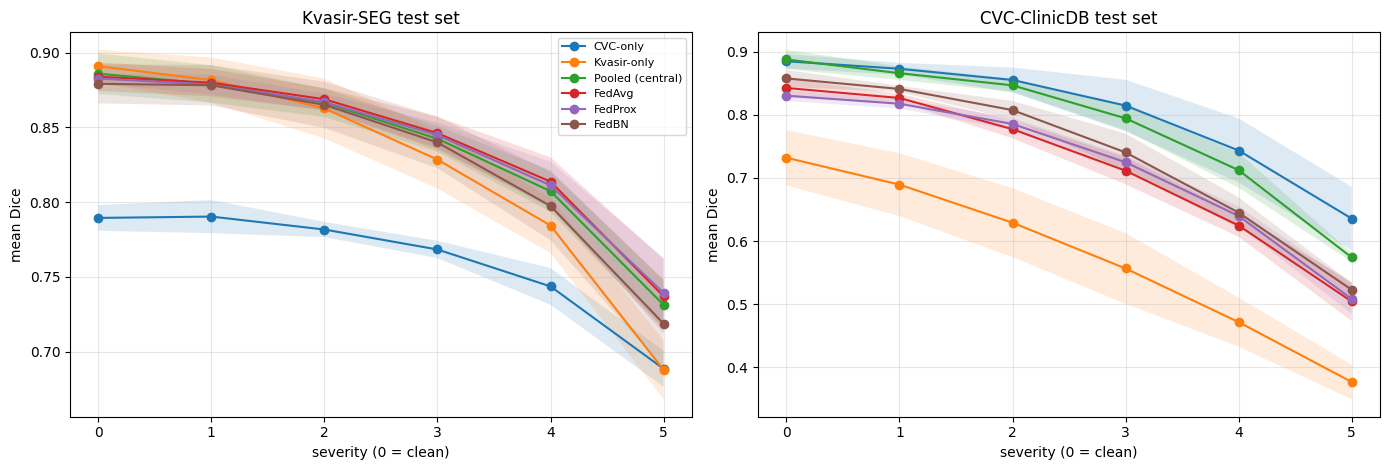

In [31]:
# ===== M1: Robustness — SAARE 6 models (FedBN bhi) x 3 seeds, poora test set, severity 0..5 (reviewer Step 7) =====
# D2 sirf seed 42 par tha aur FedBN us mein nahi tha. Ye cell dono kami poori karta hai.
# Resumable: har (model, seed) disk par save (results_fed/robust_multiseed/*.pkl). GPU chahiye (~30-60 min, GPU ke hisaab se).
# Kahan chalana: notebook ke aakhir mein naya cell, jab GPU par koi aur cell na chal raha ho.
# Variables (C0 se): CFG, TEST, NAMES, SEEDS, FED, build, robustness_eval, relative_robustness, free_gpu_memory
# FedBN: Kvasir test set apne client-0 BN se, CVC test set client-1 BN se (B4 ki evaluation jaisa).
import os, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROB_SEEDS  = SEEDS[:3]                      # time kam/zyada karna ho to badlein
ROB_SETS   = ["kvasir", "cvc"]              # D2 jaisa; saare 5 sets chahiye to: list(TEST)
ROB_MODELS = ["CVC-only", "Kvasir-only", "Pooled (central)", "FedAvg", "FedProx", "FedBN"]
ROB_DIR    = os.path.join(FED, "robust_multiseed")


def _rob_run():
    os.makedirs(ROB_DIR, exist_ok=True)
    slug = lambda n: n.replace(" ", "_").replace("(", "").replace(")", "")
    path = lambda n, s: os.path.join(ROB_DIR, f"{slug(n)}_seed{s}.pkl")
    m = build()

    def one(name, seed):
        tag, folder = CFG[name]
        out = {}
        for ds in ROB_SETS:
            if name == "FedBN":
                ck = f"{folder}/{tag}_seed{seed}_client{ {'kvasir': 0, 'cvc': 1}.get(ds, 0) }.weights.h5"
            else:
                ck = f"{folder}/{tag}_seed{seed}.weights.h5"
            if not os.path.exists(ck):
                return None
            m.load_weights(ck)
            out[ds] = robustness_eval(m, *TEST[ds])          # {corruption: [Dice sev0(clean), sev1..sev5]}
        return out

    res = {}
    for seed in ROB_SEEDS:
        for name in ROB_MODELS:
            p = path(name, seed)
            if os.path.exists(p):
                res[(name, seed)] = pickle.load(open(p, "rb")); print(f"[{name} seed {seed}] disk se load", flush=True); continue
            print(f"[{name} seed {seed}] robustness ...", flush=True)
            r = one(name, seed)
            if r is None:
                print("   weights nahi mile -> skip"); continue
            pickle.dump(r, open(p, "wb")); res[(name, seed)] = r
    free_gpu_memory()                                         # sab inference ke baad ek baar GPU saaf
    if not res:
        print("Koi result nahi bana."); return
    names = [n for n in ROB_MODELS if any((n, s) in res for s in ROB_SEEDS)]
    print("Seeds per model:", {n: sum((n, s) in res for s in ROB_SEEDS) for n in names})
    ms = lambda x: f"{np.mean(x):.3f} ± {(np.std(x, ddof=1) if len(x) > 1 else 0):.3f}"

    for ds in ROB_SETS:                                       # 1) overall relative robustness + clean Dice
        rows = []
        for n in names:
            rr = [relative_robustness(res[(n, s)][ds]) for s in ROB_SEEDS if (n, s) in res]
            clean = [float(np.mean([v[0] for v in res[(n, s)][ds].values()])) for s in ROB_SEEDS if (n, s) in res]
            row = {"model": n, "seeds": len(rr), "clean mDice": ms(clean), "overall relative robustness": ms([r["overall"] for r in rr])}
            for c in rr[0]:
                if c != "overall":
                    row[c] = ms([r[c] for r in rr])
            rows.append(row)
        print(f"\n--- {NAMES[ds]}: relative robustness = mean(corrupted Dice, sev 1-5) / clean Dice (1.0 = koi girawat nahi); mean ± SD over seeds ---")
        display(pd.DataFrame(rows))

    fig, axs = plt.subplots(1, len(ROB_SETS), figsize=(7 * len(ROB_SETS), 4.8), squeeze=False)
    for ax, ds in zip(axs[0], ROB_SETS):                      # 2) severity curve, corruptions par average, seeds par mean ± SD
        for n in names:
            curves = np.array([np.mean([v for v in res[(n, s)][ds].values()], axis=0) for s in ROB_SEEDS if (n, s) in res])
            mu, sd = curves.mean(0), (curves.std(0, ddof=1) if len(curves) > 1 else np.zeros(curves.shape[1]))
            ax.plot(range(curves.shape[1]), mu, marker="o", label=n); ax.fill_between(range(curves.shape[1]), mu - sd, mu + sd, alpha=0.15)
        ax.set_title(f"{NAMES[ds]} test set"); ax.set_xlabel("severity (0 = clean)"); ax.set_ylabel("mean Dice"); ax.grid(alpha=0.3)
    axs[0][0].legend(fontsize=8); plt.tight_layout(); plt.show()
    return res


_rob_res = _rob_run()

In [32]:
# ===== N1: HD95 + S-measure (S_alpha) — FedBN (D3 mein nahi tha), 5 seeds x 5 test sets, D3 ke SAME format mein =====
# D3 ne CVC-only / Kvasir-only / Pooled / FedAvg / FedProx cover kiye. Ye cell sirf FedBN ki row poori karta hai (+ n_empty).
# Kahan chalana: D3 ke baad (ya kabhi bhi, C0 ke baad). GPU chahiye (~5-10 min). Resumable: har seed disk par save.
# Variables (C0 se): CFG, TEST, NAMES, SEEDS, FED, build, evaluate_arrays, hd95_batch, free_gpu_memory
# FedBN: Kvasir/CVC test apne client ke BN se; baaki 3 sets par dono clients ka per-image average (eval_federated jaisa).
import os, pickle, warnings
import numpy as np
import pandas as pd
from IPython.display import display

HDN_SEEDS = SEEDS                         # D3 jaisa: saare seeds
HDN_DIR   = os.path.join(FED, "hd95_fedbn")


def _s_measure(pred, gt, eps=1e-8):       # D3 wala hi implementation (Fan et al., ICCV 2017, alpha = 0.5)
    pred = np.asarray(pred, np.float64); gt = (np.asarray(gt) > 0.5).astype(np.float64)
    y = gt.mean()
    if y == 0: return float(1.0 - pred.mean())
    if y == 1: return float(pred.mean())
    def s_obj(p, g):
        x = p[g == 1].mean(); sd = p[g == 1].std(ddof=1) if (g == 1).sum() > 1 else 0.0
        return 2 * x / (x ** 2 + 1 + sd + eps)
    s_object = y * s_obj(pred * gt, gt) + (1 - y) * s_obj((1 - pred) * (1 - gt), 1 - gt)
    h, w = gt.shape
    rows, cols = np.arange(1, h + 1), np.arange(1, w + 1)
    cx = int(np.clip(round((gt.sum(0) * cols).sum() / gt.sum()), 1, w - 1)); cy = int(np.clip(round((gt.sum(1) * rows).sum() / gt.sum()), 1, h - 1))
    def ssim(p, g):
        if p.size == 0: return 0.0
        n = p.size; mp, mg = p.mean(), g.mean()
        vp, vg, cpg = ((p - mp) ** 2).sum() / (n - 1 + eps), ((g - mg) ** 2).sum() / (n - 1 + eps), ((p - mp) * (g - mg)).sum() / (n - 1 + eps)
        a, b = 4 * mp * mg * cpg, (mp ** 2 + mg ** 2) * (vp + vg)
        return a / (b + eps) if a != 0 else (1.0 if b == 0 else 0.0)
    area = h * w
    parts = [(slice(0, cy), slice(0, cx), cx * cy / area), (slice(0, cy), slice(cx, w), (w - cx) * cy / area),
             (slice(cy, h), slice(0, cx), cx * (h - cy) / area), (slice(cy, h), slice(cx, w), (w - cx) * (h - cy) / area)]
    s_region = sum(wt * ssim(pred[r, c], gt[r, c]) for r, c, wt in parts)
    return float(max(0.0, 0.5 * s_object + 0.5 * s_region))


def _hdn_run():
    os.makedirs(HDN_DIR, exist_ok=True)
    tag, folder = CFG["FedBN"]
    m = build()
    store = {k: [] for k in TEST}                          # set -> [(hd95_mean, s_mean, n_empty) per seed]
    for seed in HDN_SEEDS:
        cp = os.path.join(HDN_DIR, f"FedBN_seed{seed}.pkl")
        if os.path.exists(cp):
            res = pickle.load(open(cp, "rb")); print(f"[FedBN seed {seed}] disk se load", flush=True)
        else:
            ck = {c: f"{folder}/{tag}_seed{seed}_client{c}.weights.h5" for c in (0, 1)}
            if not all(os.path.exists(p) for p in ck.values()):
                print(f"[FedBN seed {seed}] weights nahi mile -> skip"); continue
            print(f"[FedBN seed {seed}] inference ...", flush=True)
            per = {k: [] for k in TEST}
            for c in (0, 1):
                use = [k for k in TEST if (k == "kvasir" and c == 0) or (k == "cvc" and c == 1) or k not in ("kvasir", "cvc")]
                m.load_weights(ck[c])
                for k in use:
                    X, Y = TEST[k]
                    _, _, probs = evaluate_arrays(m, X, Y)
                    hd, n_empty = hd95_batch(Y, probs)
                    sm = np.array([_s_measure(probs[i, ..., 0], Y[i, ..., 0]) for i in range(len(X))])
                    per[k].append((hd, sm, n_empty))
            res = {k: (np.mean([a[0] for a in v], 0), np.mean([a[1] for a in v], 0), float(np.mean([a[2] for a in v])))
                   for k, v in per.items()}                # dono clients ka per-image average (unseen sets), ek client (in-domain)
            pickle.dump(res, open(cp, "wb"))
        for k, (hd, sm, ne) in res.items():
            store[k].append((float(np.mean(hd)), float(np.mean(sm)), ne))
    free_gpu_memory()
    if not any(store.values()):
        print("Koi result nahi bana."); return
    ms = lambda x, nd: f"{np.mean(x):.{nd}f} ± {(np.std(x, ddof=1) if len(x) > 1 else 0):.{nd}f}"
    ks = list(TEST)
    out = {}
    for title, idx, nd in (("HD95 (pixels, KAM behtar) — mean ± SD over seeds:", 0, 1), ("S-measure S_alpha (ZYADA behtar) — mean ± SD over seeds:", 1, 3),
                           ("Khali prediction wali images (seed-average) — HD95 par diagonal penalty:", 2, 1)):
        print("\n" + title)
        display(pd.DataFrame([{NAMES[k]: ms([t[idx] for t in store[k]], nd) for k in ks}], index=["FedBN"]))
    print("Seeds used:", len(store[ks[0]]), "| ye FedBN ki row hai: D3 ki table ke neeche jod kar paper ki table banayein.")
    return store


_hdn_store = _hdn_run()

[FedBN seed 42] inference ...


[FedBN seed 123] inference ...


[FedBN seed 2024] inference ...


[FedBN seed 7] inference ...


[FedBN seed 99] inference ...


...


S-measure S_alpha (ZYADA behtar) — mean ± SD over seeds:


,Kvasir-SEG,CVC-ClinicDB,CVC-300,CVC-ColonDB,ETIS
FedBN,0.901 ± 0.005,0.900 ± 0.010,0.920 ± 0.008,0.794 ± 0.010,0.782 ± 0.019



Khali prediction wali images (seed-average) — HD95 par diagonal penalty:


,Kvasir-SEG,CVC-ClinicDB,CVC-300,CVC-ColonDB,ETIS
FedBN,1.2 ± 1.6,2.8 ± 1.3,0.5 ± 0.5,78.9 ± 12.1,45.1 ± 11.3


Seeds used: 5 | ye FedBN ki row hai: D3 ki table ke neeche jod kar paper ki table banayein.


In [33]:
# ===== O1: Model-randomisation sanity check (Adebayo et al.) — SAARE 6 models, Kvasir + CVC test, same protocol =====
# A5 mein ye check sirf CVC-only par tha. Reviewer (Step 6): XAI mein sanity check -> yahan har model par, ek jaisa protocol.
# Dekhna: trained Grad-CAM++ ka AUPRC ZYADA hona chahiye, random-weights wale ka KAM (aur Spearman correlation kam).
# Kahan chalana: notebook ke aakhir mein naya cell (GPU chahiye, kuch minute). Resumable nahi (chhota hai).
# Variables (C0 se): CFG, TEST, NAMES, SEEDS, build, build_unet_resnet50, IMG_SIZE, randomization_check, free_gpu_memory
import os
import numpy as np
import pandas as pd
from IPython.display import display

RAND_N     = 20                     # images per set (A5 jaisa 20). Zyada chahiye to 30-50
RAND_SEEDS = SEEDS[:1]              # training seeds; zyada: SEEDS[:3]
RAND_MODELS = ["CVC-only", "Kvasir-only", "Pooled (central)", "FedAvg", "FedProx", "FedBN"]


def _rand_run():
    m = build()
    rows = []
    for name in RAND_MODELS:
        tag, folder = CFG[name]
        for seed in RAND_SEEDS:
            for ds in ("kvasir", "cvc"):
                if name == "FedBN":
                    ck = f"{folder}/{tag}_seed{seed}_client{0 if ds == 'kvasir' else 1}.weights.h5"
                else:
                    ck = f"{folder}/{tag}_seed{seed}.weights.h5"
                if not os.path.exists(ck):
                    print(f"[{name} seed {seed}] weights nahi mile -> skip"); break
                m.load_weights(ck)
                X, Y = TEST[ds]
                rc = randomization_check(m, lambda: build_unet_resnet50(IMG_SIZE, weights=None), X, Y, n=RAND_N)
                r = rc.mean()
                rows.append({"model": name, "seed": seed, "test set": NAMES[ds], **{k: float(v) for k, v in r.items()}})
                print(f"[{name} seed {seed} | {NAMES[ds]}] done", flush=True)
    free_gpu_memory()
    df = pd.DataFrame(rows)
    if df.empty:
        print("Koi result nahi bana."); return
    g = df.groupby(["test set", "model"], sort=False).mean(numeric_only=True).drop(columns=["seed"]).round(3)
    for ds in g.index.get_level_values(0).unique():
        print(f"\n--- {ds}: trained vs randomised-weights Grad-CAM++ (mean over {RAND_N} images, seeds {RAND_SEEDS}) ---")
        display(g.loc[ds])
    print("\nSahi natija: auprc_trained, auprc_random_all / auprc_random_decoder se kaafi ZYADA ho, aur spearman_* kam (0 ke qareeb) ho. "
          "Agar random model ka AUPRC trained ke barabar aaye to explanation model par depend nahi karti (problem).")
    return df


_rand_df = _rand_run()

[CVC-only seed 42 | Kvasir-SEG] done
[CVC-only seed 42 | CVC-ClinicDB] done
[Kvasir-only seed 42 | Kvasir-SEG] done
[Kvasir-only seed 42 | CVC-ClinicDB] done
[Pooled (central) seed 42 | Kvasir-SEG] done
[Pooled (central) seed 42 | CVC-ClinicDB] done
[FedAvg seed 42 | Kvasir-SEG] done
[FedAvg seed 42 | CVC-ClinicDB] done
[FedProx seed 42 | Kvasir-SEG] done
[FedProx seed 42 | CVC-ClinicDB] done
[FedBN seed 42 | Kvasir-SEG] done
[FedBN seed 42 | CVC-ClinicDB] done

--- Kvasir-SEG: trained vs randomised-weights Grad-CAM++ (mean over 20 images, seeds [42]) ---


,auprc_trained,spearman_random_all,auprc_random_all,spearman_random_decoder,auprc_random_decoder
model,,,,,
CVC-only,0.919,0.211,0.163,0.446,0.193
Kvasir-only,0.953,0.318,0.197,0.085,0.079
Pooled (central),0.940,0.391,0.238,0.263,0.113
FedAvg,0.923,-0.012,0.118,0.046,0.127
FedProx,0.926,0.056,0.164,0.102,0.113
FedBN,0.926,0.331,0.112,0.321,0.125



--- CVC-ClinicDB: trained vs randomised-weights Grad-CAM++ (mean over 20 images, seeds [42]) ---


,auprc_trained,spearman_random_all,auprc_random_all,spearman_random_decoder,auprc_random_decoder
model,,,,,
CVC-only,0.932,0.094,0.127,0.118,0.105
Kvasir-only,0.845,0.020,0.114,0.096,0.116
Pooled (central),0.931,0.215,0.184,0.267,0.129
FedAvg,0.910,-0.046,0.178,-0.029,0.150
FedProx,0.900,-0.026,0.143,0.022,0.106
FedBN,0.903,0.091,0.076,0.237,0.115



Sahi natija: auprc_trained, auprc_random_all / auprc_random_decoder se kaafi ZYADA ho, aur spearman_* kam (0 ke qareeb) ho. Agar random model ka AUPRC trained ke barabar aaye to explanation model par depend nahi karti (problem).


In [34]:
# ===== P1: Val Dice vs Test Dice (reviewer item 11: "val = test suspicion") — saare models, mean ± SD over seeds =====
# Sirf disk se padhta hai: training history (.json) + per-image test Dice (.npz). GPU / training nahi. Kuch seconds.
# Kahan chalana: notebook ke aakhir mein naya cell. Variables (C0 se): CFG, TEST, SEEDS, CVC_DIR, KV_DIR, FED
# Val = best-validation checkpoint ka Dice (Keras metric, 10% held-out train images: CVC 55, Kvasir 90). Test = official test set ka per-image mDice.
# Dono ka farq (val - test) report hota hai. FL: val = aakhri round ka val_dice_mean (dono clients ka mean), test = Kvasir aur CVC test mDice ka mean.
# NOTE: Keras val metric batch-average hai, per-image mDice thora alag ho sakta hai; isliye farq ko "approximate" likhein.
import os, json
import numpy as np
import pandas as pd
from IPython.display import display


def _val_test():
    ms = lambda x: f"{np.mean(x):.3f} ± {(np.std(x, ddof=1) if len(x) > 1 else 0):.3f}"
    n_kv, n_cvc = len(TEST["kvasir"][0]), len(TEST["cvc"][0])
    def test_dice(tag, folder, seed, keys, w=None):
        z = np.load(f"{folder}/{tag}_seed{seed}.npz")
        vals = [float(np.mean(z[f"dice__{k}"])) for k in keys]
        return float(np.average(vals, weights=w)) if w else float(np.mean(vals))
    rows = []
    centr = [("CVC-only", "cvc_main", CVC_DIR, ["cvc"], None), ("Kvasir-only", "kvasir_main", KV_DIR, ["kvasir"], None),
             ("Pooled (central)", "pooled", FED, ["kvasir", "cvc"], [n_kv, n_cvc])]
    for name, tag, folder, keys, w in centr:
        v, t = [], []
        for s in SEEDS:
            jp, zp = f"{folder}/{tag}_seed{s}.json", f"{folder}/{tag}_seed{s}.npz"
            if not (os.path.exists(jp) and os.path.exists(zp)):
                continue
            h = json.load(open(jp))
            v.append(float(np.max(h["val_dice_coef"]))); t.append(test_dice(tag, folder, s, keys, w))
        if v:
            rows.append({"model": name, "seeds": len(v), "val Dice (best ckpt)": ms(v), "test mDice": ms(t), "val - test": ms(np.array(v) - np.array(t))})
    for name, mode in (("FedAvg", "fedavg"), ("FedProx", "fedprox"), ("FedBN", "fedbn")):
        v, t = [], []
        for s in SEEDS:
            jp, zp = f"{FED}/fl_{mode}_seed{s}_history.json", f"{FED}/fl_{mode}_seed{s}.npz"
            if not (os.path.exists(jp) and os.path.exists(zp)):
                continue
            hist = json.load(open(jp))
            v.append(float(hist[-1]["val_dice_mean"])); t.append(test_dice(f"fl_{mode}", FED, s, ["kvasir", "cvc"]))
        if v:
            rows.append({"model": name, "seeds": len(v), "val Dice (best ckpt)": ms(v), "test mDice": ms(t), "val - test": ms(np.array(v) - np.array(t))})
    df = pd.DataFrame(rows)
    display(df)
    print("Matlab: val - test chhota/musbat = val aur test lagbhag ek jaise (shak kam). Bahut bada farq ya test > val ho to wajah likhein. "
          "CVC-ClinicDB ka val set bhi train ka hissa hai (near-duplicates ke saath), isliye CVC ka val Dice optimistic ho sakta hai.")
    return df


_vt_df = _val_test()

,model,seeds,val Dice (best ckpt),test mDice,val - test
0,CVC-only,5,0.913 ± 0.011,0.881 ± 0.010,0.033 ± 0.021
1,Kvasir-only,5,0.918 ± 0.006,0.889 ± 0.008,0.029 ± 0.008
2,Pooled (central),5,0.920 ± 0.002,0.885 ± 0.011,0.035 ± 0.009
3,FedAvg,5,0.883 ± 0.018,0.857 ± 0.015,0.027 ± 0.006
4,FedProx,5,0.891 ± 0.009,0.857 ± 0.003,0.034 ± 0.010
5,FedBN,5,0.893 ± 0.006,0.866 ± 0.011,0.027 ± 0.009


Matlab: val - test chhota/musbat = val aur test lagbhag ek jaise (shak kam). Bahut bada farq ya test > val ho to wajah likhein. CVC-ClinicDB ka val set bhi train ka hissa hai (near-duplicates ke saath), isliye CVC ka val Dice optimistic ho sakta hai.


In [35]:
# ===== Q1: CVC-ClinicDB leakage — exact-copy pairs + near-duplicate distance table + STATISTICS on the clean subset =====
# Reviewer #1 blocker: CVC-ClinicDB test images ka train se near-duplicate hona. PraNet split mein ye dataset ki apni limit hai
# (45/62 near-duplicate, 1 exact copy). D6 sirf means deta hai; ye cell (a) exact/near-duplicate pairs dikhata hai,
# (b) clean subset par paired Wilcoxon + Holm + bootstrap CI (reference = Pooled) deta hai, FedBN bhi shamil.
# Kahan chalana: D6 ke baad / notebook ke aakhir mein naya cell. Sirf CPU + saved results (training/GPU nahi). Variables (C0 se):
#   D, CFG, SEEDS, NAMES, load_dice, compare_configs, have
import os
import numpy as np
import pandas as pd
import cv2
from common_utils import phash_bits
from IPython.display import display

PH_DIST = 8                                           # reviewer: Hamming distance <= 8 = near-duplicate (C1/D6 jaisa)
REF     = "Pooled (central)"


def _clean_subset():
    train_all = D["kvasir"]["paths_train"] + D["kvasir"]["paths_val"] + D["cvc"]["paths_train"] + D["cvc"]["paths_val"]
    n_kv_train = len(D["kvasir"]["paths_train"]) + len(D["kvasir"]["paths_val"])
    test_paths = D["cvc"]["paths_test"]
    ha = np.stack([phash_bits(cv2.imread(p)) for p in train_all])
    hb = np.stack([phash_bits(cv2.imread(p)) for p in test_paths])
    dist = (ha[:, None, :] != hb[None, :, :]).sum(2)              # (n_train, n_test)
    nearest, arg = dist.min(0), dist.argmin(0)
    flag = nearest <= PH_DIST
    keep = ~flag
    print(f"CVC-ClinicDB test: {len(flag)} images | near-duplicate (pHash <= {PH_DIST}): {int(flag.sum())} | clean: {int(keep.sum())}")

    bins = pd.cut(nearest, [-1, 0, 2, 5, 8, 1000], labels=["0 (exact copy)", "1-2", "3-5", "6-8", "> 8 (clean)"])
    display(bins.value_counts().sort_index().rename("n test images").to_frame())
    exact = np.where(nearest == 0)[0]
    if len(exact):
        print("\nEXACT COPIES (distance 0): inhein manually check karein / test se hata kar report karein")
        display(pd.DataFrame([{"test image": os.path.basename(test_paths[i]), "nearest train image": os.path.basename(train_all[arg[i]]),
                               "train dataset": "CVC-ClinicDB" if arg[i] >= n_kv_train else "Kvasir-SEG"} for i in exact]))
    src_cvc = float(np.mean(arg[flag] >= n_kv_train)) if flag.any() else float("nan")
    print(f"Near-duplicate images ka nearest train neighbour CVC-ClinicDB ke apne train mein: {src_cvc:.0%} (baaki Kvasir mein)")

    models = [n for n in CFG if have(*CFG[n])]
    if REF not in models:
        print("Pooled results nahi mile."); return
    full = {n: load_dice(CFG[n][0], SEEDS, "cvc", CFG[n][1]) for n in models}
    ms = lambda x: f"{np.mean(x):.3f} ± {(np.std(x, ddof=1) if len(x) > 1 else 0):.3f}"
    rows = [{"model": n, "mDice full (n=%d)" % len(flag): ms([a.mean() for a in full[n]]),
             "mDice near-dup (n=%d)" % int(flag.sum()): ms([a[flag].mean() for a in full[n]]),
             "mDice CLEAN (n=%d)" % int(keep.sum()): ms([a[keep].mean() for a in full[n]])} for n in models]
    print("\n--- mDice by subset (mean ± SD over seeds) ---")
    display(pd.DataFrame(rows))

    if keep.sum() < 8:
        print("Clean subset bahut chhota (<8) -> statistics nahi."); return
    per_image = {n: [a[keep] for a in full[n]] for n in models}
    df = pd.DataFrame(compare_configs(per_image, REF)).rename(columns={"mDice_mean": "mean", "mDice_std_over_seeds": "std_over_seeds"})
    df["diff_CI95"] = [f"[{lo:+.3f}, {hi:+.3f}]" for lo, hi in df["diff_CI95"]]
    print(f"\n--- CLEAN subset (n={int(keep.sum())}): paired Wilcoxon + Holm + 95% bootstrap CI vs {REF} ---")
    display(df[["config", "mean", "std_over_seeds", "diff_vs_ref", "diff_CI95", "p_raw", "p_holm"]].round(4))
    print(f"NOTE: n = {int(keep.sum())} images hai -> power kam; CI chaura aayega. Paper mein likhein: CVC-ClinicDB ka headline number near-duplicates ki wajah "
          "se optimistic hai; leakage-free numbers CVC-300 / ETIS / ColonDB (near-duplicate 1.7% / 1.5% / 14.7%) aur is clean subset se dein.")
    return df


_clean_df = _clean_subset()

CVC-ClinicDB test: 62 images | near-duplicate (pHash <= 8): 45 | clean: 17


,n test images
0 (exact copy),1
1-2,6
3-5,12
6-8,26
> 8 (clean),17



EXACT COPIES (distance 0): inhein manually check karein / test se hata kar report karein


,test image,nearest train image,train dataset
0,240.png,239.png,CVC-ClinicDB


Near-duplicate images ka nearest train neighbour CVC-ClinicDB ke apne train mein: 100% (baaki Kvasir mein)

--- mDice by subset (mean ± SD over seeds) ---


,model,mDice full (n=62),mDice near-dup (n=45),mDice CLEAN (n=17)
0,CVC-only,0.881 ± 0.010,0.912 ± 0.007,0.798 ± 0.025
1,Kvasir-only,0.740 ± 0.035,0.802 ± 0.033,0.576 ± 0.048
2,Pooled (central),0.883 ± 0.012,0.914 ± 0.018,0.803 ± 0.008
3,FedAvg,0.832 ± 0.020,0.879 ± 0.023,0.708 ± 0.019
4,FedProx,0.833 ± 0.007,0.883 ± 0.012,0.701 ± 0.024
5,FedBN,0.853 ± 0.015,0.893 ± 0.015,0.747 ± 0.023



--- CLEAN subset (n=17): paired Wilcoxon + Holm + 95% bootstrap CI vs Pooled (central) ---


,config,mean,std_over_seeds,diff_vs_ref,diff_CI95,p_raw,p_holm
0,Pooled (central),0.8027,0.0084,0.0000,"[+0.000, +0.000]",NaN,NaN
1,CVC-only,0.7975,0.0249,-0.0052,"[-0.053, +0.039]",0.6112,0.6112
2,Kvasir-only,0.5761,0.0484,-0.2266,"[-0.358, -0.109]",0.0026,0.0129
3,FedAvg,0.7082,0.0190,-0.0945,"[-0.190, -0.023]",0.0129,0.0386
4,FedProx,0.7012,0.0243,-0.1015,"[-0.196, -0.028]",0.0129,0.0386
5,FedBN,0.7466,0.0227,-0.0561,"[-0.121, -0.010]",0.0038,0.0154


NOTE: n = 17 images hai -> power kam; CI chaura aayega. Paper mein likhein: CVC-ClinicDB ka headline number near-duplicates ki wajah se optimistic hai; leakage-free numbers CVC-300 / ETIS / ColonDB (near-duplicate 1.7% / 1.5% / 14.7%) aur is clean subset se dein.


In [36]:
# ===== R1: Reproducibility package (reviewer item 15 + Step 10): config, environment, splits, README, availability statements =====
# Ek folder "repro_package/" banata hai jise GitHub repository mein daal sakte hain. Training / GPU nahi; kuch seconds.
# Kahan chalana: notebook ke bilkul aakhir mein naya cell (sab results ban jaane ke baad). Variables (C0 se): D, NAMES, TEST, SEEDS, FED, CVC_DIR, KV_DIR.
# SIRF wahi likhta hai jo notebook se maloom hai. Jo cheez aapko bharni hai wo [FILL] se mark hai (repo URL, funding, COI, author info).
import os, sys, json, glob, shutil, platform, subprocess, datetime
import numpy as np
import pandas as pd

PKG = "repro_package"


def _repro():
    os.makedirs(os.path.join(PKG, "splits"), exist_ok=True)

    # 1) config: notebook ke settings
    names = ["SEEDS", "EPOCHS", "EP_CVC", "FL_ROUNDS", "FL_LOCAL_EP", "BATCH", "IMG_SIZE", "QUICK_TEST", "RUN_ABLATION",
             "RUN_KVASIR_AND_FED", "N_LIME", "N_GC", "N_LIME_BIG", "PH_DIST"]
    cfg = {n: globals()[n] for n in names if n in globals() and isinstance(globals()[n], (int, float, bool, str, list))}
    cfg.update({
        "datasets": {NAMES[k]: len(D[k]["paths_test"]) for k in TEST},
        "train_val_sizes": {NAMES[k]: {"train": len(D[k]["paths_train"]), "val": len(D[k]["paths_val"])} for k in ("kvasir", "cvc")},
        "protocol": "PraNet: train = 900 Kvasir-SEG + 550 CVC-ClinicDB (val = random 10% of each, seed 42, used only for checkpoint selection); "
                    "test = Kvasir-SEG, CVC-ClinicDB, CVC-300, CVC-ColonDB, ETIS (official PraNet TestDataset)",
        "model": "ResNet50 (ImageNet) encoder + U-Net decoder, 352x352, sigmoid output",
        "preprocessing": "keras.applications.resnet50.preprocess_input (one function for train/val/test/XAI/robustness)",
        "optimizer": "Adam, lr 1e-4; centralised models: ReduceLROnPlateau on val Dice (factor 0.5, patience 5, min 1e-6); federated: fixed lr 1e-4, optimizer state reset at every client-round", "loss": "BCE + Dice", "threshold": 0.5,
        "checkpoint": "centralised models: best validation Dice (no early stopping); federated models: final-round global model",
        "augmentation": "on-the-fly, training batches only (after the split)",
        "federated": {"clients": ["Kvasir-SEG", "CVC-ClinicDB"], "aggregation": "weighted by client train-set size",
                      "init": "ImageNet encoder only, NO warm-start on pooled data", "FedProx_mu": 0.01,
                      "FedBN": "BatchNorm parameters/statistics stay local to each client", "rounds x local epochs": "FL_ROUNDS x FL_LOCAL_EP (= centralised epochs)"},
        "statistics": "per-image Dice averaged over seeds; paired Wilcoxon on unique test images; Holm correction; 95% bootstrap CI (10,000 resamples)",
        "created": datetime.datetime.now().isoformat(timespec="seconds"),
    })
    json.dump(cfg, open(os.path.join(PKG, "run_config.json"), "w"), indent=2, default=str)

    # 2) environment
    env = [f"python {sys.version.split()[0]} | {platform.platform()}"]
    try:
        import tensorflow as tf
        env.append(f"tensorflow {tf.__version__}")
    except Exception:
        pass
    try:
        env.append("GPU: " + subprocess.run(["nvidia-smi", "--query-gpu=name,driver_version,memory.total", "--format=csv,noheader"],
                                            capture_output=True, text=True, timeout=30).stdout.strip())
    except Exception:
        env.append("GPU: (nvidia-smi nahi chala)")
    try:
        freeze = subprocess.run([sys.executable, "-m", "pip", "freeze"], capture_output=True, text=True, timeout=180).stdout
    except Exception:
        freeze = "(pip freeze nahi chala)"
    open(os.path.join(PKG, "environment.txt"), "w").write("\n".join(env) + "\n\n# pip freeze\n" + freeze)

    # 3) splits (D5 jaisa) + helper files
    rows = []
    for k in ("kvasir", "cvc"):
        for sp in ("train", "val"):
            rows += [{"dataset": NAMES[k], "split": sp, "image_id": os.path.basename(p)} for p in D[k][f"paths_{sp}"]]
    for k in TEST:
        rows += [{"dataset": NAMES[k], "split": "test", "image_id": os.path.basename(p)} for p in D[k]["paths_test"]]
    pd.DataFrame(rows).to_csv(os.path.join(PKG, "splits", "split_image_ids.csv"), index=False)
    for f in ("common_utils.py", "tf_utils.py"):
        if os.path.exists(f):
            shutil.copy(f, os.path.join(PKG, f))

    # 4) results manifest (kitni files bani)
    man = {}
    for label, folder in (("centralised CVC/ablation", CVC_DIR), ("Kvasir-only", KV_DIR), ("pooled + federated", FED)):
        man[label] = {"folder": folder, "npz": len(glob.glob(os.path.join(folder, "*.npz"))),
                      "weights": len(glob.glob(os.path.join(folder, "*.weights.h5")))}
    json.dump(man, open(os.path.join(PKG, "results_manifest.json"), "w"), indent=2)

    # 5) README + statements (drafts; [FILL] = aap bharein)
    readme = f"""# Federated, explainable polyp segmentation (CVC-ClinicDB + Kvasir-SEG): code and configuration

Repository: [FILL: GitHub URL]    |    License: [FILL]

## Contents
- `run_config.json` : seeds, epochs, batch size, image size, protocol, FL settings
- `environment.txt` : Python / TensorFlow / GPU / pip freeze
- `splits/split_image_ids.csv` : train / val / test image IDs for every dataset
- `common_utils.py`, `tf_utils.py` : helper code used by the notebook
- `results_manifest.json` : number of saved result files

## How to reproduce
1. Download the public datasets (see DATA_AND_ETHICS.md); use the PraNet train/test folders.
2. Install the packages in `environment.txt`.
3. Run the notebook cells in order: environment cells, C0 (config/data), A-part, B-part (B1, B2, B4), then B5, C, D and the add-on cells.
   Seeds: {cfg.get('SEEDS')}. Training resumes automatically (finished runs are skipped).
"""
    open(os.path.join(PKG, "README.md"), "w").write(readme)
    statements = """# Data availability, code availability, ethics (draft; verify citations/DOIs before submission)

**Data availability.** All five datasets are publicly available: Kvasir-SEG (Jha et al., MMM 2020), CVC-ClinicDB (Bernal et al., Comput Med Imaging Graph 2015),
CVC-ColonDB (Tajbakhsh et al., IEEE TMI 2016), ETIS-Larib (Silva et al., Int J Comput Assist Radiol Surg 2014) and CVC-300 / EndoScene (Vazquez et al., J Healthc Eng 2017).
We used the training/test partition of PraNet (Fan et al., MICCAI 2020). The image IDs of every split are in `splits/split_image_ids.csv`.

**Code availability.** Code, configuration files, seeds and the federated-learning implementation are available at [FILL: repository URL] (archived version: [FILL: DOI/Zenodo, optional]).

**Ethics statement.** This study used only publicly available, de-identified images; no new patient data were collected. [FILL: confirm with your institution/journal whether a formal waiver statement is required.]

**Funding.** [FILL]    **Conflict of interest.** [FILL]    **Author contributions.** [FILL]
"""
    open(os.path.join(PKG, "DATA_AND_ETHICS.md"), "w").write(statements)
    print(f"'{PKG}/' ban gaya:")
    for root, _, files in os.walk(PKG):
        for f in files:
            print("  ", os.path.join(root, f), f"({os.path.getsize(os.path.join(root, f))} bytes)")
    print("\n[FILL] wali jagah khud bharein (repo URL, funding, COI, ethics wording). Citations ke DOI/venue paper submit karne se pehle verify karein.")
    return cfg


_repro_cfg = _repro()

'repro_package/' ban gaya:
   repro_package/run_config.json (2019 bytes)
   repro_package/README.md (908 bytes)
   repro_package/environment.txt (3963 bytes)
   repro_package/common_utils.py (28503 bytes)
   repro_package/DATA_AND_ETHICS.md (1067 bytes)
   repro_package/results_manifest.json (281 bytes)
   repro_package/tf_utils.py (30078 bytes)
   repro_package/splits/split_image_ids.csv (77059 bytes)

[FILL] wali jagah khud bharein (repo URL, funding, COI, ethics wording). Citations ke DOI/venue paper submit karne se pehle verify karein.


In [9]:
import shutil; shutil.copy("kv_extra.py", "repro_package/kv_extra.py")

'repro_package/kv_extra.py'

In [37]:
# ===== V4: Near-duplicate sensitivity at several pHash thresholds (CVC-ClinicDB test) — koi training nahi =====
train_all = D["kvasir"]["paths_train"] + D["kvasir"]["paths_val"] + D["cvc"]["paths_train"] + D["cvc"]["paths_val"]
nd = near_duplicates(train_all, D["cvc"]["paths_test"], max_dist=64)         # har test image ki sab se kareebi train image se doori
dist = np.asarray(nd["nearest_dist"])
models = {"CVC-only": ("cvc_main", CVC_DIR), "Pooled (central)": ("pooled", FED), "FedAvg": ("fl_fedavg", FED), "FedProx": ("fl_fedprox", FED), "FedBN": ("fl_fedbn", FED)}
rows = []
for th in (-1, 0, 2, 4, 8, 12):                                              # -1 = koi image nahi hatai (poora test set)
    keep = dist > th
    row = {"pHash threshold": ("poora set" if th < 0 else f"<= {th} hata di"), "near-dup hataye": int((~keep).sum()), "bache": int(keep.sum())}
    for name, (tag, folder) in models.items():
        if have(tag, folder):
            arrs = load_dice(tag, SEEDS, "cvc", folder)
            row[name] = pm([a[keep].mean() for a in arrs]) if keep.sum() >= 5 else "n<5"
    rows.append(row)
display(pd.DataFrame(rows))
print("Threshold jitna bada, utni zyada images 'near-duplicate' ginti hain (<= 8 kafi dheela hai). Chhote threshold (0-2) = lagbhag same frame.")

,pHash threshold,near-dup hataye,bache,CVC-only,Pooled (central),FedAvg,FedProx,FedBN
0,poora set,0,62,0.881 ± 0.010,0.883 ± 0.012,0.832 ± 0.020,0.833 ± 0.007,0.853 ± 0.015
1,<= 0 hata di,1,61,0.880 ± 0.010,0.883 ± 0.012,0.830 ± 0.020,0.831 ± 0.007,0.852 ± 0.016
2,<= 2 hata di,7,55,0.872 ± 0.011,0.875 ± 0.013,0.819 ± 0.022,0.820 ± 0.007,0.844 ± 0.015
3,<= 4 hata di,19,43,0.859 ± 0.015,0.865 ± 0.012,0.797 ± 0.026,0.804 ± 0.011,0.828 ± 0.016
4,<= 8 hata di,45,17,0.798 ± 0.025,0.803 ± 0.008,0.708 ± 0.019,0.701 ± 0.024,0.747 ± 0.023
5,<= 12 hata di,61,1,n<5,n<5,n<5,n<5,n<5


Threshold jitna bada, utni zyada images 'near-duplicate' ginti hain (<= 8 kafi dheela hai). Chhote threshold (0-2) = lagbhag same frame.


In [38]:
# ===== T1: Leakage CONTROL analysis (retraining ke BAGHAIR) — kya near-duplicates sach mein CVC-trained models ko fayda dete hain? =====
# Logic: Kvasir-only model ne CVC-ClinicDB ki train frames KABHI nahi dekhin -> wo "leak-free control" hai.
#   Agar leakage CVC-trained models (CVC-only / Pooled / FL) ko near-duplicate test images par FAYDA deta, to unka faida
#   (model - Kvasir-only) near-duplicate images par ZYADA hota, clean images par kam.
#   Agar faida near-duplicate par kam/barabar hai -> D6 ka girna "images aasan hain" se samjha jata hai, leakage se nahi (poora saboot nahi, supporting evidence).
# Near-duplicate flag ab SIRF CVC ke train/val frames ke khilaf hai (taake Kvasir-only waqai clean control rahe).
# Kahan chalana: notebook ke aakhir mein naya cell. CPU only, saved results (training nahi). Variables (C0 se): D, CFG, SEEDS, load_dice, have, near_duplicates
import numpy as np
import pandas as pd
from IPython.display import display

PH_DIST = 8
CONTROL = "Kvasir-only"
TRAINED = ["CVC-only", "Pooled (central)", "FedAvg", "FedProx", "FedBN"]


def _leak_control():
    cvc_train = D["cvc"]["paths_train"] + D["cvc"]["paths_val"]          # sirf CVC frames: Kvasir-only ne inhein kabhi nahi dekha
    nd = near_duplicates(cvc_train, D["cvc"]["paths_test"], max_dist=PH_DIST)
    flag = nd["nearest_dist"] <= PH_DIST
    print(f"CVC-ClinicDB test: near-duplicate {int(flag.sum())} | clean {int((~flag).sum())}  (CVC train/val ke khilaf; D6 ke number se thoda farq ho sakta hai)")
    avg = lambda name: np.mean(np.stack(load_dice(CFG[name][0], SEEDS, "cvc", CFG[name][1])), 0)    # per-image, seeds par average
    if not have(*CFG[CONTROL]):
        print("Kvasir-only results nahi mile."); return
    ctrl = avg(CONTROL)
    rng = np.random.default_rng(0)
    boot = lambda x, B=10000: x[rng.integers(0, len(x), (B, len(x)))].mean(1)
    rows = []
    for name in TRAINED:
        if not have(*CFG[name]):
            continue
        gain = avg(name) - ctrl                                    # model ka faida (per image) control ke muqable
        g_dup, g_cl = gain[flag], gain[~flag]
        diff = boot(g_dup) - boot(g_cl)                            # (near-dup gain) - (clean gain), images par bootstrap
        lo, hi = np.percentile(diff, [2.5, 97.5])
        rows.append({"model": name, "mDice near-dup": round(float(avg(name)[flag].mean()), 3), "mDice clean": round(float(avg(name)[~flag].mean()), 3),
                     "gain vs control, near-dup": round(float(g_dup.mean()), 3), "gain vs control, clean": round(float(g_cl.mean()), 3),
                     "(near-dup gain) - (clean gain)": round(float(g_dup.mean() - g_cl.mean()), 3), "CI95": f"[{lo:+.3f}, {hi:+.3f}]",
                     "leak-inflation evidence?": "HAAN (CI > 0)" if lo > 0 else "nahi (CI 0 ko cover karta hai ya < 0)"})
    display(pd.DataFrame(rows))
    gap = ctrl[flag].mean() - ctrl[~flag].mean()
    verdict = ("control bhi near-dup images par behtar: ye images shayad aasan hain" if gap > 0.02 else
               "control near-dup images par kharab: images aasan nahi lagti" if gap < -0.02 else "control dono par lagbhag barabar (farq < 0.02)")
    print(f"Control ({CONTROL}): near-dup mDice {ctrl[flag].mean():.3f} | clean {ctrl[~flag].mean():.3f}  -> {verdict}")
    print("Padhna: leakage ho to (near-dup gain) - (clean gain) > 0 aur CI zero se oopar. Negative/zero ho to saboot nahi, lekin 'leakage nahi hai' ka bhi saboot nahi. "
          "NOTE: n clean = %d chhota hai (CI chaura); aasan images par control pehle hi achha hota hai (ceiling), isliye faida chhota dikh sakta hai; "
          "ye supporting evidence hai, saboot nahi — Limitations mein phir bhi likhein." % int((~flag).sum()))
    return rows


_lc = _leak_control()

CVC-ClinicDB test: near-duplicate 45 | clean 17  (CVC train/val ke khilaf; D6 ke number se thoda farq ho sakta hai)


,model,mDice near-dup,mDice clean,"gain vs control, near-dup","gain vs control, clean",(near-dup gain) - (clean gain),CI95,leak-inflation evidence?
0,CVC-only,0.912,0.798,0.110,0.221,-0.111,"[-0.244, +0.009]",nahi (CI 0 ko cover karta hai ya < 0)
1,Pooled (central),0.914,0.803,0.112,0.227,-0.115,"[-0.258, +0.015]",nahi (CI 0 ko cover karta hai ya < 0)
2,FedAvg,0.879,0.708,0.077,0.132,-0.055,"[-0.139, +0.026]",nahi (CI 0 ko cover karta hai ya < 0)
3,FedProx,0.883,0.701,0.081,0.125,-0.044,"[-0.135, +0.035]",nahi (CI 0 ko cover karta hai ya < 0)
4,FedBN,0.893,0.747,0.092,0.170,-0.079,"[-0.197, +0.032]",nahi (CI 0 ko cover karta hai ya < 0)


Control (Kvasir-only): near-dup mDice 0.802 | clean 0.576  -> control bhi near-dup images par behtar: ye images shayad aasan hain
Padhna: leakage ho to (near-dup gain) - (clean gain) > 0 aur CI zero se oopar. Negative/zero ho to saboot nahi, lekin 'leakage nahi hai' ka bhi saboot nahi. NOTE: n clean = 17 chhota hai (CI chaura); aasan images par control pehle hi achha hota hai (ceiling), isliye faida chhota dikh sakta hai; ye supporting evidence hai, saboot nahi — Limitations mein phir bhi likhein.


In [2]:
# ===== W1: mIoU table (mean ± SD over seeds) for ALL six regimes x five test sets — fills Supplementary Table S1 =====
# Sirf disk se padhta hai (per-image IoU saved .npz mein hai: key iou__<set>). GPU / training nahi. Kuch seconds.
# Kahan chalana: notebook ke aakhir mein naya cell. Variables (C0 se): CFG, TEST, NAMES, SEEDS, have
import os
import numpy as np
import pandas as pd
from IPython.display import display

def _miou_table():
    rows = []
    for name, (tag, folder) in CFG.items():
        if not have(tag, folder):
            continue
        row = {"regime": name}
        for k in TEST:
            vals = []
            for s in SEEDS:
                p = f"{folder}/{tag}_seed{s}.npz"
                if os.path.exists(p):
                    z = np.load(p)
                    if f"iou__{k}" in z:
                        vals.append(float(np.mean(z[f"iou__{k}"])))
            row[NAMES[k]] = f"{np.mean(vals):.3f} ± {(np.std(vals, ddof=1) if len(vals) > 1 else 0):.3f}" if vals else "-"
        rows.append(row)
    df = pd.DataFrame(rows)
    display(df)
    print("Seeds used:", len(SEEDS), "| Ye numbers Supplementary Table S1 mein jayenge (FL rows).")
    return df

_miou_df = _miou_table()

,regime,Kvasir-SEG,CVC-ClinicDB,CVC-300,CVC-ColonDB,ETIS
0,CVC-only,0.708 ± 0.016,0.824 ± 0.006,0.770 ± 0.045,0.615 ± 0.013,0.504 ± 0.026
1,Kvasir-only,0.834 ± 0.010,0.672 ± 0.031,0.770 ± 0.027,0.538 ± 0.031,0.501 ± 0.032
2,Pooled (central),0.830 ± 0.011,0.832 ± 0.012,0.809 ± 0.011,0.630 ± 0.009,0.564 ± 0.029
3,FedAvg,0.823 ± 0.018,0.774 ± 0.022,0.793 ± 0.021,0.587 ± 0.033,0.566 ± 0.036
4,FedProx,0.822 ± 0.004,0.773 ± 0.009,0.811 ± 0.014,0.588 ± 0.009,0.598 ± 0.020
5,FedBN,0.823 ± 0.010,0.792 ± 0.018,0.795 ± 0.018,0.593 ± 0.017,0.551 ± 0.030


Seeds used: 5 | Ye numbers Supplementary Table S1 mein jayenge (FL rows).


seed 42 done
seed 123 done
seed 2024 done
seed 7 done
seed 99 done


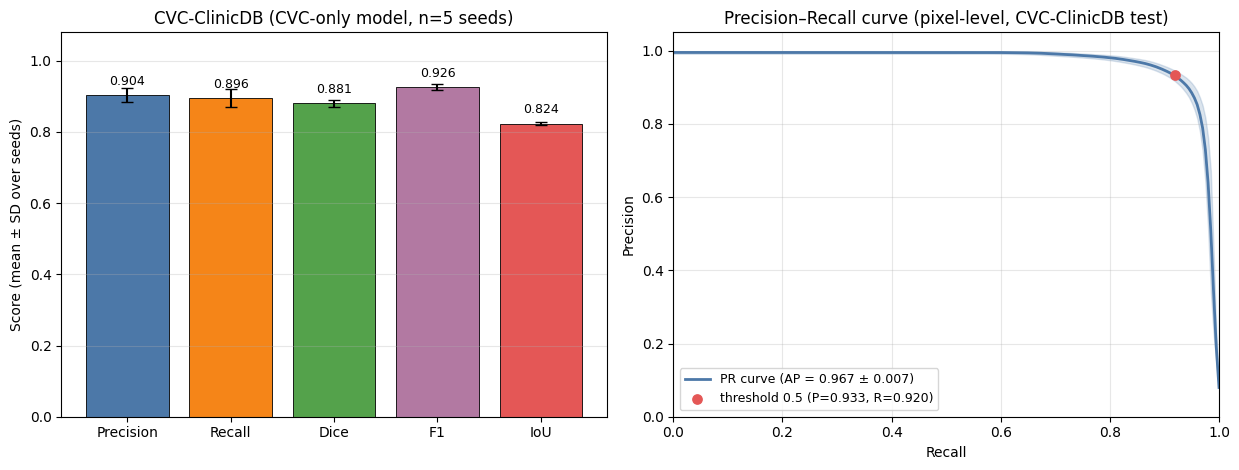

,Precision,Recall,Dice,F1,IoU
mean,0.9041,0.8957,0.8805,0.9259,0.8238
SD,0.0206,0.0254,0.0100,0.0084,0.0055


Saved: fig_cvc_metrics_pr.png / .pdf (notebook wale folder mein)


In [5]:
# ===== X1: CVC-ClinicDB — Precision/Recall/Dice/F1/IoU bar chart + Precision-Recall curve (side by side) =====
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

X1_SET   = "cvc"                                   # CVC-ClinicDB
X1_TAG   = "cvc_main"
X1_BINS  = 1000
X1_CACHE = os.path.join(CVC_DIR, "x1_cache")
os.makedirs(X1_CACHE, exist_ok=True)


def _x1_seed(m, seed):
    cp = os.path.join(X1_CACHE, f"seed{seed}.npz")
    if os.path.exists(cp):
        z = np.load(cp)
        return {k: z[k] for k in z.files}
    ck = f"{CVC_DIR}/{X1_TAG}_seed{seed}.weights.h5"
    if not os.path.exists(ck):
        return None
    m.load_weights(ck)
    X, Y = TEST[X1_SET]
    _, per, probs = evaluate_arrays(m, X, Y, bs=4)
    tp, fp, fn = per["tp"], per["fp"], per["fn"]
    prec_img = np.where(tp + fp > 0, tp / np.maximum(tp + fp, 1), np.nan)
    rec_img = np.where(tp + fn > 0, tp / np.maximum(tp + fn, 1), np.nan)
    yt = (np.asarray(Y).reshape(-1) > 0.5)
    pr = np.asarray(probs, np.float32).reshape(-1)
    edges = np.linspace(0.0, 1.0, X1_BINS + 1)
    h_pos, _ = np.histogram(pr[yt], bins=edges)
    h_neg, _ = np.histogram(pr[~yt], bins=edges)
    out = {"prec_img": prec_img, "rec_img": rec_img, "dice_img": per["dice"], "iou_img": per["iou"],
           "tp": np.array(tp.sum()), "fp": np.array(fp.sum()), "fn": np.array(fn.sum()),
           "h_pos": h_pos, "h_neg": h_neg}
    np.savez(cp, **out)
    return out


def _x1_curve(h_pos, h_neg):
    tp = np.cumsum(h_pos[::-1]).astype(np.float64)
    fp = np.cumsum(h_neg[::-1]).astype(np.float64)
    P = tp / np.maximum(tp + fp, 1)
    R = tp / max(h_pos.sum(), 1)
    ap = float(np.sum(np.diff(np.concatenate([[0.0], R])) * P))
    return R, P, ap


def _x1_main():
    m = build()
    res = {}
    for s in SEEDS:
        r = _x1_seed(m, s)
        if r is None:
            print(f"seed {s}: weights nahi mile -> skip"); continue
        res[s] = r
        print(f"seed {s} done", flush=True)
    import tensorflow as tf
    tf.keras.backend.clear_session()
    if not res:
        print("Koi CVC-only weights nahi mile -> pehle A1 chalayein"); return

    names = ["Precision", "Recall", "Dice", "F1", "IoU"]
    rows = []
    for s, r in res.items():
        tp, fp, fn = float(r["tp"]), float(r["fp"]), float(r["fn"])
        micro_f1 = 2 * tp / max(2 * tp + fp + fn, 1)
        rows.append([np.nanmean(r["prec_img"]), np.nanmean(r["rec_img"]), float(np.mean(r["dice_img"])),
                     micro_f1, float(np.mean(r["iou_img"]))])
    A = np.array(rows)
    mu = A.mean(0)
    sd = A.std(0, ddof=1) if len(A) > 1 else np.zeros(5)

    grid = np.linspace(0, 1, 201)
    P_all, aps = [], []
    for r in res.values():
        R, P, ap = _x1_curve(r["h_pos"], r["h_neg"])
        order = np.argsort(R)
        P_all.append(np.interp(grid, R[order], P[order]))
        aps.append(ap)
    P_all = np.array(P_all)
    Pm = P_all.mean(0)
    Ps = P_all.std(0, ddof=1) if len(P_all) > 1 else np.zeros_like(Pm)
    ap_mu = np.mean(aps); ap_sd = np.std(aps, ddof=1) if len(aps) > 1 else 0.0
    op_p = np.mean([float(r["tp"]) / max(float(r["tp"]) + float(r["fp"]), 1) for r in res.values()])
    op_r = np.mean([float(r["tp"]) / max(float(r["tp"]) + float(r["fn"]), 1) for r in res.values()])

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.8))
    colors = ["#4C78A8", "#F58518", "#54A24B", "#B279A2", "#E45756"]
    bars = ax1.bar(names, mu, yerr=sd, capsize=4, color=colors, edgecolor="black", linewidth=0.6)
    for b, v in zip(bars, mu):
        ax1.text(b.get_x() + b.get_width() / 2, min(v + 0.02, 1.02), f"{v:.3f}", ha="center", va="bottom", fontsize=9)
    ax1.set_ylim(0, 1.08); ax1.set_ylabel("Score (mean ± SD over seeds)")
    ax1.set_title(f"CVC-ClinicDB (CVC-only model, n={len(res)} seeds)")
    ax1.grid(axis="y", alpha=0.3)

    ax2.plot(grid, Pm, lw=2, color="#4C78A8", label=f"PR curve (AP = {ap_mu:.3f} ± {ap_sd:.3f})")
    ax2.fill_between(grid, Pm - Ps, Pm + Ps, color="#4C78A8", alpha=0.2)
    ax2.scatter([op_r], [op_p], color="#E45756", zorder=5, s=45, label=f"threshold 0.5 (P={op_p:.3f}, R={op_r:.3f})")
    ax2.set_xlim(0, 1.0); ax2.set_ylim(0, 1.05)
    ax2.set_xlabel("Recall"); ax2.set_ylabel("Precision")
    ax2.set_title("Precision–Recall curve (pixel-level, CVC-ClinicDB test)")
    ax2.grid(alpha=0.3); ax2.legend(loc="lower left", fontsize=9)
    plt.tight_layout()
    fig.savefig("fig_cvc_metrics_pr.png", dpi=300, bbox_inches="tight")
    fig.savefig("fig_cvc_metrics_pr.pdf", bbox_inches="tight")
    plt.show()

    display(pd.DataFrame({"mean": mu, "SD": sd}, index=names).round(4).T)
    print("Saved: fig_cvc_metrics_pr.png / .pdf (notebook wale folder mein)")


_x1_main()

## Reviewer ke points — kaunsa cell kya dikhata hai
| Point | Cell |
|---|---|
| Train/test leakage (split pehle, aug baad mein, pHash check) | C1 |
| Standard PraNet protocol, per-image mDice/mIoU, published SOTA se comparison | C0 data, A2, C1 (SOTA table) |
| Plain architecture (ResNet-50 U-Net), ablation (frozen / no-ImageNet) | A6 |
| Federated learning: 2 institutions, no warm-start, FedAvg/FedProx/FedBN vs pooled vs local, unseen test sets | B1–B5 |
| Statistics: seed-averaged per-image Dice, paired Wilcoxon + Holm, bootstrap CI, mean ± SD, violin plots | A2, A6, B3, B5 |
| XAI: Grad-CAM++ / LIME + baselines, top-g IoU, AUROC/AUPRC, deletion/insertion, randomisation check, FL models par bhi | A5, B6 |
| Robustness (poora test set, severity 0..5) | A4 |
| Efficiency | A7 |